# 🔢🐼 NumPy and Pandas: The Complete Step-by-Step Notes

A full, in-depth guide to the two libraries at the heart of data science and machine learning in Python. Every topic has a plain-English concept, runnable code, and a short explanation of what the code does.

**How to use this notebook**

1. Read the concept cell.
2. Run the code cell (`Shift + Enter`).
3. Read the **Explanation** cell under it.
4. Change values and re-run. Experimenting is the fastest way to learn.

**Requirements:** Python 3.10+, `numpy`, `pandas`, `matplotlib` (`pip install numpy pandas matplotlib`).
Written for **NumPy 2.x** and **pandas 2.2+ / 3.x**. Notes mark the places where older versions behave differently.

---

## 📑 Table of Contents

### Part A: NumPy

| # | Chapter | Main topics |
|---|---|---|
| 1 | Introduction | Why NumPy, `ndarray` anatomy, speed |
| 2 | Creating Arrays | `array`, `zeros`, `arange`, `linspace`, `eye`, `fromfunction` |
| 3 | Attributes and Data Types | `shape`, `dtype`, `astype`, overflow, `datetime64` |
| 4 | Indexing and Slicing | Views vs copies, boolean masks, fancy indexing, `where` |
| 5 | Array Math and Ufuncs | Operators, universal functions, `reduce`, `accumulate`, `errstate` |
| 6 | Aggregations and Statistics | `sum`, `mean`, `axis`, percentiles, `histogram`, `unique` |
| 7 | Reshaping, Stacking, Splitting | `reshape`, `concatenate`, `split`, `tile`, `meshgrid` |
| 8 | Broadcasting | The rules, normalisation, distance matrices |
| 9 | Sorting, Searching, Sets | `sort`, `argsort`, `searchsorted`, `isin`, `unique` |
| 10 | Random Numbers | `Generator`, distributions, sampling, reproducibility |
| 11 | Linear Algebra | `@`, `inv`, `solve`, `eig`, `svd`, `einsum` |
| 12 | Missing and Special Values | `nan`, `inf`, masked arrays |
| 13 | File I/O | `save`, `load`, `loadtxt`, `savez`, `memmap` |
| 14 | Performance and Memory | Vectorisation, strides, memory layout, dtypes |
| 15 | NumPy Practice | From-scratch ML: normalisation, softmax, regression, PCA |

### Part B: Pandas

| # | Chapter | Main topics |
|---|---|---|
| 16 | Introduction and Series | `Series`, index, alignment, methods |
| 17 | DataFrame Basics | Creation, inspection, `info`, `describe` |
| 18 | Reading and Writing Data | CSV, JSON, Excel, SQL, options |
| 19 | Selecting and Filtering | `loc`, `iloc`, masks, `query`, `where` |
| 20 | Data Cleaning | Missing values, duplicates, types, outliers |
| 21 | Column Operations | `assign`, `apply`, `map`, `cut`, `qcut`, `shift`, `diff` |
| 22 | Strings, Categoricals, Dates | `.str`, `.dt`, `category`, parsing dates |
| 23 | Sorting, Counting, Ranking | `sort_values`, `value_counts`, `nlargest`, `rank` |
| 24 | GroupBy and Aggregation | split-apply-combine, `agg`, `transform`, pivot tables |
| 25 | Combining DataFrames | `concat`, `merge`, `join`, `merge_asof` |
| 26 | Reshaping and MultiIndex | `pivot`, `melt`, `stack`, `explode`, `get_dummies` |
| 27 | Time Series and Windows | `resample`, `rolling`, `expanding`, `ewm` |
| 28 | Visualisation | Plotting directly from pandas |
| 29 | Performance and Best Practices | dtypes, vectorisation, chunking, method chaining |
| 30 | End-to-End Project | Sales analysis from raw data to insights |
| 31 | NumPy + Pandas for ML | Features, encoding, scaling, train/test split |
| 32 | Practice Exercises | Exercises with solutions |
| 33 | Cheat Sheet | Quick reference |

---

# Chapter 1: Introduction to NumPy

**NumPy** (Numerical Python) provides the `ndarray`, a fast, fixed-type, multi-dimensional array, plus hundreds of functions that operate on whole arrays at once. Pandas, scikit-learn, SciPy, PyTorch, TensorFlow and Matplotlib are all built on the same ideas.

**Why not just use Python lists?**

| Python list | NumPy array |
|---|---|
| Holds pointers to separate Python objects | Holds raw numbers packed in one block of memory |
| Items can be different types | All items share one `dtype` |
| Loops run in slow interpreted Python | Operations run in optimised C code |
| No built-in maths on whole list | Operators and functions work element-wise |

## 1.1 Installing and importing

In [1]:
# pip install numpy        (in a notebook: %pip install numpy)
import numpy as np          # the universal alias

print(np.__version__)

2.5.4


**Explanation**

- `import numpy as np` is the convention every Python data tutorial follows.
- `np.__version__` shows the installed version.

## 1.2 A first array

In [2]:
import numpy as np

a = np.array([10, 20, 30, 40])
print(a)
print(type(a))
print(a * 2)               # works on every element
print(a + a)
print(a > 25)

[10 20 30 40]
<class 'numpy.ndarray'>
[20 40 60 80]
[20 40 60 80]
[False False  True  True]


**Explanation**

- `np.array(list)` builds an array from a list.
- Arithmetic and comparisons apply **to every element** with no loop. This is called **vectorisation**.

In [3]:
numbers = [10, 20, 30, 40]
try:
    print(numbers * 2)          # a list REPEATS
    print(numbers + numbers)    # a list CONCATENATES
    print(numbers + 5)
except TypeError as e:
    print("TypeError:", e)

[10, 20, 30, 40, 10, 20, 30, 40]
[10, 20, 30, 40, 10, 20, 30, 40]
TypeError: can only concatenate list (not "int") to list


**Explanation**

- Operators mean different things for lists and arrays: `list * 2` repeats, `array * 2` multiplies every element. Adding a number to a list is an error.

## 1.3 How much faster is it?

In [4]:
import numpy as np, timeit

size = 1_000_000
py_list = list(range(size))
np_arr = np.arange(size)

t_list = timeit.timeit(lambda: [x * 2 for x in py_list], number=10)
t_np = timeit.timeit(lambda: np_arr * 2, number=10)
print(f"list comprehension: {t_list:.4f}s")
print(f"numpy             : {t_np:.4f}s")
print(f"numpy is about {t_list / t_np:.0f}x faster")

t_sum_list = timeit.timeit(lambda: sum(py_list), number=10)
t_sum_np = timeit.timeit(lambda: np_arr.sum(), number=10)
print(f"sum: list {t_sum_list:.4f}s vs numpy {t_sum_np:.4f}s")

list comprehension: 0.4384s
numpy             : 0.0087s
numpy is about 51x faster
sum: list 0.0768s vs numpy 0.0047s


**Explanation**

- The same task on a million numbers is dozens of times faster with NumPy because the loop runs in compiled C and the data sits contiguously in memory.
- Exact speed-ups depend on your machine.

## 1.4 Memory: lists vs arrays

In [5]:
import numpy as np, sys

n = 100_000
py_list = list(range(n))
np_arr = np.arange(n)           # default int64: 8 bytes each

list_bytes = sys.getsizeof(py_list) + sum(sys.getsizeof(x) for x in py_list)
print("list bytes :", list_bytes)
print("array bytes:", np_arr.nbytes)
print("int8 array :", np.arange(n, dtype=np.int8).nbytes, "(only valid for small numbers)")

list bytes : 3600056
array bytes: 800000
int8 array : 100000 (only valid for small numbers)


**Explanation**

- A list stores pointers plus a full Python object for every number. An array stores only the raw numbers, so it is several times smaller.
- Choosing a smaller `dtype` shrinks memory further (as long as the values fit).

## 1.5 Anatomy of an `ndarray`

An array is made of:

1. **A data buffer**: one contiguous block of memory holding the values.
2. **A dtype**: how to interpret the bytes (`int64`, `float32`, ...).
3. **A shape**: the size of each dimension, e.g. `(3, 4)`.
4. **Strides**: how many bytes to skip to move to the next item along each dimension.

Reshaping, transposing and slicing usually only change the **shape and strides**, not the data. That is why they are almost free, and why they return **views** of the same memory.

In [6]:
import numpy as np

m = np.arange(12).reshape(3, 4)
print(m)
print("shape  :", m.shape)
print("dtype  :", m.dtype)
print("strides:", m.strides, "-> 32 bytes to the next row, 8 bytes to the next column")
print("ndim   :", m.ndim, "| size:", m.size, "| itemsize:", m.itemsize, "| nbytes:", m.nbytes)

t = m.T                                   # transpose: only strides change
print(t.strides, np.shares_memory(m, t))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape  : (3, 4)
dtype  : int64
strides: (32, 8) -> 32 bytes to the next row, 8 bytes to the next column
ndim   : 2 | size: 12 | itemsize: 8 | nbytes: 96
(8, 32) True


**Explanation**

- `strides` shows how NumPy walks through memory; the transpose swaps the strides and copies nothing (`shares_memory` is `True`).

---

# Chapter 2: Creating Arrays

There are many ways to build an array: from existing data, from fixed values, from ranges, from patterns and from random numbers.

## 2.1 From Python data: `array`, `asarray`

In [7]:
import numpy as np

a1 = np.array([1, 2, 3])                       # 1D
a2 = np.array([[1, 2, 3], [4, 5, 6]])          # 2D (matrix)
a3 = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])   # 3D
print(a1.ndim, a2.ndim, a3.ndim)
print(a2)

print(np.array([1, 2.5, 3]))                   # mixed int/float -> all float
print(np.array([1, "a"]))                      # mixed with text -> all strings
print(np.array([1, 2, 3], dtype=float))        # force a dtype
print(np.array((1, 2, 3)), np.array(range(4)))
print(np.array(5), np.array(5).ndim)           # 0-dimensional (scalar array)

orig = np.array([1, 2, 3])
c = np.array(orig)                             # makes a copy
v = np.asarray(orig)                           # no copy if already an array
print(c is orig, v is orig)

1 2 3
[[1 2 3]
 [4 5 6]]
[1.  2.5 3. ]
['1' 'a']
[1. 2. 3.]
[1 2 3] [0 1 2 3]
5 0
False True


**Explanation**

- Nested lists become higher-dimensional arrays; every inner list must have the same length.
- NumPy picks one dtype that fits **all** items (ints become floats, numbers become strings when mixed with text).
- `np.array` copies by default; `np.asarray` reuses the data when possible.

## 2.2 Filled arrays: `zeros`, `ones`, `full`, `empty`

In [8]:
import numpy as np

print(np.zeros(5))
print(np.zeros((2, 3)))                    # shape is passed as a tuple
print(np.ones((2, 2), dtype=int))
print(np.full((2, 3), 7.5))
print(np.full(4, np.nan))

e = np.empty((2, 2))                       # uninitialised: contains garbage values
e.fill(0)                                  # fill every element
print(e)

base = np.array([[1, 2], [3, 4]])
print(np.zeros_like(base), np.ones_like(base), np.full_like(base, 9))

[0. 0. 0. 0. 0.]
[[0. 0. 0.]
 [0. 0. 0.]]
[[1 1]
 [1 1]]
[[7.5 7.5 7.5]
 [7.5 7.5 7.5]]
[nan nan nan nan]
[[0. 0.]
 [0. 0.]]
[[0 0]
 [0 0]] [[1 1]
 [1 1]] [[9 9]
 [9 9]]


**Explanation**

- The shape is a **tuple** `(rows, columns)`. Default dtype is `float64`.
- `np.empty` is fastest because it does not set values; always overwrite them before use.
- The `*_like` functions copy shape and dtype from another array.

## 2.3 Ranges: `arange`, `linspace`, `logspace`

In [9]:
import numpy as np

print(np.arange(5))                  # 0..4
print(np.arange(2, 10, 3))           # start, stop (exclusive), step
print(np.arange(0, 1, 0.25))
print(np.arange(5, 0, -1))

print(np.linspace(0, 1, 5))                   # 5 evenly spaced points, endpoint included
print(np.linspace(0, 1, 5, endpoint=False))   # exclude the last point
print(np.linspace(0, 10, 4, retstep=True))    # also return the step size
print(np.logspace(0, 3, 4))                   # 10**0 .. 10**3
print(np.geomspace(1, 1000, 4))               # geometric spacing

# Why linspace is safer than arange for floats
print(len(np.arange(0, 1, 0.1)), len(np.linspace(0, 1, 11)))

[0 1 2 3 4]
[2 5 8]
[0.   0.25 0.5  0.75]
[5 4 3 2 1]
[0.   0.25 0.5  0.75 1.  ]
[0.  0.2 0.4 0.6 0.8]
(array([ 0.        ,  3.33333333,  6.66666667, 10.        ]), np.float64(3.3333333333333335))
[   1.   10.  100. 1000.]
[   1.   10.  100. 1000.]
10 11


**Explanation**

- `arange(start, stop, step)` is like `range` but also accepts floats. `stop` is **excluded**.
- `linspace(start, stop, num)` fixes the **number of points** and **includes** the end, which avoids floating-point surprises of `arange` with float steps.

## 2.4 Identity and diagonal arrays

In [10]:
import numpy as np

print(np.eye(3))                        # 1s on the diagonal
print(np.eye(3, 4, k=1))                # shifted diagonal
print(np.identity(2))
print(np.diag([1, 2, 3]))               # build a diagonal matrix
m = np.arange(9).reshape(3, 3)
print(np.diag(m))                       # extract the diagonal
print(np.triu(m))                       # upper triangle
print(np.tril(m))                       # lower triangle

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[1. 0.]
 [0. 1.]]
[[1 0 0]
 [0 2 0]
 [0 0 3]]
[0 4 8]
[[0 1 2]
 [0 4 5]
 [0 0 8]]
[[0 0 0]
 [3 4 0]
 [6 7 8]]


**Explanation**

- `eye` / `identity` create identity matrices. `diag` builds a diagonal matrix from a 1D array, or extracts the diagonal from a 2D array. `triu` / `tril` keep the upper / lower triangle.

## 2.5 From functions and iterators

In [11]:
import numpy as np

print(np.fromfunction(lambda i, j: i * 10 + j, (3, 4), dtype=int))   # value from the indices
print(np.fromiter((x * x for x in range(5)), dtype=int))
print(np.array([[i * j for j in range(1, 4)] for i in range(1, 4)]))  # multiplication table
print(np.indices((2, 3)))                                              # index grids
print(np.arange(1, 7).reshape(2, 3))

[[ 0  1  2  3]
 [10 11 12 13]
 [20 21 22 23]]
[ 0  1  4  9 16]
[[1 2 3]
 [2 4 6]
 [3 6 9]]
[[[0 0 0]
  [1 1 1]]

 [[0 1 2]
  [0 1 2]]]
[[1 2 3]
 [4 5 6]]


**Explanation**

- `fromfunction(f, shape)` calls `f` with index arrays and builds the array from the result.
- `fromiter` builds an array from any iterator or generator without creating a list first.

## 2.6 Copies

In [12]:
import numpy as np

a = np.array([1, 2, 3])
b = a                      # same array (alias)
c = a.copy()               # independent copy
b[0] = 99
print(a, c)

[99  2  3] [1 2 3]


**Explanation**

- `b = a` does **not** copy. Use `.copy()` whenever you need an independent array.

---

# Chapter 3: Array Attributes and Data Types

Every array knows its shape, size and element type. Choosing the right `dtype` affects memory, speed and numerical accuracy.

## 3.1 Attributes

In [13]:
import numpy as np

a = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)
print("shape    :", a.shape)
print("ndim     :", a.ndim)
print("size     :", a.size, "(total elements)")
print("len      :", len(a), "(length of the first axis)")
print("dtype    :", a.dtype)
print("itemsize :", a.itemsize, "bytes per element")
print("nbytes   :", a.nbytes, "bytes in total")
print("T        :", a.T.shape)
print("flags    :", a.flags.c_contiguous, a.flags.writeable)
print("real/imag:", a.real.shape)

shape    : (2, 3)
ndim     : 2
size     : 6 (total elements)
len      : 2 (length of the first axis)
dtype    : float32
itemsize : 4 bytes per element
nbytes   : 24 bytes in total
T        : (3, 2)
flags    : True True
real/imag: (2, 3)


**Explanation**

- `shape` is a tuple, `ndim` the number of dimensions, `size` the total element count. `len()` returns only the first dimension.
- `itemsize * size = nbytes`.

## 3.2 Common data types

| Type | Aliases | Range / meaning |
|---|---|---|
| `int8`, `int16`, `int32`, `int64` | `np.int_` | signed integers (8, 16, 32, 64 bits) |
| `uint8`, `uint16`, `uint32`, `uint64` | | unsigned integers (0 and up) |
| `float16`, `float32`, `float64` | `np.float64` = Python `float` | decimals, 16/32/64 bits |
| `complex64`, `complex128` | | complex numbers |
| `bool` | `np.bool_` | `True` / `False` |
| `str_` (`U`), `bytes_` (`S`) | | fixed-width text |
| `datetime64`, `timedelta64` | | dates and durations |
| `object` | | any Python objects (slow, avoid) |

In [14]:
import numpy as np

print(np.array([1, 2, 3]).dtype)            # int64 on most systems
print(np.array([1.0, 2.0]).dtype)           # float64
print(np.array([True, False]).dtype)
print(np.array(["ab", "cde"]).dtype)        # <U3: unicode, max 3 characters
print(np.array([1, 2, 3], dtype="int8").dtype)
print(np.array([1, 2], dtype=np.float32).dtype)
print(np.array([1 + 2j]).dtype)

# Limits of each type
print(np.iinfo(np.int8), np.iinfo(np.int32).max)
print(np.finfo(np.float32))
print(np.finfo(np.float64).eps)

int64
float64
bool
<U3
int8
float32
complex128
Machine parameters for int8
---------------------------------------------------------------
min = -128
max = 127
---------------------------------------------------------------
 2147483647
Machine parameters for float32
---------------------------------------------------------------
precision = 6   resolution = 1e-06
machep = -23   eps =        1.1920929e-07
negep =  -24   epsneg =     5.9604645e-08
minexp = -126   tiny =       1.1754944e-38
maxexp = 128   max =        3.4028235e+38
nexp =   8   min =        -max
smallest_normal = 1.1754944e-38   smallest_subnormal = 1e-45
---------------------------------------------------------------

2.220446049250313e-16


**Explanation**

- `iinfo` gives integer ranges; `finfo` gives float precision (`eps` is the smallest relative difference).
- `float32` has about 7 decimal digits of precision, `float64` about 16.

## 3.3 Converting types with `astype`

In [15]:
import numpy as np

f = np.array([1.7, -2.3, 3.9])
print(f.astype(int))                 # truncates toward zero: [ 1 -2  3]
print(np.round(f).astype(int))       # round first if you want rounding
print(f.astype(np.float32))
print(f.astype(bool))                # non-zero -> True
print(np.array(["1", "2", "3"]).astype(int))
print(np.array([1, 2, 3]).astype(str))

a = np.array([1, 2, 3])
b = a.astype(float)                  # astype always returns a COPY
b[0] = 100
print(a, b)

[ 1 -2  3]
[ 2 -2  4]
[ 1.7 -2.3  3.9]
[ True  True  True]
[1 2 3]
['1' '2' '3']
[1 2 3] [100.   2.   3.]


**Explanation**

- `astype` returns a **new** array. Converting float to int truncates, it does not round.

## 3.4 Integer overflow and float precision

In [16]:
import numpy as np

x = np.array([250, 255], dtype=np.uint8)
print(x + 10)                        # wraps around: 260 -> 4, 265 -> 9 (no error!)

y = np.array([127], dtype=np.int8)
print(y + 1)                         # -128

print(np.int64(2) ** 62, np.int64(2) ** 63)     # overflow wraps silently

# Safe approach: use a wider type
print(x.astype(np.int32) + 10)

print(np.float32(0.1) + np.float32(0.2))
print(np.float64(0.1) + np.float64(0.2))
print(np.float32(16777216) + np.float32(1))     # float32 cannot represent every integer

[4 9]
[-128]
4611686018427387904 -9223372036854775808
[260 265]
0.3
0.30000000000000004
1.6777216e+07


**Explanation**

- Integer arrays **wrap around silently** on overflow, so pick a dtype large enough for your results.
- `float32` halves memory but loses precision. Deep learning often uses it deliberately; scientific code usually keeps `float64`.

## 3.5 Type promotion

In [17]:
import numpy as np

print((np.array([1, 2]) + 1.5).dtype)                 # int + float -> float64
print((np.array([1, 2], dtype=np.int8) + np.array([1, 2], dtype=np.int16)).dtype)  # -> int16
print((np.array([1, 2]) / 2).dtype)                   # true division -> float
print((np.array([True, False]) + 1).dtype)            # bool + int -> int
print(np.result_type(np.int32, np.float32))
print(np.promote_types("int8", "float16"))
print(np.can_cast(np.int64, np.int32, casting="safe"))

float64
int16
float64
int64
float64
float16
False


**Explanation**

- When types are mixed, NumPy converts to the smallest type that can hold both. `result_type` and `promote_types` let you ask in advance.

## 3.6 Dates and times: `datetime64`

In [18]:
import numpy as np

d = np.datetime64("2025-03-15")
print(d, d.dtype)
print(d + np.timedelta64(10, "D"))               # adds 10 days
print(np.datetime64("2025-03-15T10:30"))
days = np.arange("2025-01-01", "2025-01-08", dtype="datetime64[D]")
print(days)
print(days[-1] - days[0], (days[-1] - days[0]).astype(int))
print(np.timedelta64(5, "h"), np.timedelta64(90, "m") / np.timedelta64(1, "h"))
print(days.astype("datetime64[M]"))              # truncate to months
print(np.is_busday("2025-03-15"), np.busday_count("2025-03-01", "2025-04-01"))

2025-03-15 datetime64[D]
2025-03-25
2025-03-15T10:30
['2025-01-01' '2025-01-02' '2025-01-03' '2025-01-04' '2025-01-05'
 '2025-01-06' '2025-01-07']
6 days 6
5 hours 1.5
['2025-01' '2025-01' '2025-01' '2025-01' '2025-01' '2025-01' '2025-01']
False 21


**Explanation**

- `datetime64[unit]` stores dates as integers with a unit (`Y`, `M`, `D`, `h`, `m`, `s`...). Subtracting two dates gives a `timedelta64`.
- Pandas (Chapter 22) builds richer date tools on top of this.

## 3.7 Structured arrays and `object` dtype

In [19]:
import numpy as np

people = np.array([("Ann", 30, 55.5), ("Bob", 25, 70.2)],
                  dtype=[("name", "U10"), ("age", "i4"), ("weight", "f8")])
print(people)
print(people["name"], people["age"].mean())
print(people[people["age"] > 26])

obj = np.array([1, "a", [1, 2]], dtype=object)       # can hold anything, loses speed
print(obj, obj.dtype)

[('Ann', 30, 55.5) ('Bob', 25, 70.2)]
['Ann' 'Bob'] 27.5
[('Ann', 30, 55.5)]
[1 'a' list([1, 2])] object


**Explanation**

- **Structured arrays** give each column a name and type, like a tiny table. In practice use Pandas for tables.
- `dtype=object` stores Python objects; it removes the speed advantage, so avoid it for numeric work.

---

# Chapter 4: Indexing and Slicing

Indexing selects elements. NumPy supports basic indexing (integers and slices, which return **views**) and advanced indexing (boolean masks and index arrays, which return **copies**).

## 4.1 One-dimensional arrays

In [20]:
import numpy as np

a = np.array([10, 20, 30, 40, 50, 60])
print(a[0], a[-1], a[2])
print(a[1:4])         # [20 30 40]   stop excluded
print(a[:3], a[3:])
print(a[::2])         # every second item
print(a[::-1])        # reversed
print(a[-3:])
print(a[1:-1])

10 60 30
[20 30 40]
[10 20 30] [40 50 60]
[10 30 50]
[60 50 40 30 20 10]
[40 50 60]
[20 30 40 50]


**Explanation**

- Slicing syntax is identical to Python lists: `a[start:stop:step]`.

## 4.2 Two- and three-dimensional arrays

In [21]:
import numpy as np

m = np.arange(1, 13).reshape(3, 4)
print(m)
print(m[0, 0], m[1, 2], m[-1, -1])
print(m[1])             # a whole row
print(m[:, 1])          # a whole column
print(m[0:2, 1:3])      # sub-matrix
print(m[::2, ::2])      # every other row and column
print(m[:, -1])         # last column
print(m[[0, 2], :])     # rows 0 and 2

cube = np.arange(24).reshape(2, 3, 4)       # 2 blocks, 3 rows, 4 columns
print(cube[1, 2, 3], cube[0].shape, cube[:, 0, :].shape)
print(cube[..., 0])     # Ellipsis: "all remaining dimensions"

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
1 7 12
[5 6 7 8]
[ 2  6 10]
[[2 3]
 [6 7]]
[[ 1  3]
 [ 9 11]]
[ 4  8 12]
[[ 1  2  3  4]
 [ 9 10 11 12]]
23 (3, 4) (2, 4)
[[ 0  4  8]
 [12 16 20]]


**Explanation**

- Use **one index per dimension**, separated by commas: `m[row, column]`. A bare `:` means "all".
- `m[1]` is shorthand for `m[1, :]`. `...` (Ellipsis) fills in all the dimensions you did not name.

## 4.3 Views and copies

In [22]:
import numpy as np

a = np.arange(6)
view = a[1:4]                     # basic slice -> VIEW (shares memory)
view[0] = 99
print(a)                          # a changed too!
print(np.shares_memory(a, view), view.base is a)

b = np.arange(6)
copy = b[1:4].copy()              # explicit copy
copy[0] = 99
print(b)

c = np.arange(6)
fancy = c[[1, 2, 3]]              # fancy indexing -> COPY
fancy[0] = 99
print(c)

# Slicing a view lets you modify a region in place
m = np.zeros((3, 3), dtype=int)
m[1:, 1:] = 5
print(m)

[ 0 99  2  3  4  5]
True True
[0 1 2 3 4 5]
[0 1 2 3 4 5]
[[0 0 0]
 [0 5 5]
 [0 5 5]]


**Explanation**

- **Basic slices are views**: changing them changes the original. Call `.copy()` to detach.
- **Fancy and boolean indexing return copies.**
- Assigning to a slice (`m[1:, 1:] = 5`) writes into the original array.

## 4.4 Boolean (mask) indexing

In [23]:
import numpy as np

a = np.array([5, 12, 8, 21, 3, 17])
mask = a > 10
print(mask)                         # array of True/False
print(a[mask])                      # keep elements where True
print(a[a > 10])                    # usual one-liner
print(a[(a > 5) & (a < 20)])        # AND  (use &, not 'and'; parentheses are required)
print(a[(a < 5) | (a > 20)])        # OR
print(a[~(a > 10)])                 # NOT
print(a[a % 2 == 0])                # even numbers

a2 = a.copy()
a2[a2 > 10] = 0                     # assign through a mask
print(a2)
print((a > 10).sum(), (a > 10).mean())   # count and fraction of True

m = np.array([[1, -2], [-3, 4]])
m[m < 0] = 0
print(m)

[False  True False  True False  True]
[12 21 17]
[12 21 17]
[12  8 17]
[21  3]
[5 8 3]
[12  8]
[5 0 8 0 3 0]
3 0.5
[[1 0]
 [0 4]]


**Explanation**

- A comparison creates a boolean array; using it as an index selects the `True` positions.
- Combine conditions with `&`, `|`, `~` (not `and`, `or`, `not`) and put each condition in parentheses.
- `True` counts as 1, so `.sum()` counts matches and `.mean()` gives the proportion.

## 4.5 Fancy indexing (index arrays)

In [24]:
import numpy as np

a = np.array([10, 20, 30, 40, 50])
idx = [0, 3, 3, 1]
print(a[idx])                           # pick in any order, repeats allowed
print(a[np.array([[0, 1], [2, 3]])])    # result takes the shape of the index array

m = np.arange(12).reshape(3, 4)
print(m[[0, 2], [1, 3]])                # pairs: (0,1) and (2,3)
print(m[np.ix_([0, 2], [1, 3])])        # all combinations: rows 0,2 x columns 1,3
print(m[:, [0, 2]])                     # selected columns
print(m[[2, 0]])                        # reordered rows

a[[0, 4]] = [-1, -5]                    # assign with index arrays
print(a)
print(np.take(m, [0, 5, 11]))           # index into the flattened array
rows = np.arange(3)
cols = np.array([1, 0, 3])
print(m[rows, cols])                    # one element from each row

[10 40 40 20]
[[10 20]
 [30 40]]
[ 1 11]
[[ 1  3]
 [ 9 11]]
[[ 0  2]
 [ 4  6]
 [ 8 10]]
[[ 8  9 10 11]
 [ 0  1  2  3]]
[-1 20 30 40 -5]
[ 0  5 11]
[ 1  4 11]


**Explanation**

- Passing lists or arrays of integers picks those positions (repeats and any order allowed).
- With two index arrays NumPy pairs them element by element; `np.ix_` builds the **cross product** (a sub-grid).

## 4.6 `np.where`, `nonzero`, `argwhere`

In [25]:
import numpy as np

a = np.array([4, -1, 7, -3, 0, 9])

print(np.where(a > 0, "pos", "non-pos"))           # if-else per element
print(np.where(a < 0, 0, a))                       # replace negatives with 0
print(np.where(a > 0))                             # positions of True (a tuple of arrays)
print(np.nonzero(a)[0])                            # indices of non-zero values
print(np.argwhere(a > 4).ravel())                  # indices as column vectors
print(np.select([a < 0, a == 0, a > 0], ["neg", "zero", "pos"], default="other"))   # several conditions
print(np.clip(a, 0, 5))                            # limit values to a range
print(np.piecewise(a, [a < 0, a >= 0], [lambda x: -x, lambda x: x * 2]))

m = np.array([[1, 5], [7, 2]])
rows, cols = np.where(m > 4)
print(rows, cols)
print(np.extract(a > 0, a))

['pos' 'non-pos' 'pos' 'non-pos' 'non-pos' 'pos']
[4 0 7 0 0 9]
(array([0, 2, 5]),)
[0 1 2 3 5]
[2 5]
['pos' 'neg' 'pos' 'neg' 'zero' 'pos']
[4 0 5 0 0 5]
[ 8  1 14  3  0 18]
[0 1] [1 0]
[4 7 9]


**Explanation**

- `np.where(cond, x, y)` is a vectorised `x if cond else y`. With only a condition it returns the **indices** of the true values.
- `np.select` handles several conditions in order, like `elif`; `default=` is used when none match (it must be the same kind of value as the choices).

## 4.7 `newaxis`, `take_along_axis`, `s_`

In [26]:
import numpy as np

a = np.array([1, 2, 3])
print(a.shape, a[np.newaxis, :].shape, a[:, np.newaxis].shape)   # (3,) (1,3) (3,1)
print(a[:, None] * a[None, :])                                   # None is the same as newaxis

m = np.array([[30, 10, 20], [3, 1, 2]])
order = np.argsort(m, axis=1)
print(np.take_along_axis(m, order, axis=1))                      # sort each row

sl = np.s_[1:3, ::2]                  # build a slice object once, reuse it
print(sl, np.arange(12).reshape(3, 4)[sl])

print(np.diag_indices(3))
x = np.zeros((3, 3), int)
x[np.diag_indices(3)] = 1
print(x)

(3,) (1, 3) (3, 1)
[[1 2 3]
 [2 4 6]
 [3 6 9]]
[[10 20 30]
 [ 1  2  3]]
(slice(1, 3, None), slice(None, None, 2)) [[ 4  6]
 [ 8 10]]
(array([0, 1, 2]), array([0, 1, 2]))
[[1 0 0]
 [0 1 0]
 [0 0 1]]


**Explanation**

- `np.newaxis` (or `None`) inserts a length-1 dimension, essential for broadcasting.
- `np.s_[...]` lets you store a slice in a variable.

---

# Chapter 5: Array Math and Universal Functions

A **universal function (ufunc)** is a function that works element by element on whole arrays. All the operators (`+`, `-`, `*`, ...) and functions like `np.sqrt` are ufuncs.

## 5.1 Arithmetic

In [27]:
import numpy as np

a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])

print(a + b, a - b, a * b)           # element-wise (NOT matrix multiplication)
print(b / a, b // 3, b % 7)
print(a ** 2, 2 ** a)
print(-a, abs(-a))
print(a + 100, a * 0.5)              # scalar applies to every element
print(np.add(a, b), np.multiply(a, b), np.power(a, 3))   # function forms
print(np.divide(7, 2), np.floor_divide(7, 2), np.mod(-7, 3), np.remainder(7, 3))
print(np.reciprocal(np.array([2.0, 4.0])), np.negative(a))
print(np.divmod(np.array([7, 8]), 3))

[11 22 33 44] [ -9 -18 -27 -36] [ 10  40  90 160]
[10. 10. 10. 10.] [ 3  6 10 13] [3 6 2 5]
[ 1  4  9 16] [ 2  4  8 16]
[-1 -2 -3 -4] [1 2 3 4]
[101 102 103 104] [0.5 1.  1.5 2. ]
[11 22 33 44] [ 10  40  90 160] [ 1  8 27 64]
3.5 3 2 1
[0.5  0.25] [-1 -2 -3 -4]
(array([2, 2]), array([1, 2]))


**Explanation**

- Arrays of the same shape combine **element by element**. `*` is **not** matrix multiplication (use `@`, Chapter 11).
- Each operator has a function form (`np.add`, `np.multiply`, ...).

In [28]:
import numpy as np

a = np.array([1, 2, 3])
a += 10                    # in place: modifies the existing array
a *= 2
print(a)

x = np.arange(5)
y = x + 1                  # creates a new array
out = np.empty(5, dtype=int)
np.add(x, 1, out=out)      # write the result into an existing array (no new allocation)
print(out)

try:
    z = np.arange(3)
    z += 0.5               # cannot store floats in an int array in place
except Exception as e:
    print(type(e).__name__, e)

[22 24 26]
[1 2 3 4 5]
UFuncTypeError Cannot cast ufunc 'add' output from dtype('float64') to dtype('int64') with casting rule 'same_kind'


**Explanation**

- Augmented assignment (`+=`) updates the array in place and is memory-efficient, but the result must fit the existing dtype.
- Many ufuncs accept `out=` to reuse memory.

## 5.2 Comparison and logical operations

In [29]:
import numpy as np

a = np.array([1, 5, 9, 3])
b = np.array([2, 5, 7, 3])

print(a == b, a != b, a < b, a >= b)
print(np.array_equal(a, b), np.array_equal(a, a.copy()))
print(np.logical_and(a > 2, b < 8), np.logical_or(a > 8, b < 3), np.logical_not(a > 2))
print(np.logical_xor(a > 2, b > 4))
print((a > 2).any(), (a > 2).all(), np.any(a == 5), np.all(a > 0))
print(np.maximum(a, b), np.minimum(a, b))            # element-wise max/min

x = np.array([0.1 + 0.2, 1.0])
print(x == [0.3, 1.0])                                # floating-point trap
print(np.isclose(x, [0.3, 1.0]), np.allclose(x, [0.3, 1.0]))
print(np.isclose(100.0, 100.4, rtol=0, atol=0.5))

try:
    if a > 2:                                         # truth value of an array is ambiguous
        pass
except ValueError as e:
    print("ValueError:", e)

[False  True False  True] [ True False  True False] [ True False False False] [False  True  True  True]
False True
[False  True  True  True] [ True False  True False] [ True False False False]
[False False False  True]
True False True True
[2 5 9 3] [1 5 7 3]
[False  True]
[ True  True] True
True
ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


**Explanation**

- `==`, `<`, ... return boolean arrays. Use `np.array_equal` to compare whole arrays, `.any()` / `.all()` for reductions.
- Never compare floats with `==`; use `np.isclose` / `np.allclose`.
- `if array:` is ambiguous and raises an error; use `.any()` or `.all()`.
- `np.maximum(a, b)` is element-wise; `np.max(a)` reduces a single array.

## 5.3 Mathematical functions

In [30]:
import numpy as np

x = np.array([1.0, 4.0, 9.0, 16.0])
print(np.sqrt(x), np.cbrt(np.array([8, 27])), np.square(x))
print(np.exp(np.array([0, 1, 2])), np.expm1(1e-5))
print(np.log(np.array([1, np.e, 10])), np.log10(1000), np.log2(8), np.log1p(1e-5))

angles = np.array([0, np.pi / 6, np.pi / 2])
print(np.sin(angles), np.cos(angles).round(3), np.tan(np.array([0, np.pi / 4])).round(3))
print(np.degrees(np.pi), np.radians(90), np.deg2rad(180))
print(np.arctan2(1, 1), np.arcsin(1), np.hypot(3, 4))
print(np.sinh(1), np.tanh(np.array([-1, 0, 1])))
print(np.sign(np.array([-5, 0, 3])), np.abs(np.array([-2.5, 2.5])))
print(np.gcd(12, 18), np.lcm(4, 6))
print(np.exp(1) == np.e, np.pi)

# Sigmoid and softplus: classic building blocks for machine learning
z = np.array([-2.0, 0.0, 2.0])
print(1 / (1 + np.exp(-z)))
print(np.log1p(np.exp(z)))

[1. 2. 3. 4.] [2. 3.] [  1.  16.  81. 256.]
[1.         2.71828183 7.3890561 ] 1.0000050000166668e-05
[0.         1.         2.30258509] 3.0 3.0 9.999950000333332e-06
[0.  0.5 1. ] [1.    0.866 0.   ] [0. 1.]
180.0 1.5707963267948966 3.141592653589793
0.7853981633974483 1.5707963267948966 5.0
1.1752011936438014 [-0.76159416  0.          0.76159416]
[-1  0  1] [2.5 2.5]
6 12
True 3.141592653589793
[0.11920292 0.5        0.88079708]
[0.12692801 0.69314718 2.12692801]


**Explanation**

- All the usual maths functions are available as ufuncs: roots, powers, exponentials, logarithms, trigonometry (in **radians**), hyperbolic functions.
- `expm1` and `log1p` are more accurate than `exp(x) - 1` and `log(1 + x)` for tiny values.

## 5.4 Rounding

In [31]:
import numpy as np

x = np.array([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5, 2.675])
print(np.round(x))                   # ties go to the nearest EVEN number
print(np.round(x, 1))
print(np.floor(x), np.ceil(x), np.trunc(x), np.rint(x))
print(np.round(1234.567, -2))        # round to hundreds
print(np.modf(np.array([1.25, -3.75])))   # fractional and integer parts

[-2. -2. -0.  0.  2.  2.  3.]
[-2.5 -1.5 -0.5  0.5  1.5  2.5  2.7]
[-3. -2. -1.  0.  1.  2.  2.] [-2. -1. -0.  1.  2.  3.  3.] [-2. -1. -0.  0.  1.  2.  2.] [-2. -2. -0.  0.  2.  2.  3.]
1200.0
(array([ 0.25, -0.75]), array([ 1., -3.]))


**Explanation**

- `round` uses banker's rounding (half to even). `floor` goes down, `ceil` goes up, `trunc` cuts toward zero.
- A negative `decimals` rounds to tens, hundreds, etc.

## 5.5 `reduce`, `accumulate`, `outer`, `at`

In [32]:
import numpy as np

a = np.array([1, 2, 3, 4])

print(np.add.reduce(a))                   # same as a.sum()
print(np.multiply.reduce(a))              # product: 24
print(np.add.accumulate(a))               # running total  [ 1  3  6 10]
print(np.multiply.accumulate(a))          # running product
print(np.maximum.accumulate(np.array([3, 1, 4, 1, 5, 2])))   # running maximum
print(np.add.outer([1, 2, 3], [10, 20]))  # every pairwise combination
print(np.multiply.outer([1, 2, 3], [1, 2, 3]))   # multiplication table

b = np.zeros(4, dtype=int)
np.add.at(b, [0, 0, 2], 1)                # unbuffered: repeated indexes accumulate
print(b)
b2 = np.zeros(4, dtype=int)
b2[[0, 0, 2]] += 1                        # buffered: repeated index counted once!
print(b2)

10


24
[ 1  3  6 10]
[ 1  2  6 24]
[3 3 4 4 5 5]
[[11 21]
 [12 22]
 [13 23]]
[[1 2 3]
 [2 4 6]
 [3 6 9]]
[2 0 1 0]
[1 0 1 0]


**Explanation**

- Every binary ufunc has `.reduce` (collapse to one value), `.accumulate` (running result), `.outer` (all pairs).
- `np.add.at` correctly handles **repeated indexes**, unlike `b[idx] += 1`.

## 5.6 Floating-point errors with `errstate`

In [33]:
import numpy as np

a = np.array([1.0, 0.0, -1.0])
with np.errstate(divide="ignore", invalid="ignore"):
    print(1 / a)                       # [ inf  inf -inf]  (no warning)
    print(a / a)                       # [ 1. nan  1.]
    print(np.log(a))

try:
    with np.errstate(all="raise"):     # turn warnings into exceptions
        1 / a
except FloatingPointError as e:
    print("FloatingPointError:", e)

with np.errstate(divide="ignore"):
    print(np.array([5]) // np.array([0]))  # integer division by zero gives 0 (and normally a warning)
print(np.sqrt(np.array([-1.0 + 0j])))  # use complex input for negative roots

[ 1. inf -1.]
[ 1. nan  1.]
[  0. -inf  nan]
FloatingPointError: divide by zero encountered in divide
[0]
[0.+1.j]


**Explanation**

- Float division by zero gives `inf` / `nan` and a warning rather than an exception.
- `np.errstate` controls what happens (`"ignore"`, `"warn"`, `"raise"`) just for the code inside the block.

## 5.7 Applying your own functions

In [34]:
import numpy as np, timeit

def collatz_steps(n):
    steps = 0
    while n != 1:
        n = n // 2 if n % 2 == 0 else 3 * n + 1
        steps += 1
    return steps

v = np.vectorize(collatz_steps)          # convenience wrapper, NOT faster than a loop
print(v(np.array([6, 7, 27])))

# Prefer true vectorised expressions
x = np.arange(1_000_000, dtype=float)
t1 = timeit.timeit(lambda: np.vectorize(lambda t: t * 2 + 1)(x[:100000]), number=3)
t2 = timeit.timeit(lambda: x[:100000] * 2 + 1, number=3)
print(f"np.vectorize: {t1:.4f}s | real vectorisation: {t2:.5f}s")

# np.apply_along_axis for per-row/column logic
m = np.array([[1, 2, 3], [4, 5, 6]])
print(np.apply_along_axis(lambda row: row.max() - row.min(), 1, m))

[  8  16 111]


np.vectorize: 0.0400s | real vectorisation: 0.00049s
[2 2]


**Explanation**

- `np.vectorize` only makes a Python function **accept arrays**; internally it is still a Python loop. For speed, rewrite the logic with array operations, `np.where`, or tools like Numba.
- `apply_along_axis` runs a function on each row/column (also a Python loop; use it for convenience).

---

# Chapter 6: Aggregations and Statistics

**Aggregations** (also called reductions) collapse many values into fewer: a sum, an average, a maximum. The `axis` argument controls **which dimension disappears**.

## 6.1 Basic aggregations

In [35]:
import numpy as np

a = np.array([4, 8, 15, 16, 23, 42])
print(a.sum(), a.prod(), a.mean(), np.median(a))
print(a.min(), a.max(), np.ptp(a))          # ptp = max - min ("peak to peak"); function form only in NumPy 2
print(a.std(), a.var())                     # population std/var (ddof=0)
print(a.std(ddof=1), a.var(ddof=1))         # sample std/var (ddof=1)
print(a.argmin(), a.argmax())               # POSITIONS of min and max
print(np.sum(a), np.mean(a))                # function form is equivalent
print(a.cumsum(), a.cumprod()[:3])          # running totals / products
print(np.average(a, weights=[1, 1, 1, 1, 1, 5]))   # weighted mean
print(np.diff(a), np.diff(a, n=2))          # differences between neighbours

108 7418880 18.0 15.5
4 42 38
12.315302134607444 151.66666666666666
13.490737563232042 182.0
0 5
108 18.0
[  4  12  27  43  66 108] [  4  32 480]
27.6
[ 4  7  1  7 19] [ 3 -6  6 12]


**Explanation**

- Every aggregation exists as a method (`a.sum()`) and a function (`np.sum(a)`).
- `ddof` ("delta degrees of freedom") switches between **population** (`ddof=0`, default) and **sample** (`ddof=1`) formulas.
- `argmin` / `argmax` return **where** the extreme value is, not the value itself.

## 6.2 The `axis` argument

For a 2D array with shape `(rows, columns)`:

- `axis=0` collapses the **rows**: you get one result **per column**.
- `axis=1` collapses the **columns**: you get one result **per row**.
- no axis: everything is collapsed into one number.

A handy rule: *the axis you name is the one that disappears from the shape.*

In [36]:
import numpy as np

m = np.array([[1, 2, 3],
              [4, 5, 6]])         # shape (2, 3)

print(m.sum())                    # 21           all elements
print(m.sum(axis=0))              # [5 7 9]      per column  -> shape (3,)
print(m.sum(axis=1))              # [ 6 15]      per row     -> shape (2,)
print(m.mean(axis=0), m.max(axis=1), m.argmax(axis=1))
print(m.cumsum(axis=1))
print(m.sum(axis=1, keepdims=True))    # keep the dimension: shape (2, 1)
print(m / m.sum(axis=1, keepdims=True))   # each row sums to 1 (works via broadcasting)

cube = np.arange(24).reshape(2, 3, 4)
print(cube.sum(axis=0).shape, cube.sum(axis=(0, 2)))   # several axes at once

21
[5 7 9]
[ 6 15]
[2.5 3.5 4.5] [3 6] [2 2]
[[ 1  3  6]
 [ 4  9 15]]
[[ 6]
 [15]]
[[0.16666667 0.33333333 0.5       ]
 [0.26666667 0.33333333 0.4       ]]
(3, 4) [ 60  92 124]


**Explanation**

- `axis=0` runs **down** the rows, `axis=1` runs **across** the columns.
- `keepdims=True` keeps the collapsed axis with length 1, which makes later broadcasting simple (row-wise normalisation above).
- You can pass a tuple of axes.

## 6.3 Percentiles, quantiles and spread

In [37]:
import numpy as np

data = np.array([2, 4, 4, 4, 5, 5, 7, 9, 100])
print(np.percentile(data, [25, 50, 75]))        # Q1, median, Q3
print(np.quantile(data, [0.1, 0.9]))
q1, q3 = np.percentile(data, [25, 75])
iqr = q3 - q1
print("IQR:", iqr)
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("outliers:", data[(data < lower) | (data > upper)])   # the 100 is flagged

print(np.median(data), data.mean())             # median resists outliers
print(np.percentile(data, 50, method="lower"))  # interpolation method
print(np.nanmedian(np.array([1, np.nan, 3])))

[4. 5. 7.]
[ 3.6 27.2]
IQR: 3.0
outliers: [100]
5.0 15.555555555555555
5
2.0


**Explanation**

- Percentiles use 0 to 100, quantiles use 0 to 1.
- The **IQR rule** (values beyond 1.5 × IQR from the quartiles) is a standard outlier test.
- The median barely moves with outliers; the mean is pulled toward them.

## 6.3 Correlation, covariance and histograms

In [38]:
import numpy as np

rng = np.random.default_rng(0)
x = rng.normal(0, 1, 200)
y = 2 * x + rng.normal(0, 0.5, 200)             # y depends on x plus noise

print(np.corrcoef(x, y).round(3))               # correlation matrix
print(np.cov(x, y).round(3))                    # covariance matrix
print(np.corrcoef(x, y)[0, 1].round(3))

counts, edges = np.histogram(x, bins=5)
print(counts, edges.round(2))
counts, edges = np.histogram(x, bins=[-4, -1, 0, 1, 4])   # custom bins
print(counts)
print(np.digitize([0.5, 2.5, 7], bins=[1, 2, 3, 4]))      # which bin does each value fall in?
print(np.bincount([1, 2, 2, 3, 3, 3]))                    # count of each non-negative integer

[[1.    0.965]
 [0.965 1.   ]]
[[0.929 1.825]
 [1.825 3.85 ]]
0.965
[ 8 41 65 59 27] [-2.4  -1.52 -0.64  0.24  1.12  2.  ]
[34 64 67 35]
[0 2 4]
[0 1 2 3]


**Explanation**

- `corrcoef` returns the correlation matrix (diagonal is 1). `cov` returns covariances.
- `histogram` returns counts and bin edges (draw it with Matplotlib). `digitize` assigns each value to a bin; `bincount` counts integer labels very fast.

## 6.4 `unique`, counting and boolean reductions

In [39]:
import numpy as np

a = np.array([3, 1, 2, 3, 3, 1, 5])
print(np.unique(a))                                  # sorted unique values
vals, counts = np.unique(a, return_counts=True)
print(dict(zip(vals, counts)))
vals, first_idx, inverse = np.unique(a, return_index=True, return_inverse=True)
print(first_idx, inverse)
u, c = np.unique(a, return_counts=True)
print("most frequent:", u[c.argmax()])

print((a > 2).sum(), (a > 2).mean(), np.count_nonzero(a == 3))
print(np.any(a > 4), np.all(a > 0))

m = np.array([[1, 2], [1, 2], [3, 4]])
print(np.unique(m, axis=0))                          # unique rows

[1 2 3 5]
{np.int64(1): np.int64(2), np.int64(2): np.int64(1), np.int64(3): np.int64(3), np.int64(5): np.int64(1)}
[1 2 0 6] [2 0 1 2 2 0 3]
most frequent: 3
4 0.5714285714285714 3
True True
[[1 2]
 [3 4]]


**Explanation**

- `np.unique(..., return_counts=True)` is the NumPy way to count categories.
- `return_inverse` gives, for each original element, the index of its unique value: useful for label encoding.
- `np.unique(m, axis=0)` removes duplicate rows.

## 6.5 NaN-aware aggregations

In [40]:
import numpy as np

a = np.array([1.0, 2.0, np.nan, 4.0])
print(a.sum(), a.mean(), a.max())              # nan propagates
print(np.nansum(a), np.nanmean(a), np.nanmax(a), np.nanstd(a).round(3))
print(np.nanargmax(a), np.nanmin(a), np.nanpercentile(a, 50))
print(np.isnan(a).sum(), np.isnan(a).any())
print(a[~np.isnan(a)])                          # drop NaNs

nan nan nan
7.0 2.3333333333333335 4.0 1.247
3 1.0 2.0
1 True
[1. 2. 4.]


**Explanation**

- Any normal aggregation touching a `nan` returns `nan`. Use the `nan...` versions (`nansum`, `nanmean`, `nanmax`, ...) to **ignore** missing values.

---

# Chapter 7: Reshaping, Stacking and Splitting

Changing an array's shape is one of the most common operations. Most of these functions return **views**, so they are cheap.

## 7.1 Reshape, flatten, ravel

In [41]:
import numpy as np

a = np.arange(12)
print(a.reshape(3, 4))
print(a.reshape(2, 6))
print(a.reshape(2, 3, 2).shape)
print(a.reshape(4, -1).shape)          # -1 means "work it out"
print(a.reshape(-1, 3).shape)
print(a.reshape(3, 4, order="F")[:, 0])    # column-major order

m = np.array([[1, 2], [3, 4]])
print(m.ravel(), m.flatten(), m.reshape(-1))   # all flatten to 1D

r = m.ravel(); r[0] = 99
print(m)                               # ravel returned a VIEW and changed m
f = m.flatten(); f[0] = -1
print(m)                               # flatten returned a COPY

try:
    a.reshape(5, 3)
except ValueError as e:
    print("ValueError:", e)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]
(2, 3, 2)
(4, 3)
(4, 3)
[0 1 2]
[1 2 3 4] [1 2 3 4] [1 2 3 4]
[[99  2]
 [ 3  4]]
[[99  2]
 [ 3  4]]
ValueError: cannot reshape array of size 12 into shape (5,3)


**Explanation**

- The new shape must hold exactly the same number of elements. Use `-1` for one dimension and NumPy calculates it.
- `ravel()` returns a view when possible; `flatten()` always returns a copy.

## 7.2 Transpose and axis swapping

In [42]:
import numpy as np

m = np.arange(6).reshape(2, 3)
print(m.T, m.T.shape)
print(np.transpose(m).shape)

cube = np.arange(24).reshape(2, 3, 4)
print(cube.transpose(2, 0, 1).shape)          # reorder the axes
print(np.swapaxes(cube, 0, 2).shape)
print(np.moveaxis(cube, 0, -1).shape)         # move axis 0 to the end

# Typical use: image channels (H, W, C) -> (C, H, W) for PyTorch
image = np.zeros((32, 48, 3))
print(image.transpose(2, 0, 1).shape)

[[0 3]
 [1 4]
 [2 5]] (3, 2)
(3, 2)
(4, 2, 3)
(4, 3, 2)
(3, 4, 2)
(3, 32, 48)


**Explanation**

- `.T` reverses all axes; `transpose(axes...)` reorders them as you like; `moveaxis` / `swapaxes` move particular axes. Image arrays often need this to switch between channel-last and channel-first layouts.

## 7.3 Adding and removing dimensions

In [43]:
import numpy as np

a = np.array([1, 2, 3])
print(a.shape)
print(np.expand_dims(a, axis=0).shape, np.expand_dims(a, axis=1).shape)
print(a[np.newaxis, :].shape, a[:, np.newaxis].shape)
print(a.reshape(-1, 1).shape)

b = np.zeros((1, 3, 1))
print(b.squeeze().shape, b.squeeze(axis=0).shape)       # remove length-1 axes
print(np.atleast_2d(a).shape, np.atleast_3d(a).shape)

(3,)
(1, 3) (3, 1)
(1, 3) (3, 1)
(3, 1)
(3,) (3, 1)
(1, 3) (1, 3, 1)


**Explanation**

- `expand_dims` / `newaxis` add a length-1 axis (to turn a vector into a column or row). `squeeze` removes length-1 axes. A frequent bug is shape `(n,)` vs `(n, 1)`.

## 7.3b Concatenate and stack

In [44]:
import numpy as np

a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])

print(np.concatenate([a, b], axis=0))        # stack rows (vertical)
print(np.concatenate([a, b], axis=1))        # side by side (horizontal)
print(np.vstack([a, b]).shape, np.hstack([a, b]).shape)
print(np.stack([a, b], axis=0).shape)        # NEW axis: (2, 2, 2)
print(np.stack([a, b], axis=-1).shape)
print(np.dstack([a, b]).shape)               # depth-wise
print(np.column_stack([[1, 2, 3], [4, 5, 6]]))   # 1D arrays as columns
print(np.r_[1:4, 10, 20], np.c_[[1, 2], [3, 4]]) # quick builders

# Append/insert/delete return NEW arrays
v = np.array([1, 2, 3])
print(np.append(v, [4, 5]), np.insert(v, 1, 99), np.delete(v, 0))

[[1 2]
 [3 4]
 [5 6]
 [7 8]]
[[1 2 5 6]
 [3 4 7 8]]
(4, 2) (2, 4)
(2, 2, 2)
(2, 2, 2)
(2, 2, 2)
[[1 4]
 [2 5]
 [3 6]]
[ 1  2  3 10 20] [[1 3]
 [2 4]]
[1 2 3 4 5] [ 1 99  2  3] [2 3]


**Explanation**

- `concatenate` joins along an **existing** axis; `stack` creates a **new** axis. `vstack` / `hstack` / `dstack` are shortcuts.
- Arrays are fixed-size: `append`, `insert`, `delete` build a new array each time, so avoid calling them in a loop. Collect values in a list and convert once.

## 7.4 Splitting

In [45]:
import numpy as np

a = np.arange(12)
print(np.split(a, 3))                 # 3 equal parts
print(np.split(a, [2, 5]))            # split at positions 2 and 5
print(np.array_split(np.arange(10), 3))   # allows unequal parts

m = np.arange(16).reshape(4, 4)
top, bottom = np.vsplit(m, 2)
left, right = np.hsplit(m, 2)
print(top.shape, left.shape)

# Train/validation/test split
data = np.arange(100)
train, val, test = np.split(data, [70, 85])
print(len(train), len(val), len(test))

[array([0, 1, 2, 3]), array([4, 5, 6, 7]), array([ 8,  9, 10, 11])]


[array([0, 1]), array([2, 3, 4]), array([ 5,  6,  7,  8,  9, 10, 11])]
[array([0, 1, 2, 3]), array([4, 5, 6]), array([7, 8, 9])]
(2, 4) (4, 2)
70 15 15


**Explanation**

- `split` needs an exact division; `array_split` does not. Lists of positions split at those indexes.

## 7.5 Repeat, tile, flip, roll, pad

In [46]:
import numpy as np

a = np.array([1, 2, 3])
print(np.repeat(a, 2))                        # 1 1 2 2 3 3 (each element repeated)
print(np.tile(a, 2))                          # 1 2 3 1 2 3 (whole array repeated)
print(np.tile(a, (2, 2)))
print(np.repeat([[1, 2], [3, 4]], 2, axis=0))

m = np.arange(6).reshape(2, 3)
print(np.flip(m), np.flip(m, axis=0), m[:, ::-1])
print(np.fliplr(m), np.flipud(m))
print(np.roll(a, 1), np.roll(a, -1))          # circular shift
print(np.rot90(m))
print(np.pad(m, 1, constant_values=0))        # border of zeros
print(np.pad(a, (1, 2), mode="edge"))
print(np.trim_zeros(np.array([0, 0, 1, 2, 0])))

[1 1 2 2 3 3]


[1 2 3 1 2 3]
[[1 2 3 1 2 3]
 [1 2 3 1 2 3]]
[[1 2]
 [1 2]
 [3 4]
 [3 4]]
[[5 4 3]
 [2 1 0]] [[3 4 5]
 [0 1 2]] [[2 1 0]
 [5 4 3]]
[[2 1 0]
 [5 4 3]] [[3 4 5]
 [0 1 2]]
[3 1 2] [2 3 1]
[[2 5]
 [1 4]
 [0 3]]
[[0 0 0 0 0]
 [0 0 1 2 0]
 [0 3 4 5 0]
 [0 0 0 0 0]]
[1 1 2 3 3 3]
[1 2]


**Explanation**

- `repeat` repeats **each element**; `tile` repeats the **whole array**.
- `roll` shifts with wrap-around; `pad` adds borders (zero, edge, reflect, ...).

## 7.6 `meshgrid` and coordinate grids

In [47]:
import numpy as np

x = np.array([0, 1, 2])
y = np.array([10, 20])
X, Y = np.meshgrid(x, y)                      # coordinate matrices
print(X, Y, sep="\n")
print(X + Y)                                  # evaluate a function on every (x, y) pair

xs = np.linspace(-2, 2, 5)
XX, YY = np.meshgrid(xs, xs)
Z = np.exp(-(XX ** 2 + YY ** 2))              # 2D Gaussian surface
print(Z.round(2))

gx, gy = np.mgrid[0:3, 0:3]
print(gx, gy, sep="\n")

[[0 1 2]
 [0 1 2]]


[[10 10 10]
 [20 20 20]]
[[10 11 12]
 [20 21 22]]
[[0.   0.01 0.02 0.01 0.  ]
 [0.01 0.14 0.37 0.14 0.01]
 [0.02 0.37 1.   0.37 0.02]
 [0.01 0.14 0.37 0.14 0.01]
 [0.   0.01 0.02 0.01 0.  ]]
[[0 0 0]
 [1 1 1]
 [2 2 2]]
[[0 1 2]
 [0 1 2]
 [0 1 2]]


**Explanation**

- `meshgrid` turns two 1D coordinate arrays into two 2D arrays so you can evaluate functions over a grid, the basis for contour plots, surface plots and image coordinates.

---

# Chapter 8: Broadcasting

**Broadcasting** lets NumPy combine arrays of **different shapes** without copying data. It is what makes `m - m.mean(axis=0)` and `scalar * array` work, and it is the key to concise, fast numerical code.

**The rules** (compare shapes from the **last** dimension backwards):

1. If the arrays have different numbers of dimensions, pad the shorter shape with 1s on the **left**.
2. Two dimensions are compatible if they are **equal** or one of them is **1**.
3. A dimension of size 1 is **stretched** to match the other.
4. If any dimension pair is incompatible, NumPy raises a `ValueError`.

## 8.1 Examples

In [48]:
import numpy as np

a = np.array([[1, 2, 3],
              [4, 5, 6]])                     # shape (2, 3)

print(a + 10)                                  # scalar: shape () -> (2, 3)
print(a + np.array([10, 20, 30]))              # (2, 3) + (3,)   -> row added to every row
print(a + np.array([[100], [200]]))            # (2, 3) + (2, 1) -> column added to every column

col = np.array([1, 2, 3]).reshape(3, 1)        # (3, 1)
row = np.array([10, 20])                       # (2,)
print(col + row)                               # (3, 1) + (2,) -> (3, 2)

print(np.arange(3)[:, None] * np.arange(4)[None, :])    # outer product as (3,1) * (1,4)

try:
    np.ones((2, 3)) + np.ones((2,))            # trailing dims 3 vs 2: incompatible
except ValueError as e:
    print("ValueError:", e)

[[11 12 13]
 [14 15 16]]


[[11 22 33]
 [14 25 36]]
[[101 102 103]
 [204 205 206]]
[[11 21]
 [12 22]
 [13 23]]
[[0 0 0 0]
 [0 1 2 3]
 [0 2 4 6]]
ValueError: operands could not be broadcast together with shapes (2,3) (2,) 


**Explanation**

- Shapes are lined up from the **right**. `(2, 3) + (3,)` works because `(3,)` becomes `(1, 3)` and then stretches to `(2, 3)`.
- A column vector `(n, 1)` combined with a row vector `(m,)` produces an `(n, m)` grid.
- `(2, 3) + (2,)` fails: the trailing sizes 3 and 2 are different and neither is 1. Fix it with `b[:, None]`.

In [49]:
import numpy as np

print(np.broadcast_shapes((2, 3), (3,)), np.broadcast_shapes((5, 1), (1, 4)))
b = np.broadcast_to(np.array([1, 2, 3]), (4, 3))      # a read-only view, no copying
print(b, b.strides)
x, y = np.broadcast_arrays(np.arange(3), np.arange(3).reshape(3, 1))
print(x.shape, y.shape)

(2, 3) (5, 4)
[[1 2 3]
 [1 2 3]
 [1 2 3]
 [1 2 3]] (0, 8)
(3, 3) (3, 3)


**Explanation**

- `broadcast_shapes` tells you the result shape without doing the work. `broadcast_to` makes a stretched **view** (strides of 0), so no memory is duplicated.

## 8.2 Practical patterns

In [50]:
import numpy as np

rng = np.random.default_rng(42)
data = rng.normal(loc=[50, 5, 500], scale=[10, 1, 100], size=(1000, 3))   # 3 features, different scales

# 1. Standardise each column (z-score): mean 0, std 1
z = (data - data.mean(axis=0)) / data.std(axis=0)
print(z.mean(axis=0).round(6), z.std(axis=0).round(6))

# 2. Min-max scale each column to [0, 1]
mn, mx = data.min(axis=0), data.max(axis=0)
scaled = (data - mn) / (mx - mn)
print(scaled.min(axis=0), scaled.max(axis=0))

# 3. Normalise each ROW to sum to 1 (keepdims makes the shapes line up)
p = np.abs(data[:5])
print((p / p.sum(axis=1, keepdims=True)).sum(axis=1))

# 4. Centre each row
centred = data - data.mean(axis=1, keepdims=True)
print(centred.mean(axis=1)[:3].round(6))

[-0. -0.  0.] [1. 1. 1.]
[0. 0. 0.] [1. 1. 1.]
[1. 1. 1. 1. 1.]
[ 0. -0. -0.]


**Explanation**

- Column statistics (`axis=0`) have shape `(3,)` and broadcast across all rows automatically.
- Row statistics need `keepdims=True` so they have shape `(n, 1)` and broadcast across columns.

In [51]:
import numpy as np

# Pairwise distances between points WITHOUT loops
points = np.array([[0, 0], [3, 4], [6, 8]])           # (3, 2)
diff = points[:, None, :] - points[None, :, :]        # (3, 1, 2) - (1, 3, 2) -> (3, 3, 2)
dist = np.sqrt((diff ** 2).sum(axis=-1))              # (3, 3)
print(dist)

# Nearest centroid for every point (the heart of k-means)
rng = np.random.default_rng(1)
pts = rng.random((6, 2))
centroids = np.array([[0.2, 0.2], [0.8, 0.8]])
d = np.linalg.norm(pts[:, None, :] - centroids[None, :, :], axis=2)   # (6, 2)
print(d.argmin(axis=1))                                # closest centroid index per point

# Multiplication table and grid evaluation
print(np.arange(1, 6)[:, None] * np.arange(1, 6))
x = np.linspace(-1, 1, 3)[:, None]; y = np.linspace(-1, 1, 3)[None, :]
print((x ** 2 + y ** 2).round(2))

[[ 0.  5. 10.]
 [ 5.  0.  5.]
 [10.  5.  0.]]
[1 1 0 1 0 1]
[[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]
[[2. 1. 2.]
 [1. 0. 1.]
 [2. 1. 2.]]


**Explanation**

- Inserting axes with `[:, None, :]` and `[None, :, :]` makes NumPy compute **every pair** at once, replacing nested loops. This pattern powers distance matrices, k-NN and k-means.
- Memory warning: the intermediate `(n, m, d)` array can be large for big inputs.

---

# Chapter 9: Sorting, Searching and Set Operations

NumPy sorts, searches and compares arrays with fast, vectorised functions.

## 9.1 Sorting

In [52]:
import numpy as np

a = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print(np.sort(a))                    # returns a sorted COPY
print(np.sort(a)[::-1])              # descending
b = a.copy(); b.sort()               # in-place sort
print(b)

m = np.array([[3, 1, 2], [9, 7, 8]])
print(np.sort(m, axis=1))            # sort each row
print(np.sort(m, axis=0))            # sort each column
print(np.sort(m, axis=None))         # flatten then sort

idx = np.argsort(a)                  # indices that would sort the array
print(idx, a[idx])
print(np.argsort(-a))                # indices for descending order
print(np.argsort(a, kind="stable"))  # stable sort keeps the order of ties

[1 1 2 3 4 5 6 9]
[9 6 5 4 3 2 1 1]
[1 1 2 3 4 5 6 9]
[[1 2 3]
 [7 8 9]]
[[3 1 2]
 [9 7 8]]
[1 2 3 7 8 9]
[1 3 6 0 2 4 7 5] [1 1 2 3 4 5 6 9]
[5 7 4 2 0 6 3 1]
[1 3 6 0 2 4 7 5]


**Explanation**

- `np.sort` returns a sorted copy, `a.sort()` sorts in place. `argsort` returns **indices**, which lets you reorder other arrays the same way.

In [53]:
import numpy as np

names = np.array(["Cy", "Ann", "Bob", "Dee"])
scores = np.array([70, 95, 80, 95])
order = np.argsort(-scores, kind="stable")             # best score first, ties keep input order
print(names[order], scores[order])

# Sort by several keys: lexsort uses the LAST key as the primary one
last = np.array(["Smith", "Jones", "Smith", "Brown"])
first = np.array(["Zed", "Amy", "Abe", "Bob"])
order = np.lexsort((first, last))                      # sort by last name, then first
print(last[order], first[order])

# partial sorting: the k smallest / largest without a full sort
big = np.random.default_rng(0).permutation(20)
k = 3
print(np.sort(np.partition(big, k)[:k]))               # 3 smallest
print(np.sort(big[np.argpartition(big, -k)[-k:]]))     # 3 largest

['Ann' 'Dee' 'Bob' 'Cy'] [95 95 80 70]
['Brown' 'Jones' 'Smith' 'Smith'] ['Bob' 'Amy' 'Abe' 'Zed']
[0 1 2]
[17 18 19]


**Explanation**

- `argsort` indexing is how you "sort one array by another".
- `lexsort` sorts by multiple keys (the **last** key listed is the main one).
- `partition` / `argpartition` find the k smallest or largest values faster than sorting everything.

## 9.2 Searching

In [54]:
import numpy as np

sorted_a = np.array([10, 20, 20, 30, 40])
print(np.searchsorted(sorted_a, 25))                 # insertion position: 3
print(np.searchsorted(sorted_a, 20, side="left"), np.searchsorted(sorted_a, 20, side="right"))
print(np.searchsorted(sorted_a, [5, 25, 99]))

# Grade lookup with searchsorted
bounds = np.array([60, 70, 80, 90])
letters = np.array(list("FDCBA"))
scores = np.array([55, 61, 79, 85, 99])
print(letters[np.searchsorted(bounds, scores, side="right")])

a = np.array([5, 3, 8, 3])
print(np.argmax(a), np.argmin(a), np.flatnonzero(a == 3), np.where(a == 3)[0])
print((a == 3).argmax())            # position of the first True
print(np.nonzero(a > 4))
print(np.isin(a, [3, 8]))

3
1 3
[0 3 5]
['F' 'D' 'C' 'B' 'A']
2 1 [1 3] [1 3]
1
(array([0, 2]),)
[False  True  True  True]


**Explanation**

- `searchsorted` does a binary search in a **sorted** array, returning where values would be inserted. It is also the quickest way to **bin** values.
- `flatnonzero` returns indices of non-zero (or True) elements.

## 9.3 Set operations

In [55]:
import numpy as np

a = np.array([1, 2, 3, 4, 5])
b = np.array([4, 5, 6, 7])

print(np.union1d(a, b))              # all values
print(np.intersect1d(a, b))          # in both
print(np.setdiff1d(a, b))            # in a but not b
print(np.setxor1d(a, b))             # in exactly one
print(np.isin(a, b))                 # membership mask
print(a[np.isin(a, b)], a[~np.isin(a, b)])
print(np.isin(a, [2, 4], invert=True))

common, ia, ib = np.intersect1d(a, b, return_indices=True)
print(common, ia, ib)

[1 2 3 4 5 6 7]
[4 5]
[1 2 3]
[1 2 3 6 7]
[False False False  True  True]
[4 5] [1 2 3]
[ True False  True False  True]
[4 5] [3 4] [0 1]


**Explanation**

- Set functions work on arrays and return sorted unique results. `np.isin(x, values)` is the vectorised "x in values" and is the right tool for filtering by a list of allowed values.

---

# Chapter 10: Random Numbers

NumPy's random module generates numbers for simulations, sampling, initialising neural-network weights and shuffling data. Use the modern **`Generator`** API (`np.random.default_rng`).

## 10.1 The Generator and seeds

In [56]:
import numpy as np

rng = np.random.default_rng(seed=42)         # reproducible generator
print(rng.random(3))                          # floats in [0.0, 1.0)
print(rng.random((2, 2)))
print(rng.integers(0, 10, size=5))            # integers in [0, 10)  (high is exclusive)
print(rng.integers(1, 7, size=(2, 3), endpoint=True))   # include the upper bound (dice)
print(rng.uniform(5, 10, size=3))

rng1, rng2 = np.random.default_rng(7), np.random.default_rng(7)
print(np.array_equal(rng1.random(5), rng2.random(5)))   # same seed -> same numbers

# Independent streams for experiments or parallel workers
children = np.random.SeedSequence(123).spawn(2)
print([np.random.default_rng(s).integers(0, 100) for s in children])

[0.77395605 0.43887844 0.85859792]
[[0.69736803 0.09417735]
 [0.97562235 0.7611397 ]]
[7 7 5 1 8]


[[4 4 3]
 [2 7 6]]
[9.11380807 7.21707099 6.13619361]
True
[np.int64(95), np.int64(73)]


**Explanation**

- Create one generator with a **seed** and reuse it. The same seed always gives the same numbers, which is essential for reproducible experiments.
- `integers(low, high)` excludes `high` unless you pass `endpoint=True`.
- `SeedSequence.spawn` makes independent streams for parallel tasks.

## 10.2 Distributions

In [57]:
import numpy as np

rng = np.random.default_rng(0)
n = 100_000

normal = rng.normal(loc=50, scale=10, size=n)        # mean, standard deviation
print(normal.mean().round(2), normal.std().round(2))
print(rng.standard_normal(3))                        # mean 0, std 1
print(rng.binomial(n=10, p=0.5, size=5))             # successes in 10 coin flips
print(rng.poisson(lam=3, size=5))                    # events per interval
print(rng.exponential(scale=2.0, size=3).round(2))   # waiting times
print(rng.choice([0, 1], size=10, p=[0.8, 0.2]))     # biased coin
print(rng.beta(2, 5, 3).round(3), rng.gamma(2, 2, 3).round(3))
print(rng.lognormal(0, 1, 3).round(3), rng.chisquare(3, 3).round(3))
print(rng.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], size=3).round(2))
print(rng.triangular(0, 5, 10, 3).round(2), rng.geometric(0.3, 5))

# Check the empirical rule: ~68% within 1 std of the mean
print(((normal > 40) & (normal < 60)).mean().round(3))

49.99 10.0
[ 1.17502756 -0.2156591  -0.15432801]
[4 3 3 7 6]
[2 3 1 1 2]
[0.5  0.68 1.52]
[1 0 0 0 1 0 0 1 0 0]
[0.48  0.21  0.152] [7.119 3.422 2.495]
[1.323 0.161 1.678] [2.728 2.019 5.105]
[[-0.23 -0.97]
 [ 0.11  0.62]
 [-1.32 -1.73]]
[5.56 5.85 2.16] [3 1 2 2 3]
0.684


**Explanation**

- NumPy has generators for dozens of distributions (normal, uniform, binomial, Poisson, exponential, beta, gamma...).
- With a large sample, statistics match theory: about 68% of normal values fall within one standard deviation.

## 10.3 Sampling, shuffling and permutations

In [58]:
import numpy as np

rng = np.random.default_rng(1)
items = np.array(["a", "b", "c", "d", "e"])

print(rng.choice(items))                              # one random item
print(rng.choice(items, size=3, replace=False))       # sample without replacement
print(rng.choice(items, size=7, replace=True))        # with replacement (bootstrap)
print(rng.permutation(5))                             # shuffled 0..4
print(rng.permutation(items))                         # shuffled COPY

arr = np.arange(8)
rng.shuffle(arr)                                       # shuffles IN PLACE
print(arr)

# Shuffle features and labels together
X = np.arange(10).reshape(5, 2); y = np.array([0, 1, 0, 1, 0])
perm = rng.permutation(len(X))
print(X[perm], y[perm])

# Train/test split by random indices
idx = rng.permutation(100)
train_idx, test_idx = idx[:80], idx[80:]
print(len(train_idx), len(test_idx))

# Bootstrap confidence interval for a mean
sample = rng.normal(100, 15, 50)
means = [rng.choice(sample, size=50, replace=True).mean() for _ in range(2000)]
print(np.percentile(means, [2.5, 97.5]).round(2))

c
['d' 'e' 'b']
['e' 'e' 'b' 'b' 'e' 'c' 'b']
[1 4 0 2 3]
['a' 'b' 'd' 'e' 'c']
[1 7 3 5 0 2 4 6]
[[6 7]
 [2 3]
 [0 1]
 [4 5]
 [8 9]] [1 1 0 0 0]
80 20


[ 95.68 103.75]


**Explanation**

- `choice` samples with or without replacement and supports probabilities (`p=`).
- `permutation` returns a shuffled copy; `shuffle` reorders in place. Apply **the same permutation** to features and labels to keep them aligned.
- **Bootstrapping** (resampling with replacement) estimates uncertainty without formulas.

## 10.4 Monte Carlo example and the legacy API

In [59]:
import numpy as np

# Estimate pi: random points in a unit square, count those inside the quarter circle
rng = np.random.default_rng(2024)
n = 1_000_000
x, y = rng.random(n), rng.random(n)
inside = (x ** 2 + y ** 2) <= 1
print("pi is about", 4 * inside.mean())

# Simulate 10,000 games of rolling two dice; how often is the sum 7?
rolls = rng.integers(1, 7, size=(10_000, 2)).sum(axis=1)
print((rolls == 7).mean().round(3), "(theory: 0.167)")

# Legacy global API (older tutorials): works but the Generator API is preferred
np.random.seed(0)
print(np.random.rand(2), np.random.randint(0, 10, 3), np.random.randn(2))

pi is about 3.143052
0.167 (theory: 0.167)
[0.5488135  0.71518937] [3 3 7] [ 1.86755799 -0.97727788]


**Explanation**

- Vectorised random numbers make **Monte Carlo** simulations short and fast.
- Older code uses `np.random.seed(...)`, `np.random.rand`, `np.random.randn`, `np.random.randint`. They still work, but share hidden global state; prefer `default_rng`.

---

# Chapter 11: Linear Algebra

Machine learning is mostly linear algebra: data is a matrix, models are matrices, training is matrix arithmetic. `numpy` and `numpy.linalg` provide the essentials.

## 11.1 Matrix multiplication and dot products

In [60]:
import numpy as np

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print(A * B)             # element-wise (NOT matrix multiplication)
print(A @ B)             # matrix multiplication   (row · column)
print(np.matmul(A, B))   # same as @
print(np.dot(A, B))      # same for 2D arrays

v = np.array([1, 2]); w = np.array([3, 4])
print(v @ w, np.dot(v, w), (v * w).sum())      # dot product = 1*3 + 2*4 = 11
print(A @ v)             # matrix times vector
print(np.outer(v, w))    # outer product (2x2)
print(np.inner(v, w))
print(np.cross(np.array([1, 0, 0]), np.array([0, 1, 0])))   # 3D cross product
print(np.linalg.matrix_power(A, 3), np.kron(np.eye(2, dtype=int), A))

# Shapes must match: (m, n) @ (n, p) -> (m, p)
X = np.ones((5, 3)); W = np.ones((3, 2))
print((X @ W).shape)
try:
    X @ np.ones((2, 3))
except ValueError as e:
    print("ValueError:", str(e)[:60])

[[ 5 12]
 [21 32]]


[[19 22]
 [43 50]]
[[19 22]
 [43 50]]
[[19 22]
 [43 50]]
11 11 11
[ 5 11]
[[3 4]
 [6 8]]
11
[0 0 1]
[[ 37  54]
 [ 81 118]] [[1 2 0 0]
 [3 4 0 0]
 [0 0 1 2]
 [0 0 3 4]]
(5, 2)
ValueError: matmul: Input operand 1 has a mismatch in its core dimension


**Explanation**

- `*` multiplies **element by element**; `@` is true **matrix multiplication**. The inner dimensions must agree: `(m, n) @ (n, p)` gives `(m, p)`.
- For vectors, `@` gives the **dot product** (a single number).
- Batches work too: `(batch, m, n) @ (n, p)` multiplies each matrix in the batch.

## 11.2 Norms, trace, determinant

In [61]:
import numpy as np
from numpy import linalg as la

v = np.array([3.0, 4.0])
print(la.norm(v), la.norm(v, 1), la.norm(v, np.inf))     # L2 (length), L1, max-norm
M = np.array([[1.0, 2.0], [3.0, 4.0]])
print(la.norm(M), la.norm(M, "fro"))                      # Frobenius norm
print(la.norm(M, axis=1))                                 # norm of every row

print(np.trace(M), la.det(M), la.matrix_rank(M), la.cond(M))
print(v / la.norm(v))                                     # unit vector

# Cosine similarity between two vectors
a, b = np.array([1, 2, 3]), np.array([2, 4, 6.5])
print(a @ b / (la.norm(a) * la.norm(b)))

5.0 7.0 4.0
5.477225575051661 5.477225575051661
[2.23606798 5.        ]
5.0 -2.0000000000000004 2 14.933034373659265
[0.6 0.8]


0.9992825883286348

**Explanation**

- `norm` measures length: L2 (Euclidean), L1 (Manhattan), infinity (largest). The default for a matrix is the Frobenius norm.
- `det` is the determinant; `matrix_rank` the number of independent rows; `cond` the condition number (large means numerically unstable).
- Cosine similarity compares directions (widely used for embeddings and text vectors).

## 11.3 Inverse and solving linear systems

In [62]:
import numpy as np
from numpy import linalg as la

A = np.array([[2.0, 1.0], [1.0, 3.0]])
b = np.array([3.0, 5.0])

x = la.solve(A, b)                 # solve  A x = b   (preferred)
print(x, np.allclose(A @ x, b))

A_inv = la.inv(A)                  # explicit inverse (rarely necessary)
print(A_inv.round(3))
print(np.allclose(A @ A_inv, np.eye(2)))
print(np.allclose(A_inv @ b, x))

S = np.array([[1.0, 2.0], [2.0, 4.0]])     # singular matrix (rows are dependent)
try:
    la.inv(S)
except la.LinAlgError as e:
    print("LinAlgError:", e)
print(la.pinv(S).round(3))                  # pseudo-inverse always exists

[0.8 1.4]

 True
[[ 0.6 -0.2]
 [-0.2  0.4]]
True
True
LinAlgError: Singular matrix
[[0.04 0.08]
 [0.08 0.16]]


**Explanation**

- To solve `A x = b` use `solve`, which is faster and more accurate than `inv(A) @ b`.
- A singular matrix has no inverse and raises `LinAlgError`; `pinv` gives the pseudo-inverse.

## 11.4 Eigenvalues, SVD and decompositions

In [63]:
import numpy as np
from numpy import linalg as la

A = np.array([[4.0, 1.0], [2.0, 3.0]])
vals, vecs = la.eig(A)
print(vals)                                    # eigenvalues
print(vecs.round(3))                           # eigenvectors are the COLUMNS
v = vecs[:, 0]
print(np.allclose(A @ v, vals[0] * v))         # A v = lambda v

S = np.array([[2.0, 1.0], [1.0, 2.0]])         # symmetric matrix
w, Q = la.eigh(S)                              # faster and exact for symmetric matrices
print(w, np.allclose(Q @ np.diag(w) @ Q.T, S))

# Singular value decomposition: M = U diag(s) Vt
M = np.arange(1.0, 7.0).reshape(3, 2)
U, s, Vt = la.svd(M, full_matrices=False)
print(U.shape, s.round(3), Vt.shape)
print(np.allclose(U @ np.diag(s) @ Vt, M))

# Low-rank approximation: keep only the strongest component
M1 = s[0] * np.outer(U[:, 0], Vt[0])
print(M1.round(2))

Q, R = la.qr(M); print(np.allclose(Q @ R, M))
L = la.cholesky(S); print(np.allclose(L @ L.T, S))

[5.+0.j 2.+0.j]


[[ 0.707+0.j -0.447+0.j]
 [ 0.707+0.j  0.894+0.j]]
True
[1. 3.] True
(3, 2) [9.526 0.514] (2, 2)
True
[[1.36 1.72]
 [3.1  3.92]
 [4.84 6.13]]
True
True


**Explanation**

- `eig` returns eigenvalues and eigenvectors (as **columns**). Use `eigh` for symmetric matrices.
- **SVD** factors any matrix into rotations and scalings; keeping only the largest singular values gives the best low-rank approximation (the basis of PCA, image compression and recommender systems).
- QR and Cholesky are other standard factorisations.

## 11.5 Least squares and fitting a line

In [64]:
import numpy as np
from numpy import linalg as la

rng = np.random.default_rng(0)
x = np.linspace(0, 10, 50)
y = 3 * x + 7 + rng.normal(0, 1.5, 50)             # true slope 3, intercept 7, plus noise

X = np.column_stack([x, np.ones_like(x)])          # design matrix [x, 1]
coef, residuals, rank, sv = la.lstsq(X, y, rcond=None)
print(coef.round(3))                               # about [3, 7]

# Normal equation: (X^T X) w = X^T y
w = la.solve(X.T @ X, X.T @ y)
print(w.round(3), np.allclose(w, coef))

# Polynomial fitting
slope, intercept = np.polyfit(x, y, deg=1)
print(round(slope, 3), round(intercept, 3))
quad = np.polyfit(x, y, deg=2)
print(np.polyval(quad, 5).round(2), np.poly1d(np.polyfit(x, y, 1))(5).round(2))

[3.174 6.323]
[3.174 6.323] True
3.174 6.323
21.64 22.19


**Explanation**

- Fitting a line is a least-squares problem: minimise `||X w - y||²`. `lstsq` solves it robustly; the **normal equation** `(XᵀX) w = Xᵀy` gives the same answer.
- `polyfit` / `polyval` handle polynomial regression directly.

## 11.6 `einsum`: Einstein summation

`np.einsum` writes tensor operations as a short formula: indexes that appear in the inputs but **not** in the output are **summed over**.

In [65]:
import numpy as np

A = np.arange(6).reshape(2, 3)
B = np.arange(12).reshape(3, 4)
v = np.array([1, 2, 3])

print(np.einsum("ij,jk->ik", A, B))        # matrix multiplication
print(np.einsum("ij->ji", A))              # transpose
print(np.einsum("ii", np.eye(3)))          # trace
print(np.einsum("i,i->", v, v))            # dot product
print(np.einsum("ij->i", A))               # row sums
print(np.einsum("ij,ij->ij", A, A))        # element-wise product
print(np.einsum("i,j->ij", v, v))          # outer product

batch = np.random.default_rng(0).random((4, 2, 3))
print(np.einsum("bij,bkj->bik", batch, batch).shape)     # batched A @ A.T
print(np.allclose(np.einsum("ij,jk->ik", A, B), A @ B))

[[20 23 26 29]
 [56 68 80 92]]
[[0 3]
 [1 4]
 [2 5]]
3.0
14
[ 3 12]
[[ 0  1  4]
 [ 9 16 25]]
[[1 2 3]
 [2 4 6]
 [3 6 9]]
(4, 2, 2)
True


**Explanation**

- Read `"ij,jk->ik"` as: "take `A[i, j]` and `B[j, k]`, multiply, sum over `j`, give `[i, k]`". `einsum` expresses attention scores, batched products and tensor contractions concisely (it is also available in PyTorch and TensorFlow).

---

# Chapter 12: Missing and Special Values

Real data has gaps. NumPy represents a missing float as `nan` (not a number) and has `inf` for infinity.

## 12.1 `nan` and `inf`

In [66]:
import numpy as np

print(np.nan, np.inf, -np.inf, type(np.nan))
print(np.nan == np.nan)                    # False! nan is not equal to anything, even itself
print(np.isnan(np.nan), np.isinf(-np.inf), np.isfinite(1.0))
print(np.nan + 1, np.inf - np.inf, 0 * np.inf)    # nan propagates
print(np.inf > 10 ** 308, np.minimum(np.inf, 5))

a = np.array([1.0, np.nan, 3.0, np.inf, -np.inf])
print(np.isnan(a), np.isinf(a), np.isfinite(a))
print(np.nan_to_num(a))                    # nan -> 0, inf -> huge numbers
print(np.nan_to_num(a, nan=-1, posinf=999, neginf=-999))

ints = np.array([1, 2, 3])
try:
    ints[0] = np.nan                       # integer arrays cannot hold nan
except ValueError as e:
    print("ValueError:", e)

nan inf -inf <class 'float'>
False
True True True
nan nan nan
True 5.0
[False  True False False False] [False False False  True  True] [ True False  True False False]
[ 1.00000000e+000  0.00000000e+000  3.00000000e+000  1.79769313e+308
 -1.79769313e+308]
[   1.   -1.    3.  999. -999.]
ValueError: cannot convert float NaN to integer


**Explanation**

- `nan == nan` is `False`; always use `np.isnan()` to test.
- `nan` is a **float** concept; an integer array cannot store it (pandas uses nullable types for this, Chapter 20).

## 12.2 Cleaning arrays

In [67]:
import numpy as np

a = np.array([2.0, np.nan, 8.0, np.nan, 5.0])
valid = ~np.isnan(a)
print(a[valid], valid.sum(), (~valid).sum())

a_filled = np.where(np.isnan(a), np.nanmean(a), a)         # fill with the mean
print(a_filled)

# Forward fill with plain NumPy
idx = np.where(~np.isnan(a), np.arange(len(a)), 0)
np.maximum.accumulate(idx, out=idx)
print(a[idx])

# Linear interpolation across gaps
x = np.arange(len(a))
print(np.interp(x, x[valid], a[valid]))

# Remove rows containing any nan in a 2D array
m = np.array([[1, 2], [np.nan, 4], [5, 6]])
print(m[~np.isnan(m).any(axis=1)])

[2. 8. 5.] 3 2
[2. 5. 8. 5. 5.]
[2. 2. 8. 8. 5.]
[2.  5.  8.  6.5 5. ]
[[1. 2.]
 [5. 6.]]


**Explanation**

- Filtering with `~np.isnan(a)`, filling with `np.where` and `np.interp` covers most cases. Pandas (Chapter 20) offers `fillna`, `ffill` and `interpolate` for the same jobs.

## 12.3 Masked arrays

In [68]:
import numpy as np

data = np.array([10, -999, 30, -999, 50])           # -999 marks "missing"
masked = np.ma.masked_equal(data, -999)
print(masked)
print(masked.mean(), masked.sum(), masked.count())   # computations skip masked values
print(masked.mask, masked.filled(0))
print(np.ma.masked_where(data > 40, data))
print(np.ma.masked_invalid(np.array([1.0, np.nan, 3.0])).mean())

[10 -- 30 -- 50]
30.0 90 3
[False  True False  True False] [10  0 30  0 50]
[10 -999 30 -999 --]
2.0


**Explanation**

- A **masked array** carries a boolean mask; masked entries are skipped by calculations. It is useful when missing data is coded with a sentinel such as `-999`.

---

# Chapter 13: File Input and Output

NumPy can save arrays in its own fast binary format or as text.

## 13.1 `.npy` and `.npz` (binary)

In [69]:
import numpy as np, os

a = np.arange(10).reshape(2, 5)
np.save("array.npy", a)                      # one array
loaded = np.load("array.npy")
print(np.array_equal(a, loaded), loaded.dtype, loaded.shape)

b = np.random.default_rng(0).random(3)
np.savez("bundle.npz", features=a, weights=b)            # several arrays
np.savez_compressed("bundle_small.npz", features=a, weights=b)
data = np.load("bundle.npz")
print(data.files, data["features"].shape, data["weights"].round(3))
data.close()
print(os.path.getsize("bundle.npz"), os.path.getsize("bundle_small.npz"))

True int64 (2, 5)
['features', 'weights'] (2, 5) [0.637 0.27  0.041]
620 449


**Explanation**

- `.npy` stores one array with dtype and shape exactly; `.npz` stores several named arrays (optionally compressed). Loading is very fast and lossless.
- Do not load `.npy` files from untrusted sources with `allow_pickle=True`; that can run arbitrary code.

## 13.2 Text files: `savetxt`, `loadtxt`, `genfromtxt`

In [70]:
import numpy as np

m = np.array([[1.5, 2.25, 3.0], [4.0, 5.5, 6.75]])
np.savetxt("matrix.csv", m, delimiter=",", fmt="%.2f", header="a,b,c", comments="")
print(open("matrix.csv").read())

print(np.loadtxt("matrix.csv", delimiter=",", skiprows=1))
print(np.loadtxt("matrix.csv", delimiter=",", skiprows=1, usecols=(0, 2)))

with open("messy.csv", "w") as f:
    f.write("x,y\n1,2\n3,\n5,6\n")                    # a missing value
filled = np.genfromtxt("messy.csv", delimiter=",", skip_header=1)
print(filled)                                          # missing -> nan
print(np.genfromtxt("messy.csv", delimiter=",", skip_header=1, filling_values=0))

with open("typed.csv", "w") as f:
    f.write("name,score\nAnn,90\nBob,85\n")
typed = np.genfromtxt("typed.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
print(typed["name"], typed["score"])

a,b,c
1.50,2.25,3.00
4.00,5.50,6.75

[[1.5  2.25 3.  ]
 [4.   5.5  6.75]]
[[1.5  3.  ]
 [4.   6.75]]
[[ 1.  2.]
 [ 3. nan]
 [ 5.  6.]]
[[1. 2.]
 [3. 0.]
 [5. 6.]]
['Ann' 'Bob'] [90 85]


**Explanation**

- `savetxt` writes readable text (`fmt` controls number formatting); `loadtxt` reads clean numeric text; `genfromtxt` copes with **missing values** and mixed types.
- For real tabular data with headers and mixed columns, **pandas `read_csv`** is the better tool (Chapter 18).

## 13.3 Raw binary and memory mapping

In [71]:
import numpy as np, os

a = np.arange(1_000_000, dtype=np.float32)
a.tofile("raw.bin")
back = np.fromfile("raw.bin", dtype=np.float32)       # you must remember dtype and shape
print(np.array_equal(a, back))

# memmap: work with an array on disk without loading it all into RAM
mm = np.memmap("raw.bin", dtype=np.float32, mode="r+", shape=(1_000_000,))
print(mm[:5], mm[-3:])
mm[0] = 42
mm.flush()                                            # write changes to disk
del mm
print(np.fromfile("raw.bin", dtype=np.float32, count=2))

for f in ["array.npy", "bundle.npz", "bundle_small.npz", "matrix.csv", "messy.csv", "typed.csv", "raw.bin"]:
    os.remove(f)

True
[0. 1. 2. 3. 4.] [999997. 999998. 999999.]
[42.  1.]


**Explanation**

- `tofile` / `fromfile` write raw bytes with no metadata.
- `np.memmap` maps a file into memory so you can slice a huge array while only the touched parts are read.

---

# Chapter 14: Performance and Memory

NumPy is fast **if** you let it do the looping. This chapter covers the habits that keep code fast and memory use low.

## 14.1 Loops vs vectorisation

In [72]:
import numpy as np, timeit

x = np.random.default_rng(0).random(1_000_000)

def loop_sum_squares(arr):
    total = 0.0
    for v in arr:
        total += v * v
    return total

t_loop = timeit.timeit(lambda: loop_sum_squares(x), number=1)
t_vec = timeit.timeit(lambda: (x * x).sum(), number=1)
t_dot = timeit.timeit(lambda: x @ x, number=1)
print(f"python loop : {t_loop:.4f}s")
print(f"vectorised  : {t_vec:.5f}s")
print(f"dot product : {t_dot:.5f}s")
print(np.isclose(loop_sum_squares(x), x @ x))

python loop : 0.1028s
vectorised  : 0.00351s
dot product : 0.00053s


True


**Explanation**

- Looping over a NumPy array in Python is **slower than looping over a list**, because every element access creates a Python object. Express the whole computation as array operations instead.

## 14.2 Preallocation and avoiding repeated copies

In [73]:
import numpy as np, timeit

n = 5000

def grow_with_append():
    arr = np.array([])
    for i in range(n):
        arr = np.append(arr, i)           # copies the entire array every time
    return arr

def preallocate():
    arr = np.empty(n)
    for i in range(n):
        arr[i] = i
    return arr

def list_then_convert():
    values = []
    for i in range(n):
        values.append(i)
    return np.array(values)

for fn in (grow_with_append, preallocate, list_then_convert):
    print(f"{fn.__name__:20}", round(timeit.timeit(fn, number=3), 4))
print(np.array_equal(preallocate(), list_then_convert()))

grow_with_append     0.0308
preallocate          0.0008
list_then_convert    0.0007
True


**Explanation**

- Never grow an array with `np.append` in a loop. Preallocate with `np.empty` / `np.zeros`, or collect results in a Python list and convert **once**.

## 14.3 Memory layout and strides

In [74]:
import numpy as np, timeit

c = np.zeros((4000, 4000), order="C")     # row-major (default): rows are contiguous
f = np.asfortranarray(c)                   # column-major: columns are contiguous
print(c.flags["C_CONTIGUOUS"], f.flags["F_CONTIGUOUS"], c.strides, f.strides)

print("sum rows  C:", round(timeit.timeit(lambda: c.sum(axis=1), number=5), 4))
print("sum rows  F:", round(timeit.timeit(lambda: f.sum(axis=1), number=5), 4))

t = c.T
print(t.flags["C_CONTIGUOUS"], t.flags["F_CONTIGUOUS"])      # transpose is a view with swapped strides
tc = np.ascontiguousarray(t)                                  # real copy in C order
print(tc.flags["C_CONTIGUOUS"], np.shares_memory(c, t), np.shares_memory(c, tc))

True True (32000, 8) (8, 32000)
sum rows  C: 0.0188
sum rows  F: 0.0594
False True


True True False


**Explanation**

- NumPy defaults to **C order** (row-major): neighbouring elements in a row are neighbours in memory. Walking along the contiguous axis is faster because of CPU caching.
- A transpose is a free view, but the result is no longer C-contiguous. Some functions are faster after `np.ascontiguousarray`.

## 14.4 Choosing dtypes

In [75]:
import numpy as np

n = 10_000_000
for dt in (np.float64, np.float32, np.float16, np.int8):
    print(f"{np.dtype(dt).name:8} {np.zeros(n, dtype=dt).nbytes / 1e6:6.0f} MB")

ids = np.array([100, 200, 255], dtype=np.uint8)            # fits in 1 byte
print(ids.nbytes, "bytes for 3 ids")

# Downcast safely
big = np.array([1, 2, 3], dtype=np.int64)
print(big.astype(np.int16).dtype, np.can_cast(big.max(), np.int8))

float64      80 MB
float32      40 MB
float16      20 MB
int8         10 MB
3 bytes for 3 ids
int16 False


**Explanation**

- Smaller dtypes mean less memory and often faster maths. Make sure values **fit** (see overflow in Chapter 3).
- Deep learning commonly uses `float32` or `float16` to save memory.

## 14.5 Sliding windows and strides tricks

In [76]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

x = np.arange(10, dtype=float)
windows = sliding_window_view(x, 3)                       # a view, no copying
print(windows.shape)
print(windows.mean(axis=1))                                # moving average, window of 3

# Same result with cumsum (fast for large windows)
c = np.cumsum(np.insert(x, 0, 0))
print((c[3:] - c[:-3]) / 3)
print(np.convolve(x, np.ones(3) / 3, mode="valid"))        # and with convolution

(8, 3)
[1. 2. 3. 4. 5. 6. 7. 8.]
[1. 2. 3. 4. 5. 6. 7. 8.]
[1. 2. 3. 4. 5. 6. 7. 8.]


**Explanation**

- `sliding_window_view` exposes overlapping windows **without copying**, perfect for moving statistics. `cumsum` and `convolve` give the same results.

## 14.6 Practical tips

| Tip | Why |
|---|---|
| Replace Python loops with array expressions | 10 to 100x faster |
| Use `out=` and in-place operators on big arrays | avoids temporary arrays |
| Prefer `float32` / small ints when precision allows | halves memory |
| Slice views instead of copying | no extra memory |
| Use `np.einsum` / `@` instead of manual loops for tensor maths | optimised BLAS code |
| Profile first (`%timeit`, `cProfile`) | optimise only the real bottleneck |
| Chunk huge data or use `memmap` | keeps RAM use bounded |
| For loops that cannot be vectorised, try **Numba** (`@njit`) or Cython | compiles Python to machine code |
| For huge or out-of-core arrays consider **Dask** or **Zarr** | parallel and chunked arrays |

---

# Chapter 15: NumPy Practice: Machine Learning From Scratch

Applying everything so far: small algorithms written only with NumPy. Each cell checks its result with `assert`.

## 15.1 One-hot encoding and softmax

In [77]:
import numpy as np

labels = np.array([0, 2, 1, 2])
one_hot = np.eye(3)[labels]                       # fancy indexing into the identity matrix
print(one_hot)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)        # subtract the max for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

logits = np.array([[2.0, 1.0, 0.1], [1000.0, 1001.0, 1002.0]])   # the second row would overflow naively
probs = softmax(logits)
print(probs.round(3))
assert np.allclose(probs.sum(axis=1), 1.0)

[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[0.659 0.242 0.099]
 [0.09  0.245 0.665]]


**Explanation**

- `np.eye(k)[labels]` one-hot encodes integer labels in one line.
- Softmax turns scores into probabilities. Subtracting the row maximum prevents `exp` overflow and does not change the result.

## 15.2 Cosine similarity matrix

In [78]:
import numpy as np

rng = np.random.default_rng(0)
embeddings = rng.normal(size=(5, 8))                   # 5 items with 8-dimensional vectors
unit = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
sim = unit @ unit.T                                    # all pairwise cosine similarities at once
print(sim.round(2))
assert np.allclose(np.diag(sim), 1.0)
assert np.allclose(sim, sim.T)

query = rng.normal(size=8)
scores = unit @ (query / np.linalg.norm(query))
print("top 2 matches:", np.argsort(-scores)[:2])

[[ 1.   -0.25  0.1  -0.47  0.78]
 [-0.25  1.    0.18  0.35 -0.2 ]
 [ 0.1   0.18  1.   -0.22  0.07]
 [-0.47  0.35 -0.22  1.   -0.39]
 [ 0.78 -0.2   0.07 -0.39  1.  ]]
top 2 matches: [4 0]


**Explanation**

- After normalising rows to unit length, one matrix product gives **every pairwise cosine similarity**. This is how embedding search works (the core of RAG retrieval).

## 15.3 Linear regression: normal equation and gradient descent

In [79]:
import numpy as np

rng = np.random.default_rng(42)
n, d = 200, 3
X = rng.normal(size=(n, d))
true_w, true_b = np.array([2.0, -1.0, 0.5]), 4.0
y = X @ true_w + true_b + rng.normal(0, 0.1, n)

# Closed form
Xb = np.c_[X, np.ones(n)]                        # add a bias column
w_closed = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
print("closed form :", w_closed.round(3))

# Gradient descent on mean squared error
w = np.zeros(d + 1)
lr = 0.1
for epoch in range(500):
    error = Xb @ w - y
    grad = 2 / n * Xb.T @ error                  # gradient of MSE
    w -= lr * grad
print("grad descent:", w.round(3))
assert np.allclose(w, w_closed, atol=1e-2)

pred = Xb @ w
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print("R^2:", round(r2, 4))

closed form : [ 2.004 -1.001  0.495  3.996]
grad descent: [ 2.004 -1.001  0.495  3.996]
R^2: 0.9979


**Explanation**

- Both methods recover the true parameters `[2, -1, 0.5]` and bias `4`.
- The gradient of the mean squared error is `(2/n) Xᵀ (Xw - y)`. Each epoch is only a few array operations.
- R² = 1 - (residual sum of squares) / (total sum of squares).

## 15.4 Logistic regression

In [80]:
import numpy as np

rng = np.random.default_rng(1)
n = 400
X = np.vstack([rng.normal(-1.5, 1, (n // 2, 2)), rng.normal(1.5, 1, (n // 2, 2))])
y = np.r_[np.zeros(n // 2), np.ones(n // 2)]

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

Xb = np.c_[X, np.ones(n)]
w = np.zeros(3)
for _ in range(1000):
    p = sigmoid(Xb @ w)
    grad = Xb.T @ (p - y) / n                    # gradient of the log loss
    w -= 0.5 * grad

pred = (sigmoid(Xb @ w) >= 0.5).astype(int)
accuracy = (pred == y).mean()
print("weights:", w.round(2), "accuracy:", accuracy)
assert accuracy > 0.9

# Confusion matrix and metrics from scratch
tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
fn = ((pred == 0) & (y == 1)).sum(); tn = ((pred == 0) & (y == 0)).sum()
precision, recall = tp / (tp + fp), tp / (tp + fn)
print(np.array([[tn, fp], [fn, tp]]), round(precision, 3), round(recall, 3),
      round(2 * precision * recall / (precision + recall), 3))

weights: [2.67 2.79 1.39] accuracy: 0.9925
[[199   1]
 [  2 198]] 0.995 0.99 0.992


**Explanation**

- Logistic regression passes a linear score through a sigmoid and follows the gradient `Xᵀ(p - y)/n` of the log loss.
- Precision, recall and F1 come straight from the four confusion-matrix counts.

## 15.5 K-means clustering

In [81]:
import numpy as np

rng = np.random.default_rng(3)
centres = np.array([[0, 0], [5, 5], [0, 6]])
X = np.vstack([c + rng.normal(0, 0.6, (60, 2)) for c in centres])

def kmeans(X, k, iters=50, seed=0):
    rng = np.random.default_rng(seed)
    centroids = [X[rng.integers(len(X))]]                      # first centroid: random point
    while len(centroids) < k:                                   # then the point farthest from all chosen so far
        d = np.min([np.linalg.norm(X - c, axis=1) for c in centroids], axis=0)
        centroids.append(X[d.argmax()])
    centroids = np.array(centroids)
    for _ in range(iters):
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)   # (n, k)
        labels = dist.argmin(axis=1)
        new = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centroids[j]
                        for j in range(k)])
        if np.allclose(new, centroids):
            break
        centroids = new
    return labels, centroids

labels, centroids = kmeans(X, 3)
print(np.bincount(labels))
print(centroids[np.argsort(centroids[:, 0])].round(2))
assert sorted(np.bincount(labels)) == [60, 60, 60]

[60 60 60]
[[-0.04 -0.  ]
 [ 0.09  6.03]
 [ 4.99  5.05]]


**Explanation**

- Each iteration (1) computes all point-to-centroid distances with broadcasting, (2) assigns the closest centroid, (3) moves each centroid to the mean of its points.
- The starting centroids matter: purely random starts can get stuck in a poor solution, so we spread them out (the idea behind k-means++; scikit-learn's `KMeans` does this for you).

## 15.6 PCA with SVD

In [82]:
import numpy as np

rng = np.random.default_rng(5)
t = rng.normal(size=300)
X = np.c_[t, 2 * t + rng.normal(0, 0.2, 300), -t + rng.normal(0, 0.2, 300)]   # 3 correlated features

Xc = X - X.mean(axis=0)                                   # centre the data
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
explained = s ** 2 / (s ** 2).sum()
print("explained variance ratio:", explained.round(3))

Z = Xc @ Vt[:2].T                                         # project onto 2 principal components
print(Z.shape)
X_back = Z @ Vt[:2] + X.mean(axis=0)                      # reconstruct
print("reconstruction error:", np.abs(X - X_back).mean().round(4))
assert explained[0] > 0.9

explained variance ratio: [0.991 0.008 0.001]
(300, 2)
reconstruction error: 0.0313


**Explanation**

- Principal components are the rows of `Vt` from the SVD of the **centred** data. The squared singular values are proportional to the variance each component explains.
- Projecting onto fewer components compresses the data; reconstructing shows what was lost.

## 15.7 Images as arrays

In [83]:
import numpy as np

# Build a small synthetic RGB image: height 6, width 8, 3 channels
img = np.zeros((6, 8, 3), dtype=np.uint8)
img[:, :4, 0] = 200            # left half red channel
img[:, 4:, 2] = 220            # right half blue channel
img[2:4, 2:6] = [255, 255, 0]  # a yellow stripe

gray = (img @ np.array([0.299, 0.587, 0.114])).astype(np.uint8)     # weighted grayscale
print(gray.shape, gray.dtype)

brighter = np.clip(img.astype(int) + 50, 0, 255).astype(np.uint8)    # avoid uint8 overflow
flipped = img[:, ::-1]
cropped = img[1:5, 2:6]
print(brighter.max(), flipped.shape, cropped.shape)

# Edge detection by convolution with a Sobel kernel (built from sliding windows)
from numpy.lib.stride_tricks import sliding_window_view
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
edges = (sliding_window_view(gray.astype(float), (3, 3)) * sobel_x).sum(axis=(-1, -2))
print(edges.shape)
print(np.abs(edges).max())

(6, 8) uint8
255 (6, 8, 3) (4, 4, 3)
(4, 6)
600.0


**Explanation**

- An image is just an array: `(height, width, channels)` of `uint8` values 0 to 255.
- Convert to `int` before adding brightness, otherwise `uint8` wraps around (Chapter 3).
- A convolution slides a small kernel over the image; `sliding_window_view` plus a multiply and sum does exactly that.

## 15.8 Conway's Game of Life

In [84]:
import numpy as np

def life_step(board):
    # Count the 8 neighbours by summing shifted copies of the board
    n = sum(np.roll(np.roll(board, dy, axis=0), dx, axis=1)
            for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0))
    return ((board == 1) & ((n == 2) | (n == 3)) | (board == 0) & (n == 3)).astype(int)

board = np.zeros((6, 6), dtype=int)
board[1, 2] = board[2, 3] = board[3, 1] = board[3, 2] = board[3, 3] = 1     # a "glider"
for _ in range(4):
    board = life_step(board)
print(board)
assert board.sum() == 5            # a glider always keeps 5 live cells

[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 1 1 1 0]
 [0 0 0 0 0 0]]


**Explanation**

- `np.roll` shifts the whole board, so summing eight shifted copies counts every cell's neighbours at once. Boolean algebra then applies the birth and survival rules to the entire board.

---

# 🐼 PART B: PANDAS

**Pandas** adds labelled, table-like data structures on top of NumPy. Where NumPy gives you fast numeric arrays, pandas gives you **columns with names, rows with labels, mixed data types, missing-value handling, grouping, joining, dates, and file reading and writing**.

```
NumPy  ->  fast arrays of numbers
Pandas ->  tables (DataFrame) and labelled columns (Series) built on NumPy
```

---

# Chapter 16: Introduction to Pandas and the Series

Pandas has two core structures:

| Structure | Shape | Think of it as |
|---|---|---|
| `Series` | 1D | one labelled column |
| `DataFrame` | 2D | a table whose columns are Series sharing one index |

## 16.1 Importing and versions

In [85]:
# pip install pandas       (in a notebook: %pip install pandas)
import pandas as pd
import numpy as np

print(pd.__version__)
pd.set_option("display.max_columns", 20)       # show more columns
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)

3.0.6


**Explanation**

- `import pandas as pd` is the universal convention.
- `pd.set_option` customises how tables are displayed. (`pd.reset_option("all")` restores defaults.)
- This notebook works with pandas 2.2+ and 3.x. Version differences are noted where they matter.

## 16.2 Creating a Series

In [86]:
import pandas as pd
import numpy as np

s1 = pd.Series([10, 20, 30])                                   # default index 0, 1, 2
s2 = pd.Series([10, 20, 30], index=["a", "b", "c"], name="scores")
s3 = pd.Series({"x": 1.5, "y": 2.5, "z": 3.5})                 # from a dict: keys become the index
s4 = pd.Series(np.arange(3) * 2)                               # from a NumPy array
s5 = pd.Series(7, index=["p", "q", "r"])                       # one scalar repeated
s6 = pd.Series(["apple", "banana", None])                      # None becomes a missing value

print(s1, s2, s3, s5, s6, sep="\n\n")

0    10
1    20
2    30
dtype: int64

a    10
b    20
c    30
Name: scores, dtype: int64

x    1.5
y    2.5
z    3.5
dtype: float64

p    7
q    7
r    7
dtype: int64

0     apple
1    banana
2       NaN
dtype: str


**Explanation**

- A Series is an array of values **plus an index** of labels (and optionally a `name`).
- Passing a dict uses the keys as the index. Missing text values are stored as a missing marker (`NaN` / `<NA>`).

## 16.3 Attributes

In [87]:
import pandas as pd

s = pd.Series([90, 75, 82, 68], index=["Ann", "Bob", "Cy", "Dee"], name="marks")
print(s.values, type(s.values))      # the underlying data (NumPy array)
print(s.index, s.index.tolist())
print(s.dtype, s.name, s.shape, s.size, len(s))
print(s.is_unique, s.is_monotonic_increasing, s.hasnans)
print(s.to_list(), s.to_dict(), s.to_numpy())
s.index.name = "student"
print(s)

[90 75 82 68] <class 'numpy.ndarray'>
Index(['Ann', 'Bob', 'Cy', 'Dee'], dtype='str') ['Ann', 'Bob', 'Cy', 'Dee']
int64 marks (4,) 4 4
True False False
[90, 75, 82, 68] {'Ann': 90, 'Bob': 75, 'Cy': 82, 'Dee': 68} [90 75 82 68]
student
Ann    90
Bob    75
Cy     82
Dee    68
Name: marks, dtype: int64


**Explanation**

- `.values` / `.to_numpy()` give the NumPy array, `.index` the labels, `.dtype` the element type.

## 16.4 Selecting items

In [88]:
import pandas as pd

s = pd.Series([90, 75, 82, 68, 95], index=["Ann", "Bob", "Cy", "Dee", "Eli"])

print(s["Bob"])                  # by label
print(s.iloc[1])                 # by position
print(s[["Ann", "Cy"]])          # several labels -> Series
print(s.loc["Bob":"Dee"])        # label slice: END IS INCLUDED
print(s.iloc[1:3])               # position slice: end excluded
print(s.iloc[-2:])
print(s[s > 80])                 # boolean mask
print(s[(s > 70) & (s < 90)])
print(s.head(2), s.tail(2), sep="\n")
print(s.get("Zed", "missing"))   # safe lookup
print("Ann" in s, 90 in s.values)   # `in` checks the INDEX, not the values

75
75
Ann    90
Cy     82
dtype: int64
Bob    75
Cy     82
Dee    68
dtype: int64
Bob    75
Cy     82
dtype: int64
Dee    68
Eli    95
dtype: int64
Ann    90
Cy     82
Eli    95
dtype: int64
Bob    75
Cy     82
dtype: int64
Ann    90
Bob    75
dtype: int64
Dee    68
Eli    95
dtype: int64
missing
True True


**Explanation**

- Use `.loc[label]` for labels and `.iloc[position]` for positions. Being explicit avoids confusion, especially when the index is made of integers.
- **Label slices include the end**, position slices do not.
- `x in series` tests the **index**; use `x in series.values` for values.

## 16.5 Vectorised operations and alignment

In [89]:
import pandas as pd

s = pd.Series([1, 2, 3, 4], index=["a", "b", "c", "d"])
print(s * 10, s ** 2, s + 0.5, s > 2, sep="\n")
print(s.sum(), s.mean(), s.std(), s.min(), s.max(), s.median())

# Operations ALIGN on the index labels, not on position
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["y", "z", "w"])
print(a + b)                          # labels present in only one Series give NaN
print(a.add(b, fill_value=0))         # treat a missing label as 0

a    10
b    20
c    30
d    40
dtype: int64
a     1
b     4
c     9
d    16
dtype: int64
a    1.5
b    2.5
c    3.5
d    4.5
dtype: float64
a    False
b    False
c     True
d     True
dtype: bool
10 2.5 1.2909944487358056 1 4 2.5
w     NaN
x     NaN
y    12.0
z    23.0
dtype: float64
w    30.0
x     1.0
y    12.0
z    23.0
dtype: float64


**Explanation**

- Arithmetic works element-wise like NumPy.
- **Alignment** is a signature pandas behaviour: values are matched by **index label**, and labels present in only one Series produce `NaN`. Use methods such as `add(..., fill_value=0)` to control that.

## 16.6 Useful Series methods

In [90]:
import pandas as pd
import numpy as np

s = pd.Series([5, 3, 8, 3, 9, 5, 5, np.nan], name="values")

print(s.describe())
print(s.unique(), s.nunique(), s.count())          # count ignores NaN
print(s.value_counts())                            # frequency table
print(s.value_counts(normalize=True).round(2))
print(s.isna().sum(), s.notna().sum())
print(s.fillna(0).tolist(), s.dropna().tolist())
print(s.sort_values().tolist(), s.sort_values(ascending=False).head(3).tolist())
print(s.idxmax(), s.idxmin(), s.argmax())
print(s.cumsum().tolist(), s.diff().tolist())
print(s.clip(4, 8).tolist(), s.round().tolist())
print(s.isin([3, 5]).tolist(), s.between(4, 8).tolist())
print(s.where(s > 4, other=0).tolist())           # keep where True, else replace
print(s.mask(s > 4, 0).tolist())                  # replace where True
print(s.replace({5: 50, 3: 30}).tolist())
print(s.astype("float32").dtype, s.rank().tolist())
print(s.drop_duplicates().tolist(), s.duplicated().tolist())
print(s.nlargest(2).tolist(), s.nsmallest(2).tolist())
print(s.pct_change().round(2).tolist()[:4], s.shift(1).tolist()[:3])

count    7.000
mean     5.429
std      2.299
min      3.000
25%      4.000
50%      5.000
75%      6.500
max      9.000
Name: values, dtype: float64


[ 5.  3.  8.  9. nan] 4 7
values
5.0    3
3.0    2
8.0    1
9.0    1
Name: count, dtype: int64
values
5.0    0.43
3.0    0.29
8.0    0.14
9.0    0.14
Name: proportion, dtype: float64
1 7
[5.0, 3.0, 8.0, 3.0, 9.0, 5.0, 5.0, 0.0] [5.0, 3.0, 8.0, 3.0, 9.0, 5.0, 5.0]
[3.0, 3.0, 5.0, 5.0, 5.0, 8.0, 9.0, nan] [9.0, 8.0, 5.0]
4 1 4
[5.0, 8.0, 16.0, 19.0, 28.0, 33.0, 38.0, nan] [nan, -2.0, 5.0, -5.0, 6.0, -4.0, 0.0, nan]
[5.0, 4.0, 8.0, 4.0, 8.0, 5.0, 5.0, nan] [5.0, 3.0, 8.0, 3.0, 9.0, 5.0, 5.0, nan]
[True, True, False, True, False, True, True, False] [True, False, True, False, False, True, True, False]
[5.0, 0.0, 8.0, 0.0, 9.0, 5.0, 5.0, 0.0]
[0.0, 3.0, 0.0, 3.0, 0.0, 0.0, 0.0, nan]
[50.0, 30.0, 8.0, 30.0, 9.0, 50.0, 50.0, nan]
float32 [4.0, 1.5, 6.0, 1.5, 7.0, 4.0, 4.0, nan]
[5.0, 3.0, 8.0, 9.0, nan] [False, False, False, True, False, True, True, False]
[9.0, 8.0] [3.0, 3.0]
[nan, -0.4, 1.67, -0.62] [nan, 5.0, 3.0]


**Explanation**

- `describe`, `value_counts`, `unique`, `nunique` summarise.
- `where(cond, other)` **keeps** values where `cond` is True; `mask(cond, other)` **replaces** values where it is True.
- Most methods **return a new Series** and leave the original unchanged.

## 16.7 `apply` and `map` on a Series

In [91]:
import pandas as pd

s = pd.Series([1, 2, 3, 4, 5])
print(s.apply(lambda x: x ** 2).tolist())
print(s.map(lambda x: "even" if x % 2 == 0 else "odd").tolist())
print(s.map({1: "one", 2: "two"}).tolist())          # dict lookup, unmatched -> NaN
print(pd.Series(["a", "b", "a"]).map({"a": 1, "b": 2}).tolist())

def grade(score):
    if score >= 90: return "A"
    if score >= 75: return "B"
    return "C"

print(pd.Series([95, 80, 60]).apply(grade).tolist())
print(pd.Series([1, 2, 3]).pipe(lambda x: x * 2).tolist())

[1, 4, 9, 16, 25]


['odd', 'even', 'odd', 'even', 'odd']
['one', 'two', nan, nan, nan]
[1, 2, 1]
['A', 'B', 'C']
[2, 4, 6]


**Explanation**

- `map` transforms each value using a function or a **dictionary**; `apply` runs a function on each element (or each row/column of a DataFrame).
- These run a Python function per element, so prefer vectorised expressions (`s ** 2`, `np.where`) when possible.

---

# Chapter 17: DataFrame Basics

A **DataFrame** is a two-dimensional table with labelled rows (the **index**) and labelled columns. Each column is a `Series`, and columns can have different types.

## 17.1 Creating DataFrames

In [92]:
import pandas as pd
import numpy as np

# 1. From a dict of columns (most common)
df = pd.DataFrame({
    "name": ["Ann", "Bob", "Cy", "Dee"],
    "age": [28, 35, 42, 31],
    "city": ["Delhi", "Pune", "Delhi", "Goa"],
    "salary": [5200.0, 4300.5, 6100.0, 4800.0],
})
print(df)

# 2. From a list of dicts (one dict per row, like JSON records)
rows = [{"a": 1, "b": 2}, {"a": 3, "b": 4, "c": 5}]
print(pd.DataFrame(rows))                             # missing keys become NaN

# 3. From a list of lists plus column names
print(pd.DataFrame([[1, "x"], [2, "y"]], columns=["id", "label"]))

# 4. From a NumPy array
print(pd.DataFrame(np.arange(6).reshape(2, 3), columns=list("ABC"), index=["r1", "r2"]))

# 5. From Series, and with a custom index
print(pd.DataFrame({"x": pd.Series([1, 2], index=["a", "b"]), "y": pd.Series([3, 4], index=["b", "c"])}))
print(pd.DataFrame.from_records([(1, "a"), (2, "b")], columns=["n", "ch"]))

  name  age   city  salary
0  Ann   28  Delhi  5200.0
1  Bob   35   Pune  4300.5
2   Cy   42  Delhi  6100.0
3  Dee   31    Goa  4800.0
   a  b    c
0  1  2  NaN
1  3  4  5.0
   id label
0   1     x
1   2     y
    A  B  C
r1  0  1  2
r2  3  4  5
     x    y
a  1.0  NaN
b  2.0  3.0
c  NaN  4.0
   n ch
0  1  a
1  2  b


**Explanation**

- A dict maps **column name to values**. A list of dicts maps **one row per dict**.
- When combining Series with different indexes, pandas aligns on the index and fills gaps with `NaN`.

## 17.2 A dataset to work with

In [93]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(42)
n = 12
df = pd.DataFrame({
    "employee": [f"E{i:02d}" for i in range(1, n + 1)],
    "department": rng.choice(["IT", "HR", "Sales", "Ops"], n),
    "age": rng.integers(23, 58, n),
    "salary": rng.normal(5500, 900, n).round(2),
    "years": rng.integers(0, 15, n),
    "remote": rng.choice([True, False], n),
    "joined": pd.date_range("2018-01-01", periods=n, freq="90D"),
})
df

,employee,department,age,salary,years,remote,joined
0,E01,IT,48,5559.43,10,False,2018-01-01
1,E02,Ops,49,6514.52,11,False,2018-04-01
2,E03,Sales,48,5920.76,11,True,2018-06-30
3,E04,HR,50,4726.64,2,False,2018-09-28
4,E05,HR,40,5831.88,5,True,2018-12-27
5,E06,Ops,27,4637.01,7,True,2019-03-27
6,E07,IT,52,6290.61,7,False,2019-06-25
7,E08,Sales,38,5455.07,0,True,2019-09-23
8,E09,IT,40,5333.62,8,True,2019-12-22
9,E10,IT,35,4887.16,2,True,2020-03-21


**Explanation**

- We build a reproducible sample (seeded random numbers). The last line shows the table because a notebook displays the value of the final expression.

## 17.3 Inspecting a DataFrame

In [94]:
print(df.shape, df.ndim, df.size)
print(df.columns.tolist())
print(df.index)
print(df.dtypes)
print(df.head(3))
print(df.tail(2))
print(df.sample(3, random_state=1))
df.info()

(12, 7) 2 84
['employee', 'department', 'age', 'salary', 'years', 'remote', 'joined']
RangeIndex(start=0, stop=12, step=1)
employee                 str
department               str
age                    int64
salary               float64
years                  int64
remote                  bool
joined        datetime64[us]
dtype: object
  employee department  age   salary  years  remote     joined
0      E01         IT   48  5559.43     10   False 2018-01-01
1      E02        Ops   49  6514.52     11   False 2018-04-01
2      E03      Sales   48  5920.76     11    True 2018-06-30
   employee department  age   salary  years  remote     joined
10      E11      Sales   29  6600.29     11   False 2020-06-19
11      E12        Ops   55  5360.92     10    True 2020-09-17
  employee department  age   salary  years  remote     joined
2      E03      Sales   48  5920.76     11    True 2018-06-30
3      E04         HR   50  4726.64      2   False 2018-09-28
4      E05         HR   40  5831.88  

**Explanation**

- `shape` = (rows, columns). `head` / `tail` show the first / last rows, `sample` a random few.
- `info()` lists each column's type, count of non-missing values and memory use. It is usually the **first thing you run** on new data.

In [95]:
print(df.describe())                         # numeric columns
print(df.describe(include="all").T)          # every column
print(df["department"].describe())
print(df.nunique())
print(df.memory_usage(deep=True).sum(), "bytes")
print(df.select_dtypes(include="number").columns.tolist())
print(df.select_dtypes(exclude="number").columns.tolist())
print(df.isna().sum().sum(), "missing values in total")

          age    salary   years               joined
count  12.000    12.000  12.000                   12
mean   42.583  5593.159   7.000  2019-05-11 00:00:00
min    27.000  4637.010   0.000  2018-01-01 00:00:00
25%    37.250  5222.005   4.250  2018-09-05 12:00:00
50%    44.000  5507.250   7.500  2019-05-11 00:00:00
75%    49.250  6013.222  10.250  2020-01-13 12:00:00
max    55.000  6600.290  11.000  2020-09-17 00:00:00
std     9.130   661.883   3.931                  NaN
           count unique   top freq                 mean                  min                  25%  \
employee      12     12   E01    1                  NaN                  NaN                  NaN   
department    12      4    IT    4                  NaN                  NaN                  NaN   
age         12.0    NaN   NaN  NaN               42.583                 27.0                37.25   
salary      12.0    NaN   NaN  NaN             5593.159              4637.01             5222.005   
years       12.0  

**Explanation**

- `describe()` gives count, mean, std, min, quartiles and max for numeric columns; with `include="all"` it also summarises text and date columns.
- `nunique()` counts distinct values per column, useful for spotting categorical columns.

## 17.4 Working with columns

In [96]:
import pandas as pd

d = df.copy()

print(d["salary"].head(3).tolist())            # one column -> Series
print(d[["employee", "salary"]].head(2))       # several columns -> DataFrame (note the double brackets)
print(d.salary.mean().round(2))                # attribute access (only for simple names)

d["bonus"] = d["salary"] * 0.1                 # new column
d["senior"] = d["years"] >= 8
d.insert(1, "id_num", range(len(d)))           # insert at a chosen position
d = d.rename(columns={"employee": "emp_id"})
d = d.drop(columns=["bonus"])                  # remove a column
del d["id_num"]                                # another way
popped = d.pop("senior")                       # remove and return
print(d.columns.tolist())
print(d.reindex(columns=["salary", "emp_id"]).head(2))
d.columns = [c.upper() for c in d.columns]     # rename all columns at once
print(d.columns.tolist())

[5559.43, 6514.52, 5920.76]
  employee   salary
0      E01  5559.43
1      E02  6514.52
5593.16
['emp_id', 'department', 'age', 'salary', 'years', 'remote', 'joined']
    salary emp_id
0  5559.43    E01
1  6514.52    E02
['EMP_ID', 'DEPARTMENT', 'AGE', 'SALARY', 'YEARS', 'REMOTE', 'JOINED']


**Explanation**

- `df["col"]` returns a Series; `df[["a", "b"]]` (a **list** inside brackets) returns a DataFrame.
- Assign to a new name to create a column. `drop(columns=...)`, `del`, `pop` remove columns; `rename` changes labels.
- Methods return **new** DataFrames; reassign (`d = d.drop(...)`) to keep the result.

## 17.5 The index

In [97]:
import pandas as pd

d = df[["employee", "department", "salary"]].copy()
d2 = d.set_index("employee")                   # a column becomes the index
print(d2.head(3))
print(d2.loc["E03"])
print(d2.reset_index().head(2))                # index back to a column
print(d.reset_index(drop=True).head(2))        # discard the old index
print(d2.sort_index(ascending=False).head(2))
d2.index.name = None
print(d2.index[:3].tolist())
print(d.set_index("employee").index.is_unique)

         department   salary
employee                    
E01              IT  5559.43
E02             Ops  6514.52
E03           Sales  5920.76
department      Sales
salary        5920.76
Name: E03, dtype: object
  employee department   salary
0      E01         IT  5559.43
1      E02        Ops  6514.52
  employee department   salary
0      E01         IT  5559.43
1      E02        Ops  6514.52
         department   salary
employee                    
E12             Ops  5360.92
E11           Sales  6600.29
['E01', 'E02', 'E03']
True


**Explanation**

- The index is the row label. `set_index` moves a column into it; `reset_index` moves it back out (`drop=True` throws it away).
- A good index (unique ids, dates) makes lookups with `.loc` natural.

## 17.6 Converting and iterating

In [98]:
import pandas as pd

small = df[["employee", "age", "salary"]].head(3)

print(small.to_numpy())                         # 2D NumPy array
print(small.to_dict())                          # {column: {index: value}}
print(small.to_dict("records"))                 # list of row dicts (JSON-like)
print(small.T)                                  # transpose

# Iterating rows is SLOW; prefer vectorised operations. If you must:
for row in small.itertuples(index=False):       # fast, namedtuples
    print(row.employee, row.age)
for idx, row in small.iterrows():               # slower, yields (index, Series)
    print(idx, row["salary"])
for name, col in small.items():                 # column by column
    print(name, col.dtype)

[['E01' 48 5559.43]
 ['E02' 49 6514.52]
 ['E03' 48 5920.76]]
{'employee': {0: 'E01', 1: 'E02', 2: 'E03'}, 'age': {0: 48, 1: 49, 2: 48}, 'salary': {0: 5559.43, 1: 6514.52, 2: 5920.76}}
[{'employee': 'E01', 'age': 48, 'salary': 5559.43}, {'employee': 'E02', 'age': 49, 'salary': 6514.52}, {'employee': 'E03', 'age': 48, 'salary': 5920.76}]
                0        1        2
employee      E01      E02      E03
age            48       49       48
salary    5559.43  6514.52  5920.76
E01 48
E02 49
E03 48
0 5559.43
1 6514.52
2 5920.76
employee str
age int64
salary float64


**Explanation**

- `to_numpy`, `to_dict("records")`, `to_json`, `to_csv` convert out of pandas.
- Avoid row loops. If one is unavoidable, `itertuples` is much faster than `iterrows`.

---

# Chapter 18: Reading and Writing Data

Pandas reads and writes many formats. We use in-memory text and temporary files so everything runs anywhere.

## 18.1 CSV: reading

In [99]:
import pandas as pd
from io import StringIO

csv_text = """id,name,joined,score,city
1,Ann,2024-01-15,90.5,Delhi
2,Bob,2024-02-20,,Pune
3,Cy,2024-03-05,78,Goa
4,Dee,2024-04-11,N/A,Delhi
"""

df = pd.read_csv(StringIO(csv_text))           # normally: pd.read_csv("file.csv")
print(df)
print(df.dtypes)

   id name      joined  score   city
0   1  Ann  2024-01-15   90.5  Delhi
1   2  Bob  2024-02-20    NaN   Pune
2   3   Cy  2024-03-05   78.0    Goa
3   4  Dee  2024-04-11    NaN  Delhi
id          int64
name          str
joined        str
score     float64
city          str
dtype: object


**Explanation**

- `pd.read_csv(path_or_url_or_buffer)` returns a DataFrame. Here `StringIO` pretends to be a file.
- The `score` column is read as text for the `N/A` row; we fix that with options below.

In [100]:
import pandas as pd
from io import StringIO

df = pd.read_csv(
    StringIO(csv_text),
    index_col="id",                    # use a column as the index
    parse_dates=["joined"],            # convert to datetime
    na_values=["N/A", "-", ""],        # extra strings that mean "missing"
    dtype={"city": "category"},        # choose a type up front
    usecols=["id", "name", "joined", "score", "city"],   # load only some columns
)
print(df)
print(df.dtypes)

# Other useful options
print(pd.read_csv(StringIO(csv_text), nrows=2).shape)              # first 2 rows
print(pd.read_csv(StringIO(csv_text), skiprows=[1]).shape)         # skip a line
print(pd.read_csv(StringIO("1;2,5\n3;4,5"), sep=";", decimal=",", header=None))   # European format
print(pd.read_csv(StringIO(csv_text), header=0, names=["A", "B", "C", "D", "E"]).columns.tolist())
print(pd.read_csv(StringIO("a,b\n1,2\n3,4"), converters={"a": lambda x: int(x) * 10}))

   name     joined  score   city
id                              
1   Ann 2024-01-15   90.5  Delhi
2   Bob 2024-02-20    NaN   Pune
3    Cy 2024-03-05   78.0    Goa
4   Dee 2024-04-11    NaN  Delhi
name                 str
joined    datetime64[us]
score            float64
city            category
dtype: object
(2, 5)
(3, 5)
   0    1
0  1  2.5
1  3  4.5
['A', 'B', 'C', 'D', 'E']
    a  b
0  10  2
1  30  4


**Explanation**

- Key options: `sep`, `header`, `names`, `index_col`, `usecols`, `dtype`, `parse_dates`, `na_values`, `skiprows`, `nrows`, `decimal`, `thousands`, `encoding`, `converters`.
- Telling pandas the types and dates **while reading** is faster and safer than fixing them afterwards.

## 18.2 CSV: reading large files in chunks

In [101]:
import pandas as pd
import numpy as np
import os

big = pd.DataFrame({"g": np.random.default_rng(0).integers(0, 3, 10_000),
                    "v": np.random.default_rng(1).random(10_000)})
big.to_csv("big.csv", index=False)

totals = {}
for chunk in pd.read_csv("big.csv", chunksize=2_500):      # an iterator of DataFrames
    for key, value in chunk.groupby("g")["v"].sum().items():
        totals[key] = totals.get(key, 0) + value
print({k: round(v, 2) for k, v in totals.items()})
print(big.groupby("g")["v"].sum().round(2).to_dict())      # same answer in one shot

print(pd.read_csv("big.csv", usecols=["v"], dtype={"v": "float32"}).memory_usage().sum())
os.remove("big.csv")

{0: 1658.45, 1: 1697.6, 2: 1664.39}
{0: 1658.45, 1: 1697.6, 2: 1664.39}


40132


**Explanation**

- `chunksize=n` returns an iterator of DataFrames so you can process files **larger than memory** piece by piece, combining partial results.
- `usecols` and smaller `dtype`s cut memory use sharply.

## 18.3 CSV: writing

In [102]:
import pandas as pd
import os

out = pd.DataFrame({"a": [1, 2, 3], "b": ["x", "y", None], "c": [1.5, None, 3.25]})
out.to_csv("out.csv", index=False)                                  # index=False: do not write the index
print(open("out.csv").read())

out.to_csv("out2.csv", index=False, sep=";", na_rep="NULL", float_format="%.1f", columns=["a", "c"])
print(open("out2.csv").read())
out.to_csv("out.csv.gz", index=False, compression="gzip")           # compressed
print(pd.read_csv("out.csv.gz").shape)
print(out.to_csv(index=False)[:20])                                 # no path -> returns a string
for f in ("out.csv", "out2.csv", "out.csv.gz"):
    os.remove(f)

a,b,c
1,x,1.5
2,y,
3,,3.25

a;c
1;1.5
2;NULL
3;3.2



(3, 3)
a,b,c
1,x,1.5
2,y,
3


**Explanation**

- Pass `index=False` unless the index carries information, otherwise reading the file back gives an extra column.
- `na_rep`, `float_format`, `columns`, `sep`, `compression` control the output.

## 18.4 JSON, Excel, SQL, pickle, HTML

In [103]:
import pandas as pd
import os
from io import StringIO

df = pd.DataFrame({"id": [1, 2], "name": ["Ann", "Bob"], "score": [9.5, 8.0]})

# JSON
print(df.to_json(orient="records"))
print(df.to_json(orient="index"))
print(df.to_json(orient="columns"))
print(pd.read_json(StringIO(df.to_json(orient="records"))))

# Excel (needs openpyxl or xlsxwriter installed)
with pd.ExcelWriter("report.xlsx") as writer:
    df.to_excel(writer, sheet_name="scores", index=False)
    df.describe().to_excel(writer, sheet_name="summary")
print(pd.read_excel("report.xlsx", sheet_name="scores"))
print(list(pd.read_excel("report.xlsx", sheet_name=None).keys()))      # all sheets -> dict
os.remove("report.xlsx")

# Pickle: fast, Python-only, preserves dtypes (never load untrusted pickles)
df.to_pickle("df.pkl"); print(pd.read_pickle("df.pkl").dtypes.to_dict()); os.remove("df.pkl")

# HTML tables
html = "<table><tr><th>a</th><th>b</th></tr><tr><td>1</td><td>2</td></tr></table>"
print(pd.read_html(StringIO(html))[0])

# Parquet: compact, fast, typed (needs pyarrow or fastparquet)
try:
    df.to_parquet("df.parquet")
    print(pd.read_parquet("df.parquet").shape); os.remove("df.parquet")
except ImportError as e:
    print("parquet needs: pip install pyarrow  ->", type(e).__name__)

[{"id":1,"name":"Ann","score":9.5},{"id":2,"name":"Bob","score":8.0}]


{"0":{"id":1,"name":"Ann","score":9.5},"1":{"id":2,"name":"Bob","score":8.0}}
{"id":{"0":1,"1":2},"name":{"0":"Ann","1":"Bob"},"score":{"0":9.5,"1":8.0}}
   id name  score
0   1  Ann    9.5
1   2  Bob    8.0


   id name  score
0   1  Ann    9.5
1   2  Bob    8.0


['scores', 'summary']
{'id': dtype('int64'), 'name': <StringDtype(storage='python', na_value=nan)>, 'score': dtype('float64')}


   a  b
0  1  2
parquet needs: pip install pyarrow  -> ImportError


**Explanation**

- JSON `orient` controls the layout (`records` = list of row dicts is the most common).
- Excel needs `openpyxl` (read/write `.xlsx`). `ExcelWriter` writes several sheets into one file.
- **Parquet** is the preferred format for big analytics data: columnar, compressed, keeps dtypes (install `pyarrow`).
- Other readers: `read_html`, `read_xml`, `read_sql`, `read_feather`, `read_fwf` (fixed width), `read_clipboard`.

In [104]:
import pandas as pd
import sqlite3

conn = sqlite3.connect(":memory:")
people = pd.DataFrame({"id": [1, 2, 3], "name": ["Ann", "Bob", "Cy"], "dept": ["IT", "HR", "IT"]})

people.to_sql("people", conn, index=False, if_exists="replace")          # DataFrame -> table
print(pd.read_sql("SELECT * FROM people", conn))
print(pd.read_sql("SELECT dept, COUNT(*) AS n FROM people GROUP BY dept", conn))
print(pd.read_sql("SELECT * FROM people WHERE dept = ?", conn, params=("IT",)))   # parameters, not f-strings
conn.close()

   id name dept
0   1  Ann   IT
1   2  Bob   HR
2   3   Cy   IT
  dept  n
0   HR  1
1   IT  2
   id name dept
0   1  Ann   IT
1   3   Cy   IT


**Explanation**

- `to_sql` writes a DataFrame to a table; `read_sql` runs a query and returns a DataFrame. Always pass values through `params` to avoid SQL injection. For other databases use SQLAlchemy engines.

---

# Chapter 19: Selecting and Filtering

Selecting the right rows and columns is the most common pandas task. The golden rules: use **`.loc` (labels)** and **`.iloc` (positions)**, and combine conditions with `&`, `|`, `~`.

In [105]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "name":   ["Ann", "Bob", "Cy", "Dee", "Eli", "Fay"],
    "dept":   ["IT", "HR", "IT", "Ops", "HR", "IT"],
    "age":    [28, 35, 42, 31, 29, 50],
    "salary": [5200, 4300, 6100, 4800, 4500, 7000],
    "remote": [True, False, True, False, True, False],
}, index=["a", "b", "c", "d", "e", "f"])
df

,name,dept,age,salary,remote
a,Ann,IT,28,5200,True
b,Bob,HR,35,4300,False
c,Cy,IT,42,6100,True
d,Dee,Ops,31,4800,False
e,Eli,HR,29,4500,True
f,Fay,IT,50,7000,False


**Explanation**

- A small table with a **string index** (`a` to `f`) so you can see the difference between labels and positions.

## 19.1 Columns

In [106]:
print(df["name"].tolist())                  # one column (Series)
print(df[["name", "salary"]].head(2))       # several columns (DataFrame)
print(df.loc[:, "age":"salary"].head(2))    # a range of columns by label (inclusive)
print(df.iloc[:, 1:3].head(2))              # columns by position
print(df.filter(items=["name", "age"]).columns.tolist())
print(df.filter(like="a").columns.tolist())             # names containing "a"
print(df.filter(regex="^s").columns.tolist())           # names matching a regex

['Ann', 'Bob', 'Cy', 'Dee', 'Eli', 'Fay']
  name  salary
a  Ann    5200
b  Bob    4300
   age  salary
a   28    5200
b   35    4300
  dept  age
a   IT   28
b   HR   35
['name', 'age']
['name', 'age', 'salary']
['salary']


**Explanation**

- `loc[:, "age":"salary"]` selects a **label range of columns** (inclusive). `iloc[:, 1:3]` selects by position (end excluded).
- `filter` selects columns by name pattern.

## 19.2 Rows with `loc` and `iloc`

In [107]:
print(df.loc["c"])                              # one row (Series)
print(df.loc[["a", "d"]])                       # several rows
print(df.loc["b":"d"])                          # label slice (END INCLUDED)
print(df.iloc[0])                               # first row by position
print(df.iloc[1:3])                             # position slice (end excluded)
print(df.iloc[[0, -1]])                         # first and last
print(df.loc["c", "salary"], df.iloc[2, 3])     # one cell
print(df.at["c", "salary"], df.iat[2, 3])       # fastest single-cell access
print(df.loc["b":"d", ["name", "age"]])         # rows AND columns
print(df.iloc[1:4, [0, 2]])

name        Cy
dept        IT
age         42
salary    6100
remote    True
Name: c, dtype: object
  name dept  age  salary  remote
a  Ann   IT   28    5200    True
d  Dee  Ops   31    4800   False
  name dept  age  salary  remote
b  Bob   HR   35    4300   False
c   Cy   IT   42    6100    True
d  Dee  Ops   31    4800   False
name       Ann
dept        IT
age         28
salary    5200
remote    True
Name: a, dtype: object
  name dept  age  salary  remote
b  Bob   HR   35    4300   False
c   Cy   IT   42    6100    True
  name dept  age  salary  remote
a  Ann   IT   28    5200    True
f  Fay   IT   50    7000   False
6100 6100
6100 6100
  name  age
b  Bob   35
c   Cy   42
d  Dee   31
  name  age
b  Bob   35
c   Cy   42
d  Dee   31


**Explanation**

- `loc[row_labels, column_labels]` and `iloc[row_positions, column_positions]` take the same row/column order.
- `at` / `iat` are the fastest way to read or set **one** cell.

## 19.3 Boolean filtering

In [108]:
print(df[df["age"] > 30])                                   # one condition
print(df[(df["dept"] == "IT") & (df["salary"] > 5500)])     # AND   (parentheses are required)
print(df[(df["dept"] == "HR") | (df["age"] > 45)])          # OR
print(df[~(df["dept"] == "IT")])                            # NOT
print(df[df["dept"].isin(["HR", "Ops"])])                   # membership
print(df[df["salary"].between(4500, 5500)])                 # inclusive range
print(df[df["name"].str.startswith("D")])                   # string condition
print(df[df["remote"]])                                     # boolean column used directly
print(df.loc[df["age"] > 30, ["name", "age"]])              # filter rows AND choose columns
print(df[df["name"].str.contains("a|e", case=False)])
print((df["age"] > 30).sum(), (df["age"] > 30).mean().round(2))

  name dept  age  salary  remote
b  Bob   HR   35    4300   False
c   Cy   IT   42    6100    True
d  Dee  Ops   31    4800   False
f  Fay   IT   50    7000   False
  name dept  age  salary  remote
c   Cy   IT   42    6100    True
f  Fay   IT   50    7000   False
  name dept  age  salary  remote
b  Bob   HR   35    4300   False
e  Eli   HR   29    4500    True
f  Fay   IT   50    7000   False
  name dept  age  salary  remote
b  Bob   HR   35    4300   False
d  Dee  Ops   31    4800   False
e  Eli   HR   29    4500    True
  name dept  age  salary  remote
b  Bob   HR   35    4300   False
d  Dee  Ops   31    4800   False
e  Eli   HR   29    4500    True
  name dept  age  salary  remote
a  Ann   IT   28    5200    True
d  Dee  Ops   31    4800   False
e  Eli   HR   29    4500    True
  name dept  age  salary  remote
d  Dee  Ops   31    4800   False
  name dept  age  salary  remote
a  Ann   IT   28    5200    True
c   Cy   IT   42    6100    True
e  Eli   HR   29    4500    True
  name  ag

**Explanation**

- A condition on a column makes a boolean Series; indexing the DataFrame with it keeps the `True` rows.
- Combine with `&`, `|`, `~`, **each condition in parentheses**. Do not use `and` / `or` / `not`.
- `df.loc[mask, columns]` is the idiom for "these rows, these columns".

## 19.4 `query`, `where`, `mask`, `nlargest`

In [109]:
import numpy as np

print(df.query("age > 30 and dept == 'IT'"))
threshold = 5000
print(df.query("salary > @threshold")[["name", "salary"]])      # @ refers to a Python variable
print(df.query("dept in ['HR', 'Ops']").shape)

print(df[["age", "salary"]].where(df["age"] > 30))              # keeps shape, fills NaN where False
print(df["salary"].where(df["salary"] > 5000, 5000).tolist())   # floor at 5000
print(df.nlargest(2, "salary")[["name", "salary"]])
print(df.nsmallest(2, "age")[["name", "age"]])
print(df.sample(frac=0.5, random_state=0).shape)
print(df.head(2).equals(df.iloc[:2]))

  name dept  age  salary  remote
c   Cy   IT   42    6100    True
f  Fay   IT   50    7000   False
  name  salary
a  Ann    5200
c   Cy    6100
f  Fay    7000
(3, 5)
    age  salary
a   NaN     NaN
b  35.0  4300.0
c  42.0  6100.0
d  31.0  4800.0
e   NaN     NaN
f  50.0  7000.0
[5200, 5000, 6100, 5000, 5000, 7000]
  name  salary
f  Fay    7000
c   Cy    6100
  name  age
a  Ann   28
e  Eli   29
(3, 5)
True


**Explanation**

- `query("...")` reads like English; use `@var` for Python variables and backticks for odd column names.
- `where` **keeps the shape** and fills `NaN` (or `other`) where the condition is False, unlike boolean filtering which drops rows.
- `nlargest` / `nsmallest` are shortcuts for "top N".

## 19.5 Changing values

In [110]:
d = df.copy()

d.loc["a", "salary"] = 5400                         # one cell
d.loc[d["dept"] == "HR", "salary"] *= 1.05          # a column for selected rows
d.loc[d["age"] > 40, "senior"] = True               # create a column for a subset (others become NaN)
d["senior"] = d["senior"].fillna(False)
d.loc[:, "dept"] = d["dept"].str.upper()
d.iloc[0, 0] = "ANN"
print(d)

# Replace values
print(d["dept"].replace({"IT": "TECH", "HR": "PEOPLE"}).tolist())
print(d.replace({"remote": {True: "yes", False: "no"}})["remote"].tolist())

  name dept  age  salary  remote senior
a  ANN   IT   28    5400    True  False
b  Bob   HR   35    4515   False  False
c   Cy   IT   42    6100    True   True
d  Dee  OPS   31    4800   False  False
e  Eli   HR   29    4725    True  False
f  Fay   IT   50    7000   False   True
['TECH', 'PEOPLE', 'TECH', 'OPS', 'PEOPLE', 'TECH']
['yes', 'no', 'yes', 'no', 'yes', 'no']


**Explanation**

- Always assign with **`df.loc[rows, column] = value`** in a single step.
- Avoid **chained assignment** like `df[df.age > 30]["salary"] = 0`. It works on a temporary object; in pandas 3 (Copy-on-Write) it never changes the original, and in older versions it triggers `SettingWithCopyWarning`.

In [111]:
import pandas as pd

d = df.copy()
subset = d[d["age"] > 30]            # a new object
subset["salary"] = 0                 # modifies only `subset` (pandas 3), never d
print(d["salary"].tolist())          # d is unchanged

# Correct way to change the original
d.loc[d["age"] > 30, "salary"] = 0
print(d["salary"].tolist())

# Make intent explicit when you want an independent copy
subset = d[d["age"] > 30].copy()

[5200, 4300, 6100, 4800, 4500, 7000]
[5200, 0, 0, 0, 4500, 0]


**Explanation**

- In pandas 3 every result behaves like its own copy ("Copy-on-Write"), so changing `subset` can never alter `d`. In pandas 2.x the same code may warn (`SettingWithCopyWarning`). Calling `.copy()` makes your intention clear in both.

---

# Chapter 20: Data Cleaning

Real data is messy: missing values, duplicates, wrong types, inconsistent text, impossible numbers. Cleaning typically takes more time than analysis.

In [112]:
import pandas as pd
import numpy as np
from io import StringIO

raw = StringIO("""name,age,city,salary,joined,rating
 ann ,28,delhi,5200,2024-01-10,4.5
BOB,,Pune,4300,2024-02-30,3.8
cy,42,DELHI,six thousand,2024-03-15,
Dee,31,Goa,4800,2024-03-20,4.1
ann ,28,delhi,5200,2024-01-10,4.5
Eli,-5,Pune,4500,2024-05-01,9.9
Fay,50,,7000,,4.0
""")
df = pd.read_csv(raw)
print(df)
print(df.dtypes)

    name   age   city        salary      joined  rating
0   ann   28.0  delhi          5200  2024-01-10     4.5
1    BOB   NaN   Pune          4300  2024-02-30     3.8
2     cy  42.0  DELHI  six thousand  2024-03-15     NaN
3    Dee  31.0    Goa          4800  2024-03-20     4.1
4   ann   28.0  delhi          5200  2024-01-10     4.5
5    Eli  -5.0   Pune          4500  2024-05-01     9.9
6    Fay  50.0    NaN          7000         NaN     4.0
name          str
age       float64
city          str
salary        str
joined        str
rating    float64
dtype: object


**Explanation**

- A deliberately messy dataset: stray spaces, inconsistent case, missing values, a duplicate row, an impossible age (-5), an invalid date (30 February), text in a number column (`six thousand`) and an out-of-range rating (9.9).

## 20.1 Finding missing values

In [113]:
print(df.isna())                          # True where missing
print(df.isna().sum())                    # per column
print((df.isna().mean() * 100).round(1))  # percentage missing per column
print(df.isna().any(axis=1).sum(), "rows with at least one missing value")
print(df[df["age"].isna()])
print(df.notna().all(axis=1).sum(), "complete rows")

    name    age   city  salary  joined  rating
0  False  False  False   False   False   False
1  False   True  False   False   False   False
2  False  False  False   False   False    True
3  False  False  False   False   False   False
4  False  False  False   False   False   False
5  False  False  False   False   False   False
6  False  False   True   False    True   False
name      0
age       1
city      1
salary    0
joined    1
rating    1
dtype: int64
name       0.0
age       14.3
city      14.3
salary     0.0
joined    14.3
rating    14.3
dtype: float64
3 rows with at least one missing value
  name  age  city salary      joined  rating
1  BOB  NaN  Pune   4300  2024-02-30     3.8
4 complete rows


**Explanation**

- `isna()` marks missing values (`NaN`, `None`, `NaT`, `pd.NA`). Summing the booleans counts them.

## 20.2 Dropping missing values

In [114]:
print(df.dropna().shape)                          # drop rows with ANY missing value
print(df.dropna(how="all").shape)                 # only rows that are entirely empty
print(df.dropna(subset=["age", "city"]).shape)    # consider only some columns
print(df.dropna(thresh=5).shape)                  # keep rows with at least 5 non-missing values
print(df.dropna(axis=1).columns.tolist())         # drop COLUMNS that contain missing values

(4, 6)
(7, 6)
(5, 6)
(6, 6)
['name', 'salary']


**Explanation**

- `dropna` options: `how="any" | "all"`, `subset=[...]`, `thresh=n`, `axis=1` for columns. Dropping is simple but loses data; filling is often better.

## 20.3 Filling missing values

In [115]:
d = df.copy()
d["age"] = d["age"].fillna(d["age"].median())                 # a statistic
d["rating"] = d["rating"].fillna(d["rating"].mean().round(2))
d["city"] = d["city"].fillna("unknown")
print(d[["name", "age", "city", "rating"]])

s = pd.Series([1, np.nan, np.nan, 4, np.nan, 6.0])
print(s.ffill().tolist())                        # carry the last valid value forward
print(s.bfill().tolist())                        # pull the next valid value backward
print(s.interpolate().tolist())                  # linear interpolation
print(s.fillna({0: 0}).tolist()[:2])
print(df.fillna({"age": 0, "city": "n/a"}).loc[1, ["age", "city"]].tolist())   # per-column values
print(df["city"].mode()[0])                      # the most frequent value

    name   age     city  rating
0   ann   28.0    delhi    4.50
1    BOB  29.5     Pune    3.80
2     cy  42.0    DELHI    5.13
3    Dee  31.0      Goa    4.10
4   ann   28.0    delhi    4.50
5    Eli  -5.0     Pune    9.90
6    Fay  50.0  unknown    4.00
[1.0, 1.0, 1.0, 4.0, 4.0, 6.0]
[1.0, 4.0, 4.0, 4.0, 6.0, 6.0]
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
[1.0, nan]
[np.float64(0.0), 'Pune']
Pune


**Explanation**

- Fill with a number, a statistic (mean / median / mode), a dict of per-column values, or neighbours with `ffill` / `bfill` / `interpolate` (best for time series).
- The **median** is safer than the mean when outliers exist. Be careful: filling can bias results, so record what you did.

## 20.4 Duplicates

In [116]:
print(df.duplicated().sum(), "exact duplicate rows")
print(df.duplicated(keep=False).tolist())              # mark ALL copies
print(df.drop_duplicates().shape)                      # keep the first occurrence
print(df.drop_duplicates(subset=["name"], keep="last").shape)
print(df.duplicated(subset=["name", "city"]).sum())

0 exact duplicate rows
[False, False, False, False, False, False, False]
(7, 6)
(7, 6)
0


**Explanation**

- `duplicated()` flags repeats (the first occurrence is kept unless you choose `keep="last"` or `keep=False`). `subset` restricts the comparison to chosen columns.
- Note: `"ann "` and `"ann"` differ until text is cleaned (next step).

## 20.5 Cleaning text

In [117]:
d = df.copy()
d["name"] = d["name"].str.strip().str.title()          # trim and normalise case
d["city"] = d["city"].str.strip().str.title()
print(d[["name", "city"]])
print(d.duplicated().sum(), "duplicates after cleaning")
d = d.drop_duplicates().reset_index(drop=True)
print(d.shape)

print(" a  b ".strip(), "a  b".replace("  ", " "))
print(pd.Series(["x1", "y22"]).str.replace(r"\D", "", regex=True).tolist())    # keep only digits
print(pd.Series(["Delhi ", "delhi", "DELHI"]).str.strip().str.lower().nunique())

  name   city
0  Ann  Delhi
1  Bob   Pune
2   Cy  Delhi
3  Dee    Goa
4  Ann  Delhi
5  Eli   Pune
6  Fay    NaN
1 duplicates after cleaning
(6, 6)
a  b a b
['1', '22']
1


**Explanation**

- Normalise text with `.str.strip()`, `.str.lower()` / `.title()`, `.str.replace(...)`. After cleaning, hidden duplicates appear.

## 20.6 Fixing data types

In [118]:
d = df.copy()

# Text that should be numeric: coerce invalid entries to NaN
d["salary"] = pd.to_numeric(d["salary"], errors="coerce")
print(d["salary"].tolist())

# Invalid dates become NaT
d["joined"] = pd.to_datetime(d["joined"], errors="coerce")
print(d["joined"].tolist())

# Smaller or more precise types
d["city"] = d["city"].str.strip().str.title().astype("category")
d["rating"] = d["rating"].astype("float32")
print(d.dtypes)

# Nullable integer: keeps whole numbers WITH missing values
d["age"] = d["age"].astype("Int64")
print(d["age"].tolist())

# Booleans and strings
print(pd.Series(["yes", "no", "yes"]).map({"yes": True, "no": False}).tolist())
print(pd.Series([1, 2, 3]).astype("string").dtype)
print(pd.array([1, None, 3], dtype="Int64"), pd.NA)

[5200.0, 4300.0, nan, 4800.0, 5200.0, 4500.0, 7000.0]
[Timestamp('2024-01-10 00:00:00'), NaT, Timestamp('2024-03-15 00:00:00'), Timestamp('2024-03-20 00:00:00'), Timestamp('2024-01-10 00:00:00'), Timestamp('2024-05-01 00:00:00'), NaT]
name                 str
age              float64
city            category
salary           float64
joined    datetime64[us]
rating           float32
dtype: object
[28, <NA>, 42, 31, 28, -5, 50]
[True, False, True]
string
<IntegerArray>
[1, <NA>, 3]
Length: 3, dtype: Int64 <NA>


**Explanation**

- `pd.to_numeric(..., errors="coerce")` and `pd.to_datetime(..., errors="coerce")` turn bad entries into `NaN` / `NaT` instead of raising errors.
- `category` saves memory for repeated labels. The capital-I **`Int64`** type is a *nullable* integer (plain `int64` cannot hold missing values). Also available: `"boolean"`, `"string"`, `"Float64"`.
- `pd.NA` is pandas' missing value for these newer types.

## 20.7 Outliers and impossible values

In [119]:
d = df.copy()
d["salary"] = pd.to_numeric(d["salary"], errors="coerce")

# Rule-based: impossible values
invalid_age = ~d["age"].between(18, 70) & d["age"].notna()
print(d.loc[invalid_age, ["name", "age"]])
d.loc[invalid_age, "age"] = np.nan

# IQR rule
q1, q3 = d["salary"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("bounds:", low, high)
print(d[(d["salary"] < low) | (d["salary"] > high)][["name", "salary"]])

# Z-score rule
z = (d["salary"] - d["salary"].mean()) / d["salary"].std()
print(z.round(2).tolist())

# Treatments: cap (winsorise), drop, or flag
d["salary_capped"] = d["salary"].clip(lower=low, upper=high)
d["rating_ok"] = d["rating"].between(0, 5)
print(d[["name", "rating", "rating_ok"]])

  name  age
5  Eli -5.0
bounds: 3637.5 6137.5
  name  salary
6  Fay  7000.0
[0.03, -0.89, nan, -0.38, 0.03, -0.69, 1.89]
    name  rating  rating_ok
0   ann      4.5       True
1    BOB     3.8       True
2     cy     NaN      False
3    Dee     4.1       True
4   ann      4.5       True
5    Eli     9.9      False
6    Fay     4.0       True


**Explanation**

- Combine **domain rules** (age must be 18 to 70, rating 0 to 5) with **statistical rules** (IQR, z-score).
- Options for outliers: remove, cap with `clip`, replace with `NaN`, or keep a flag column. The right choice depends on the data's meaning.

## 20.8 A complete cleaning pipeline

In [120]:
def clean(raw_df):
    return (
        raw_df
        .assign(
            name=lambda x: x["name"].str.strip().str.title(),
            city=lambda x: x["city"].str.strip().str.title(),
            salary=lambda x: pd.to_numeric(x["salary"], errors="coerce"),
            joined=lambda x: pd.to_datetime(x["joined"], errors="coerce"),
            age=lambda x: x["age"].where(x["age"].between(18, 70)),
            rating=lambda x: x["rating"].where(x["rating"].between(0, 5)),
        )
        .drop_duplicates()
        .reset_index(drop=True)
    )

cleaned = clean(df)
print(cleaned)
print(cleaned.dtypes)
print(cleaned.isna().sum().to_dict())
assert cleaned["name"].is_unique
assert cleaned["age"].dropna().between(18, 70).all()

  name   age   city  salary     joined  rating
0  Ann  28.0  Delhi  5200.0 2024-01-10     4.5
1  Bob   NaN   Pune  4300.0        NaT     3.8
2   Cy  42.0  Delhi     NaN 2024-03-15     NaN
3  Dee  31.0    Goa  4800.0 2024-03-20     4.1
4  Eli   NaN   Pune  4500.0 2024-05-01     NaN
5  Fay  50.0    NaN  7000.0        NaT     4.0


name                 str
age              float64
city                 str
salary           float64
joined    datetime64[us]
rating           float64
dtype: object
{'name': 0, 'age': 2, 'city': 1, 'salary': 1, 'joined': 2, 'rating': 2}


**Explanation**

- **Method chaining** with `assign` and `lambda` makes the whole cleaning recipe one readable pipeline that you can reuse on new data.
- `Series.where(cond)` keeps valid values and turns the rest into `NaN`.
- `assert` statements check that the cleaning achieved what you expect.

---

# Chapter 21: Column Operations and Transformations

Creating and transforming columns is how you do feature engineering. Prefer **vectorised** operations; use `apply` only when there is no alternative.

In [121]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "product": ["pen", "book", "lamp", "desk", "mug", "chair"],
    "category": ["stationery", "stationery", "home", "home", "kitchen", "home"],
    "price": [1.5, 12.0, 25.0, 180.0, 6.5, 95.0],
    "qty": [100, 30, 12, 3, 45, 8],
    "rating": [4.2, 4.8, 3.9, 4.5, 4.0, 3.2],
})
df

,product,category,price,qty,rating
0,pen,stationery,1.5,100,4.2
1,book,stationery,12.0,30,4.8
2,lamp,home,25.0,12,3.9
3,desk,home,180.0,3,4.5
4,mug,kitchen,6.5,45,4.0
5,chair,home,95.0,8,3.2


**Explanation**

- A small product table for the examples in this chapter.

## 21.1 Arithmetic and `assign`

In [122]:
d = df.copy()
d["revenue"] = d["price"] * d["qty"]
d["price_with_tax"] = (d["price"] * 1.18).round(2)
d["share"] = (d["revenue"] / d["revenue"].sum() * 100).round(1)
print(d)

# assign creates a new DataFrame (good in method chains), leaving df untouched
out = df.assign(revenue=lambda x: x.price * x.qty).assign(big=lambda x: x.revenue > 500)
print(out[["product", "revenue", "big"]])
print(df.columns.tolist())

  product    category  price  qty  rating  revenue  price_with_tax  share
0     pen  stationery    1.5  100     4.2    150.0            1.77    6.2
1    book  stationery   12.0   30     4.8    360.0           14.16   15.0
2    lamp        home   25.0   12     3.9    300.0           29.50   12.5
3    desk        home  180.0    3     4.5    540.0          212.40   22.5
4     mug     kitchen    6.5   45     4.0    292.5            7.67   12.2
5   chair        home   95.0    8     3.2    760.0          112.10   31.6
  product  revenue    big
0     pen    150.0  False
1    book    360.0  False
2    lamp    300.0  False
3    desk    540.0   True
4     mug    292.5  False
5   chair    760.0   True
['product', 'category', 'price', 'qty', 'rating']


**Explanation**

- Column arithmetic is vectorised and aligned on the index.
- `assign(new=lambda x: ...)` builds new columns without modifying the original, and `lambda x` receives the DataFrame **as it is at that step** so later columns can use earlier ones.

## 21.2 Conditional columns: `np.where`, `np.select`, `map`

In [123]:
d = df.copy()
d["budget"] = np.where(d["price"] < 20, "cheap", "premium")             # if / else
d["tier"] = np.select(
    [d["price"] < 10, d["price"] < 50, d["price"] >= 50],               # conditions, checked in order
    ["low", "mid", "high"],
    default="unknown",
)
d["category_code"] = d["category"].map({"stationery": 1, "home": 2, "kitchen": 3})
d["in_stock"] = d["qty"].gt(0)
print(d[["product", "price", "budget", "tier", "category_code"]])

  product  price   budget  tier  category_code
0     pen    1.5    cheap   low              1
1    book   12.0    cheap   mid              1
2    lamp   25.0  premium   mid              2
3    desk  180.0  premium  high              2
4     mug    6.5    cheap   low              3
5   chair   95.0  premium  high              2


**Explanation**

- `np.where(cond, a, b)` is a vectorised if/else; `np.select(conditions, choices, default)` is a vectorised if/elif/else.
- `Series.map(dict)` converts categories to codes. Values missing from the dict become `NaN`.

## 21.3 `apply`, `map` and `agg`

In [124]:
d = df.copy()

print(d["price"].apply(lambda p: p * 2).tolist())                  # per element
print(d.apply(lambda row: f"{row['product']}:{row['qty']}", axis=1).tolist())   # per ROW (slow, use sparingly)
print(d[["price", "qty"]].apply(lambda col: col.max() - col.min()))              # per COLUMN (axis=0)
print(d[["price", "qty"]].agg(["min", "max", "mean"]))
print(d.agg({"price": "mean", "qty": "sum", "rating": ["min", "max"]}))

# Element-wise on a whole DataFrame (DataFrame.map; older code used applymap, now removed)
print(d[["price", "qty"]].map(lambda v: round(v / 10, 1)).head(2))

# Vectorised version is always faster
import timeit
big = pd.DataFrame({"a": np.arange(100_000), "b": np.arange(100_000)})
print(round(timeit.timeit(lambda: big.apply(lambda r: r["a"] + r["b"], axis=1), number=1), 3), "s with apply")
print(round(timeit.timeit(lambda: big["a"] + big["b"], number=1), 5), "s vectorised")

[3.0, 24.0, 50.0, 360.0, 13.0, 190.0]
['pen:100', 'book:30', 'lamp:12', 'desk:3', 'mug:45', 'chair:8']
price    178.5
qty       97.0
dtype: float64


        price    qty
min     1.500    3.0
max   180.000  100.0
mean   53.333   33.0
       price    qty  rating
mean  53.333    NaN     NaN
sum      NaN  198.0     NaN
min      NaN    NaN     3.2
max      NaN    NaN     4.8
   price   qty
0    0.1  10.0
1    1.2   3.0


0.679 s with apply
0.00052 s vectorised


**Explanation**

- `apply(axis=1)` passes each **row**, `apply(axis=0)` each **column**. `DataFrame.map` applies a function to **every cell**.
- Row-wise `apply` is a Python loop in disguise; the vectorised version is hundreds of times faster.

## 21.4 Binning: `cut` and `qcut`

In [125]:
ages = pd.Series([5, 17, 25, 33, 41, 58, 72, 90])

print(pd.cut(ages, bins=[0, 18, 40, 65, 120], labels=["child", "young", "adult", "senior"]).tolist())
print(pd.cut(ages, bins=3).tolist()[:3])                      # 3 equal-WIDTH bins
print(pd.qcut(ages, q=4, labels=["Q1", "Q2", "Q3", "Q4"]).tolist())     # 4 equal-COUNT bins (quartiles)
print(pd.qcut(ages, q=[0, 0.5, 1], labels=["low", "high"]).value_counts().to_dict())
print(pd.cut(ages, bins=[0, 18, 65, 120], right=False).tolist()[:3])    # intervals like [0, 18)
print(np.digitize(ages, [18, 65]))                                       # NumPy alternative: bin numbers

['child', 'child', 'young', 'young', 'adult', 'adult', 'senior', 'senior']
[Interval(4.915, 33.333, closed='right'), Interval(4.915, 33.333, closed='right'), Interval(4.915, 33.333, closed='right')]
['Q1', 'Q1', 'Q2', 'Q2', 'Q3', 'Q3', 'Q4', 'Q4']
{'low': 4, 'high': 4}
[Interval(0, 18, closed='left'), Interval(0, 18, closed='left'), Interval(18, 65, closed='left')]
[0 0 1 1 1 1 2 2]


**Explanation**

- `cut` splits by **value ranges** (you choose edges or the number of equal-width bins). `qcut` splits by **quantiles** so each bin has about the same number of rows.
- The result is a `category` Series; `right=False` makes intervals closed on the left.

## 21.5 Rank, shift, diff, cumulative and percent change

In [126]:
sales = pd.DataFrame({"month": ["Jan", "Feb", "Mar", "Apr", "May"],
                      "revenue": [100, 120, 90, 150, 165]})

sales["prev"] = sales["revenue"].shift(1)                 # previous row
sales["change"] = sales["revenue"].diff()                 # difference from previous row
sales["pct"] = (sales["revenue"].pct_change() * 100).round(1)
sales["running_total"] = sales["revenue"].cumsum()
sales["running_max"] = sales["revenue"].cummax()
sales["rank"] = sales["revenue"].rank(ascending=False).astype(int)
sales["next"] = sales["revenue"].shift(-1)                # next row
print(sales)
print(df["price"].rank(method="min").tolist())
print(df["price"].clip(lower=5, upper=100).tolist())
print(df[["price", "qty"]].cumsum().tail(2))

  month  revenue   prev  change   pct  running_total  running_max  rank   next
0   Jan      100    NaN     NaN   NaN            100          100     4  120.0
1   Feb      120  100.0    20.0  20.0            220          120     3   90.0
2   Mar       90  120.0   -30.0 -25.0            310          120     5  150.0
3   Apr      150   90.0    60.0  66.7            460          150     2  165.0
4   May      165  150.0    15.0  10.0            625          165     1    NaN
[1.0, 3.0, 4.0, 6.0, 2.0, 5.0]
[5.0, 12.0, 25.0, 100.0, 6.5, 95.0]
   price  qty
4  225.0  190
5  320.0  198


**Explanation**

- `shift(n)` moves values down (or up with a negative number); `diff()` and `pct_change()` compute change vs the previous row.
- `rank` supports tie methods (`"average"`, `"min"`, `"dense"`, `"first"`). `cumsum`, `cummax`, `cumprod` give running results.

## 21.6 Row-wise and column-wise aggregation

In [127]:
scores = pd.DataFrame({"math": [90, 60, 75], "sci": [80, 70, 95], "eng": [85, 65, 70]},
                      index=["Ann", "Bob", "Cy"])

print(scores.sum(axis=1).tolist())                # per row
print(scores.mean(axis=0).round(1).to_dict())     # per column
print(scores.idxmax(axis=1).to_dict())            # column name of each row's maximum
print(scores.max(axis=1).to_dict())
print(scores.sub(scores.mean(axis=1), axis=0).round(1))     # subtract each row's mean (axis=0 aligns on the index)
print(scores.div(scores.sum(axis=1), axis=0).round(2))      # each row as fractions of its total
print(scores.rank(axis=1, ascending=False))
print(scores.corr().round(2))
print((scores > 70).sum(axis=1).to_dict())

[255, 195, 240]
{'math': 75.0, 'sci': 81.7, 'eng': 73.3}
{'Ann': 'math', 'Bob': 'sci', 'Cy': 'sci'}
{'Ann': 90, 'Bob': 70, 'Cy': 95}
     math   sci   eng
Ann   5.0  -5.0   0.0
Bob  -5.0   5.0   0.0
Cy   -5.0  15.0 -10.0
     math   sci   eng
Ann  0.35  0.31  0.33
Bob  0.31  0.36  0.33
Cy   0.31  0.40  0.29
     math  sci  eng
Ann   1.0  3.0  2.0
Bob   3.0  1.0  2.0
Cy    2.0  1.0  3.0
      math   sci   eng
math  1.00  0.40  0.96
sci   0.40  1.00  0.13
eng   0.96  0.13  1.00
{'Ann': 3, 'Bob': 0, 'Cy': 2}


**Explanation**

- `axis=0` works **down** the rows (one result per column); `axis=1` works **across** columns (one result per row), the same as NumPy.
- Methods like `sub`, `div`, `mul` take an `axis` argument that decides how a Series lines up against the DataFrame.

## 21.7 `eval`, `pipe` and `transform`

In [128]:
d = df.copy()
d.eval("revenue = price * qty", inplace=True)           # string expressions: concise
print(d["revenue"].tolist())

def add_margin(frame, pct):
    return frame.assign(margin=frame["revenue"] * pct)

def keep_big(frame, minimum):
    return frame[frame["revenue"] > minimum]

result = d.pipe(add_margin, pct=0.2).pipe(keep_big, minimum=100)      # readable chains of functions
print(result[["product", "revenue", "margin"]])

# transform: returns a result with the SAME shape (useful for standardising)
print(d["price"].transform(lambda s: (s - s.mean()) / s.std()).round(2).tolist())
print(d[["price", "qty"]].transform(["sqrt"]).head(2))

[150.0, 360.0, 300.0, 540.0, 292.5, 760.0]
  product  revenue  margin
0     pen    150.0    30.0
1    book    360.0    72.0
2    lamp    300.0    60.0
3    desk    540.0   108.0
4     mug    292.5    58.5
5   chair    760.0   152.0
[-0.73, -0.58, -0.4, 1.79, -0.66, 0.59]
   price     qty
    sqrt    sqrt
0  1.225  10.000
1  3.464   5.477


**Explanation**

- `eval` evaluates column expressions from a string; `pipe` lets custom functions slot into a method chain; `transform` returns output of the same length as its input.

---

# Chapter 22: Strings, Categoricals and Dates

Pandas has dedicated **accessors** for text (`.str`), dates (`.dt`) and categories (`.cat`). They apply a function to every element in one vectorised call.

## 22.1 String methods with `.str`

In [129]:
import pandas as pd
import numpy as np

s = pd.Series(["  Alice Smith ", "bob JONES", "Cy Lee-Wong", None, "dee o'Neil"])

print(s.str.strip().tolist())
print(s.str.lower().tolist())
print(s.str.upper().tolist())
print(s.str.title().tolist())
print(s.str.len().tolist())                                # NaN for the missing value
print(s.str.strip().str.split(" ").tolist())
print(s.str.strip().str.split(" ", expand=True))           # split into columns
print(s.str.contains("o", case=False).tolist())            # NaN stays NaN
print(s.str.contains("o", case=False, na=False).tolist())  # treat missing as False
print(s.str.startswith("bob").tolist(), s.str.endswith("Lee-Wong").tolist())
print(s.str.replace("-", " ").tolist())
print(s.str.count("o").tolist())
print(s.str.cat(sep=" | "))                                # join all values into one string
print(s.str.strip().str[:3].tolist())                      # slice each string
print(s.str.pad(8, side="left", fillchar="*").tolist()[:2])
print(pd.Series(["7", "42"]).str.zfill(4).tolist())

['Alice Smith', 'bob JONES', 'Cy Lee-Wong', nan, "dee o'Neil"]
['  alice smith ', 'bob jones', 'cy lee-wong', nan, "dee o'neil"]
['  ALICE SMITH ', 'BOB JONES', 'CY LEE-WONG', nan, "DEE O'NEIL"]
['  Alice Smith ', 'Bob Jones', 'Cy Lee-Wong', nan, "Dee O'Neil"]
[14.0, 9.0, 11.0, nan, 10.0]
[['Alice', 'Smith'], ['bob', 'JONES'], ['Cy', 'Lee-Wong'], nan, ['dee', "o'Neil"]]
       0         1
0  Alice     Smith
1    bob     JONES
2     Cy  Lee-Wong
3    NaN       NaN
4    dee    o'Neil
[False, True, True, False, True]
[False, True, True, False, True]
[False, True, False, False, False] [False, False, True, False, False]
['  Alice Smith ', 'bob JONES', 'Cy Lee Wong', nan, "dee o'Neil"]
[0.0, 1.0, 1.0, nan, 1.0]
  Alice Smith  | bob JONES | Cy Lee-Wong | dee o'Neil
['Ali', 'bob', 'Cy ', nan, 'dee']
['  Alice Smith ', 'bob JONES']
['0007', '0042']


**Explanation**

- `.str.<method>()` mirrors Python string methods but works on the whole column and **propagates missing values** (a `None` gives `NaN`, not an error).
- `split(expand=True)` returns a DataFrame with one column per piece.
- Pass `na=False` to `contains` / `startswith` when you want to use the result as a filter.

In [130]:
import pandas as pd

emails = pd.Series(["ann@example.com", "bob.smith@work.org", "bad-address", "cy_lee@mail.co.uk"])
print(emails.str.contains("@").tolist())
print(emails.str.match(r"^[\w.]+@[\w.]+\.\w+$").tolist())          # regex must match from the start

parts = emails.str.extract(r"(?P<user>[\w.]+)@(?P<domain>[\w.]+)")  # named groups -> columns
print(parts)
print(emails.str.extract(r"@([\w.]+)")[0].tolist())                 # one group -> a column named 0
print(emails.str.findall(r"[a-z]+").head(2).tolist())               # all matches as lists
print(emails.str.replace(r"@.*", "@***", regex=True).tolist())      # regex replace

phones = pd.Series(["(555) 123-4567", "555.987.6543", "5551112222"])
print(phones.str.replace(r"\D", "", regex=True).tolist())           # keep only digits
print(pd.Series(["a1b22", "c333"]).str.extractall(r"(\d+)"))        # every match, one row each

print(pd.Series(["a,b", "c"]).str.get_dummies(sep=","))             # indicator columns from delimited text
print(pd.Series(["Café"]).str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii").tolist())

[True, True, False, True]
[True, True, False, True]
        user       domain
0        ann  example.com
1  bob.smith     work.org
2        NaN          NaN
3     cy_lee   mail.co.uk
['example.com', 'work.org', nan, 'mail.co.uk']
[['ann', 'example', 'com'], ['bob', 'smith', 'work', 'org']]
['ann@***', 'bob.smith@***', 'bad-address', 'cy_lee@***']
['5551234567', '5559876543', '5551112222']
           0
  match     
0 0        1
  1       22
1 0      333
   a  b  c
0  1  1  0
1  0  0  1
['Cafe']


**Explanation**

- Regular expressions work in `contains`, `replace(regex=True)`, `match`, `extract`, `findall` and `extractall`.
- `extract` pulls **capture groups** into new columns; named groups `(?P<name>...)` become the column names.
- `str.get_dummies(sep=",")` expands delimited tags into 0/1 columns.

## 22.2 Categorical data

In [131]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(0)
sizes = pd.Series(rng.choice(["small", "medium", "large"], 10))
print(sizes.dtype)

cat = sizes.astype("category")
print(cat.dtype, cat.cat.categories.tolist())
print(cat.cat.codes.tolist())                  # the integer behind each label

# Ordered categories give meaningful sorting and comparisons
order = pd.CategoricalDtype(["small", "medium", "large"], ordered=True)
ordered = sizes.astype(order)
print(ordered.sort_values().tolist())
print((ordered >= "medium").tolist())
print(ordered.min(), ordered.max())

# Editing categories
cat2 = cat.cat.rename_categories({"small": "S", "medium": "M", "large": "L"})
print(cat2.cat.categories.tolist())
extra = cat.cat.add_categories(["xl"])
print(extra.cat.categories.tolist(), extra.value_counts().to_dict())   # unused categories stay visible

# Memory saving on repeated labels
big = pd.Series(rng.choice(["alpha", "beta", "gamma"], 500_000))
print(big.memory_usage(deep=True), "->", big.astype("category").memory_usage(deep=True))

str
category ['large', 'medium', 'small']
[0, 1, 1, 2, 2, 2, 2, 2, 2, 0]
['small', 'small', 'small', 'small', 'small', 'small', 'medium', 'medium', 'large', 'large']
[True, True, True, False, False, False, False, False, False, True]
small large
['L', 'M', 'S']
['large', 'medium', 'small', 'xl'] {'small': 6, 'large': 2, 'medium': 2, 'xl': 0}


26832849 -> 500293


**Explanation**

- A **categorical** stores each distinct label once and a small integer code per row. It saves memory for repeated labels and enables **ordered** categories (`small < medium < large`).
- Category dtype lets sorting follow the logical order rather than alphabetical order.

## 22.3 Parsing dates

In [132]:
import pandas as pd

print(pd.to_datetime("2025-03-15"))
print(pd.to_datetime(["2025-03-15", "2025/04/01", "15 May 2025"], format="mixed"))      # mixed layouts
print(pd.to_datetime("15/03/2025", dayfirst=True))
print(pd.to_datetime("03-15-2025", format="%m-%d-%Y"))                   # explicit format (fastest, safest)
print(pd.to_datetime(["2025-02-30", "2025-02-28"], format="%Y-%m-%d", errors="coerce"))     # invalid -> NaT
print(pd.to_datetime(1_700_000_000, unit="s"))                           # from a Unix timestamp
print(pd.to_datetime(pd.DataFrame({"year": [2025, 2026], "month": [1, 12], "day": [5, 31]})))   # from components

ts = pd.Timestamp("2025-03-15 14:30:45")
print(ts, ts.year, ts.month, ts.day_name(), ts.quarter, ts.isoformat())
print(ts + pd.Timedelta(days=10, hours=3), ts.floor("D"), ts.ceil("h"))
print(pd.Timedelta("2 days 3 hours").total_seconds())
print(pd.NaT, pd.isna(pd.NaT))

2025-03-15 00:00:00
DatetimeIndex(['2025-03-15', '2025-04-01', '2025-05-15'], dtype='datetime64[us]', freq=None)
2025-03-15 00:00:00
2025-03-15 00:00:00
DatetimeIndex(['NaT', '2025-02-28'], dtype='datetime64[us]', freq=None)
2023-11-14 22:13:20
0   2025-01-05
1   2026-12-31
dtype: datetime64[us]
2025-03-15 14:30:45 2025 3 Saturday 1 2025-03-15T14:30:45
2025-03-25 17:30:45 2025-03-15 00:00:00 2025-03-15 15:00:00
183600.0
NaT True


**Explanation**

- `to_datetime` parses text; give an explicit `format=` when you know it (faster, no ambiguity) and use `errors="coerce"` to turn bad dates into `NaT` ("not a time").
- `Timestamp` is a single point in time; `Timedelta` is a duration.

## 22.4 The `.dt` accessor

In [133]:
import pandas as pd

dates = pd.Series(pd.to_datetime(["2025-01-31 08:15", "2025-02-14 17:45", "2025-03-09 23:05", "2025-12-25 12:00"]))

print(dates.dt.year.tolist(), dates.dt.month.tolist(), dates.dt.day.tolist())
print(dates.dt.hour.tolist(), dates.dt.minute.tolist())
print(dates.dt.day_name().tolist())
print(dates.dt.month_name().tolist())
print(dates.dt.dayofweek.tolist(), dates.dt.dayofyear.tolist())      # Monday = 0
print(dates.dt.quarter.tolist(), dates.dt.isocalendar().week.tolist())
print(dates.dt.is_month_end.tolist(), dates.dt.is_leap_year.tolist())
print(dates.dt.date.tolist()[:2], dates.dt.time.tolist()[:1])
print(dates.dt.strftime("%d %b %Y, %I:%M %p").tolist())
print(dates.dt.to_period("M").tolist())
print(dates.dt.normalize().tolist()[:2])                             # strip the time part
print(dates.dt.floor("D").tolist()[:1], dates.dt.round("h").tolist()[:1])

d = dates.diff()
print(d.tolist()[1:3], d.dt.days.tolist()[1:3])
print((dates - dates.min()).dt.days.tolist())
print((pd.Timestamp("2026-01-01") - dates).dt.days.tolist())

[2025, 2025, 2025, 2025] [1, 2, 3, 12] [31, 14, 9, 25]
[8, 17, 23, 12] [15, 45, 5, 0]
['Friday', 'Friday', 'Sunday', 'Thursday']
['January', 'February', 'March', 'December']
[4, 4, 6, 3] [31, 45, 68, 359]


[1, 1, 1, 4] [5, 7, 10, 52]
[True, False, False, False] [False, False, False, False]
[datetime.date(2025, 1, 31), datetime.date(2025, 2, 14)] [datetime.time(8, 15)]
['31 Jan 2025, 08:15 AM', '14 Feb 2025, 05:45 PM', '09 Mar 2025, 11:05 PM', '25 Dec 2025, 12:00 PM']
[Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M'), Period('2025-12', 'M')]
[Timestamp('2025-01-31 00:00:00'), Timestamp('2025-02-14 00:00:00')]
[Timestamp('2025-01-31 00:00:00')] [Timestamp('2025-01-31 08:00:00')]
[Timedelta('14 days 09:30:00'), Timedelta('23 days 05:20:00')] [14.0, 23.0]
[0, 14, 37, 328]
[334, 320, 297, 6]


**Explanation**

- `.dt` exposes components (`year`, `month`, `day`, `hour`, `dayofweek`, `quarter`), names (`day_name()`), booleans (`is_month_end`) and formatting (`strftime`).
- Subtracting dates gives a `Timedelta` Series; `.dt.days` and `.dt.total_seconds()` convert it to numbers.

## 22.5 Date ranges, offsets and time zones

In [134]:
import pandas as pd

print(pd.date_range("2025-01-01", periods=4))                        # daily
print(pd.date_range("2025-01-01", "2025-01-10", freq="3D"))
print(pd.date_range("2025-01-01", periods=4, freq="ME"))             # month end
print(pd.date_range("2025-01-01", periods=3, freq="QE"))             # quarter end
print(pd.date_range("2025-01-01", periods=3, freq="W-MON"))          # Mondays
print(pd.date_range("2025-01-01 09:00", periods=3, freq="h"))
print(pd.bdate_range("2025-03-07", periods=4))                       # business days only

from pandas.tseries.offsets import BDay, MonthEnd
print(pd.Timestamp("2025-03-14") + BDay(3), pd.Timestamp("2025-03-14") + MonthEnd(0))

# Time zones: store in UTC, convert for display
t = pd.Timestamp("2025-06-01 12:00").tz_localize("UTC")
print(t, t.tz_convert("Asia/Kolkata"), t.tz_convert("America/New_York"))
rng = pd.date_range("2025-03-01", periods=2, freq="D", tz="Europe/London")
print(rng)

# Periods represent whole spans of time
p = pd.Period("2025-03", freq="M")
print(p, p.start_time, p.end_time, p + 1)

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04'], dtype='datetime64[us]', freq='D')
DatetimeIndex(['2025-01-01', '2025-01-04', '2025-01-07', '2025-01-10'], dtype='datetime64[us]', freq='3D')
DatetimeIndex(['2025-01-31', '2025-02-28', '2025-03-31', '2025-04-30'], dtype='datetime64[us]', freq='ME')
DatetimeIndex(['2025-03-31', '2025-06-30', '2025-09-30'], dtype='datetime64[us]', freq='QE-DEC')
DatetimeIndex(['2025-01-06', '2025-01-13', '2025-01-20'], dtype='datetime64[us]', freq='W-MON')
DatetimeIndex(['2025-01-01 09:00:00', '2025-01-01 10:00:00', '2025-01-01 11:00:00'], dtype='datetime64[us]', freq='h')
DatetimeIndex(['2025-03-07', '2025-03-10', '2025-03-11', '2025-03-12'], dtype='datetime64[us]', freq='B')
2025-03-19 00:00:00 2025-03-31 00:00:00
2025-06-01 12:00:00+00:00 2025-06-01 17:30:00+05:30 2025-06-01 08:00:00-04:00


DatetimeIndex(['2025-03-01 00:00:00+00:00', '2025-03-02 00:00:00+00:00'], dtype='datetime64[us, Europe/London]', freq='D')
2025-03 2025-03-01 00:00:00 2025-03-31 23:59:59.999999 2025-04


**Explanation**

- Frequency codes: `D` day, `B` business day, `W` week, `ME` month end, `MS` month start, `QE` quarter end, `YE` year end, `h` hour, `min` minute, `s` second. (Older pandas used `M`, `Q`, `Y`, `H`.)
- Use time zone-aware timestamps (`tz_localize`, `tz_convert`) when data spans regions. `Period` represents a whole month, quarter or year.

In [135]:
import pandas as pd
import numpy as np

idx = pd.date_range("2025-01-01", periods=120, freq="D")
ts = pd.DataFrame({"sales": np.arange(120) % 17 + 10}, index=idx)

print(ts.loc["2025-03-10"])                    # one day
print(ts.loc["2025-03"].shape)                 # all rows of a month (partial string indexing)
print(ts.loc["2025-02-10":"2025-02-14"])       # a range (inclusive)
print(ts[ts.index.dayofweek == 0].shape)       # Mondays
print(ts.index.min(), ts.index.max(), ts.index.freq)
print(ts.loc[ts.index.month.isin([1, 2])].shape)

sales    10
Name: 2025-03-10 00:00:00, dtype: int64
(31, 1)


            sales
2025-02-10     16
2025-02-11     17
2025-02-12     18
2025-02-13     19
2025-02-14     20
(17, 1)
2025-01-01 00:00:00 2025-04-30 00:00:00 <Day>
(59, 1)


**Explanation**

- With a **`DatetimeIndex`**, `loc["2025-03"]` selects a whole month and `loc[a:b]` selects a date range by writing dates as strings.

---

# Chapter 23: Sorting, Counting and Ranking

Ordering and counting rows are everyday tasks.

In [136]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "player": ["Ann", "Bob", "Cy", "Dee", "Eli", "Fay", "Gus"],
    "team":   ["red", "blue", "red", "blue", "red", "green", "green"],
    "points": [30, 25, 30, np.nan, 18, 25, 22],
    "games":  [10, 8, 12, 9, 6, 8, 11],
})
df

,player,team,points,games
0,Ann,red,30.0,10
1,Bob,blue,25.0,8
2,Cy,red,30.0,12
3,Dee,blue,NaN,9
4,Eli,red,18.0,6
5,Fay,green,25.0,8
6,Gus,green,22.0,11


**Explanation**

- Sample sports data (with one missing score) used for the whole chapter.

## 23.1 Sorting

In [137]:
print(df.sort_values("points").to_string())                          # ascending, NaN last
print(df.sort_values("points", ascending=False, na_position="first").head(3))
print(df.sort_values(["team", "points"], ascending=[True, False]))   # several keys with mixed directions
print(df.sort_values("player", key=lambda s: s.str.lower(), ascending=False).head(2))   # custom key
print(df.sort_index(ascending=False).head(2))
print(df.set_index("player").sort_index().head(3))
df_sorted = df.sort_values("points", ascending=False).reset_index(drop=True)
print(df_sorted.head(3))
print(df["points"].sort_values().head(3).index.tolist())            # sorted index labels

  player   team  points  games
4    Eli    red    18.0      6
6    Gus  green    22.0     11
5    Fay  green    25.0      8
1    Bob   blue    25.0      8
2     Cy    red    30.0     12
0    Ann    red    30.0     10
3    Dee   blue     NaN      9
  player  team  points  games
3    Dee  blue     NaN      9
0    Ann   red    30.0     10
2     Cy   red    30.0     12
  player   team  points  games
1    Bob   blue    25.0      8
3    Dee   blue     NaN      9
5    Fay  green    25.0      8
6    Gus  green    22.0     11
0    Ann    red    30.0     10
2     Cy    red    30.0     12
4    Eli    red    18.0      6
  player   team  points  games
6    Gus  green    22.0     11
5    Fay  green    25.0      8
  player   team  points  games
6    Gus  green    22.0     11
5    Fay  green    25.0      8
        team  points  games
player                     
Ann      red    30.0     10
Bob     blue    25.0      8
Cy       red    30.0     12


  player  team  points  games
0    Ann   red    30.0     10
1     Cy   red    30.0     12
2    Bob  blue    25.0      8
[4, 6, 5]


**Explanation**

- `sort_values(by, ascending, na_position, key)` sorts by one or several columns (give a list for `ascending` to mix directions).
- `sort_index` sorts by the index. Add `reset_index(drop=True)` for a fresh 0..n-1 index.

## 23.2 Counting

In [138]:
print(df["team"].value_counts())                        # frequency, most common first
print(df["team"].value_counts(normalize=True).round(2)) # proportions
print(df["team"].value_counts(sort=False).sort_index())
print(df["points"].value_counts(dropna=False))          # include missing values
print(df["team"].nunique(), df["team"].unique())
print(df[["team", "games"]].value_counts().head(3))     # counts of column COMBINATIONS
print(df["team"].isin(["red", "blue"]).sum())
print(df.count())                                       # non-missing per column
print(len(df), df.shape[0])
print(pd.crosstab(df["team"], df["games"] > 9))         # frequency table of two variables

team
red      3
blue     2
green    2
Name: count, dtype: int64
team
red      0.43
blue     0.29
green    0.29
Name: proportion, dtype: float64
team
blue     2
green    2
red      3
Name: count, dtype: int64
points
30.0    2
25.0    2
NaN     1
18.0    1
22.0    1
Name: count, dtype: int64
3 <StringArray>
['red', 'blue', 'green']
Length: 3, dtype: str
team  games
red   10       1
blue  8        1
red   12       1
Name: count, dtype: int64
5
player    7
team      7
points    6
games     7
dtype: int64
7 7
games  False  True 
team               
blue       2      0
green      1      1
red        1      2


**Explanation**

- `value_counts()` is the quickest way to inspect a categorical column. `normalize=True` gives proportions, `dropna=False` shows missing values.
- `count()` counts **non-missing** values; `len(df)` counts all rows.

## 23.3 Top-N and ranking

In [139]:
print(df.nlargest(3, "points")[["player", "points"]])
print(df.nsmallest(2, ["points", "games"])[["player", "points"]])
print(df.loc[df["points"].idxmax(), "player"], df["points"].idxmax())

d = df.copy()
d["rank_avg"] = d["points"].rank(ascending=False)                           # ties share the average rank
d["rank_min"] = d["points"].rank(ascending=False, method="min")             # ties share the best rank
d["rank_dense"] = d["points"].rank(ascending=False, method="dense")         # no gaps after ties
d["rank_first"] = d["points"].rank(ascending=False, method="first")         # ties broken by order
print(d[["player", "points", "rank_avg", "rank_min", "rank_dense", "rank_first"]])
d["pct_rank"] = d["points"].rank(pct=True).round(2)
print(d[["player", "pct_rank"]].head(3))

  player  points
0    Ann    30.0
2     Cy    30.0
1    Bob    25.0
  player  points
4    Eli    18.0
6    Gus    22.0
Ann 0
  player  points  rank_avg  rank_min  rank_dense  rank_first
0    Ann    30.0       1.5       1.0         1.0         1.0
1    Bob    25.0       3.5       3.0         2.0         3.0
2     Cy    30.0       1.5       1.0         1.0         2.0
3    Dee     NaN       NaN       NaN         NaN         NaN
4    Eli    18.0       6.0       6.0         4.0         6.0
5    Fay    25.0       3.5       3.0         2.0         4.0
6    Gus    22.0       5.0       5.0         3.0         5.0
  player  pct_rank
0    Ann      0.92
1    Bob      0.58
2     Cy      0.92


**Explanation**

- `nlargest` / `nsmallest` give top and bottom N without sorting everything.
- `rank` offers several tie-handling methods (`average`, `min`, `max`, `dense`, `first`) and `pct=True` for percentile ranks.

---

# Chapter 24: GroupBy and Aggregation

`groupby` follows **split → apply → combine**:

1. **Split** the rows into groups by one or more keys.
2. **Apply** a function to each group (sum, mean, a custom function...).
3. **Combine** the results into a new table.

In [140]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(7)
n = 40
sales = pd.DataFrame({
    "region":  rng.choice(["North", "South", "East", "West"], n),
    "product": rng.choice(["Pen", "Book", "Lamp"], n),
    "month":   rng.choice(["Jan", "Feb", "Mar"], n),
    "units":   rng.integers(1, 20, n),
    "price":   rng.choice([2.5, 10.0, 30.0], n),
})
sales["revenue"] = sales["units"] * sales["price"]
sales.head(8)

,region,product,month,units,price,revenue
0,West,Book,Feb,9,10.0,90.0
1,East,Pen,Jan,12,2.5,30.0
2,East,Lamp,Mar,9,30.0,270.0
3,West,Pen,Mar,13,30.0,390.0
4,East,Lamp,Jan,11,2.5,27.5
5,West,Book,Feb,13,10.0,130.0
6,West,Pen,Mar,19,2.5,47.5
7,North,Pen,Mar,3,2.5,7.5


**Explanation**

- Forty random sales transactions. `revenue = units × price`.

## 24.1 Basic grouping

In [141]:
g = sales.groupby("region")
print(type(g))
print(g.size())                                     # rows per group (includes missing values)
print(g["revenue"].sum())                           # one column, one statistic
print(g["revenue"].mean().round(1))
print(g[["units", "revenue"]].sum())                # several columns
print(g.agg({"units": "sum", "revenue": "mean"}).round(1))
print(g.ngroups, list(g.groups)[:2])
print(g.get_group("North").shape)                   # one group's rows

for name, part in g:                                # iterate over groups
    print(name, len(part), round(part["revenue"].sum(), 1))
    break

print(sales.groupby("region", as_index=False)["revenue"].sum())    # keep the key as a normal column
print(sales.groupby("region")["revenue"].sum().sort_values(ascending=False).head(2))

<class 'pandas.api.typing.DataFrameGroupBy'>
region
East     10
North     5
South    11
West     14
dtype: int64
region
East     1737.5
North     485.0
South    1365.0
West     1610.0
Name: revenue, dtype: float64
region
East     173.8
North     97.0
South    124.1
West     115.0
Name: revenue, dtype: float64
        units  revenue
region                
East      119   1737.5
North      49    485.0
South     104   1365.0
West      135   1610.0
        units  revenue
region                
East      119    173.8
North      49     97.0
South     104    124.1
West      135    115.0
4 ['East', 'North']
(5, 6)
East 10 1737.5
  region  revenue
0   East   1737.5
1  North    485.0
2  South   1365.0
3   West   1610.0
region
East    1737.5
West    1610.0
Name: revenue, dtype: float64


**Explanation**

- `groupby("key")` returns a lazy object; nothing is computed until you call an aggregation.
- By default the group key becomes the **index**. `as_index=False` keeps it as a normal column.
- `size()` counts rows per group; `count()` counts non-missing values per column.

## 24.2 Several keys and several statistics

In [142]:
print(sales.groupby(["region", "product"])["revenue"].sum().head(6))            # MultiIndex result
print(sales.groupby(["region", "product"])["revenue"].sum().unstack().round(0)) # pivot the inner key to columns

# Multiple statistics at once
print(sales.groupby("region")["revenue"].agg(["count", "sum", "mean", "min", "max"]).round(1))

# NAMED aggregation: clear output names (recommended)
summary = sales.groupby("region").agg(
    transactions=("revenue", "size"),
    total_revenue=("revenue", "sum"),
    avg_units=("units", "mean"),
    best_sale=("revenue", "max"),
).round(1)
print(summary)

# Custom functions
print(sales.groupby("region")["revenue"].agg(lambda s: s.max() - s.min()).round(1))
def cv(s): return s.std() / s.mean()
print(sales.groupby("region")["revenue"].agg(["mean", cv]).round(2))
print(sales.groupby("region")["revenue"].describe().round(1))

region  product
East    Book       570.0
        Lamp       627.5
        Pen        540.0
North   Book       237.5
        Lamp       240.0
        Pen          7.5
Name: revenue, dtype: float64
product   Book   Lamp    Pen
region                      
East     570.0  628.0  540.0
North    238.0  240.0    8.0
South    255.0  150.0  960.0
West     865.0   30.0  715.0
        count     sum   mean   min    max
region                                   
East       10  1737.5  173.8   7.5  570.0
North       5   485.0   97.0   7.5  240.0
South      11  1365.0  124.1  12.5  270.0
West       14  1610.0  115.0   7.5  390.0
        transactions  total_revenue  avg_units  best_sale
region                                                   
East              10         1737.5       11.9      570.0
North              5          485.0        9.8      240.0
South             11         1365.0        9.5      270.0
West              14         1610.0        9.6      390.0
region
East     562.5
North   

**Explanation**

- Several keys create a **MultiIndex**; `unstack()` pivots the innermost level into columns.
- **Named aggregation** `output_name=("column", "function")` gives tidy column names and is the clearest syntax.
- Aggregations accept function names (`"sum"`), functions (`np.mean`), lambdas and your own functions.

## 24.3 `transform`: keep the original shape

In [143]:
d = sales.copy()
d["region_total"] = d.groupby("region")["revenue"].transform("sum")          # same length as d
d["share_of_region"] = (d["revenue"] / d["region_total"] * 100).round(1)
d["z_in_region"] = d.groupby("region")["revenue"].transform(lambda s: (s - s.mean()) / s.std()).round(2)
d["rank_in_region"] = d.groupby("region")["revenue"].rank(ascending=False, method="first")
print(d[["region", "revenue", "region_total", "share_of_region", "z_in_region", "rank_in_region"]].head(6))

# Fill missing values with the group mean
x = pd.DataFrame({"g": ["a", "a", "b", "b"], "v": [1.0, np.nan, 10.0, np.nan]})
x["v"] = x["v"].fillna(x.groupby("g")["v"].transform("mean"))
print(x)

# Running totals and lag within groups
d = d.sort_values(["region"]).reset_index(drop=True)
d["cum_revenue"] = d.groupby("region")["revenue"].cumsum()
d["prev_revenue"] = d.groupby("region")["revenue"].shift(1)
print(d[["region", "revenue", "cum_revenue", "prev_revenue"]].head(4))
print(d.groupby("region").cumcount().head(4).tolist(), d.groupby("region").ngroup().head(2).tolist())

  region  revenue  region_total  share_of_region  z_in_region  rank_in_region
0   West     90.0        1610.0              5.6        -0.20             6.0
1   East     30.0        1737.5              1.7        -0.68             6.0
2   East    270.0        1737.5             15.5         0.46             3.0
3   West    390.0        1610.0             24.2         2.21             1.0
4   East     27.5        1737.5              1.6        -0.70             7.0
5   West    130.0        1610.0              8.1         0.12             5.0
   g     v
0  a   1.0
1  a   1.0
2  b  10.0
3  b  10.0
  region  revenue  cum_revenue  prev_revenue
0   East    170.0        170.0           NaN
1   East     30.0        200.0         170.0
2   East    270.0        470.0          30.0
3   East     27.5        497.5         270.0
[0, 1, 2, 3] [0, 0]


**Explanation**

- `agg` **reduces** each group to one row. `transform` returns a result **aligned with the original rows**, so you can add it as a new column (group totals, shares, z-scores, ranks, group-mean imputation).
- `cumsum`, `shift`, `rank`, `cumcount` also work **within** groups.

## 24.4 `filter`, `apply`, `first`, `nth`

In [144]:
# filter: keep or drop WHOLE groups based on a group-level condition
big_regions = sales.groupby("region").filter(lambda g: g["revenue"].sum() > 700)
print(big_regions["region"].unique())

# Top 2 sales in every region
top2 = sales.sort_values("revenue", ascending=False).groupby("region").head(2).sort_values("region")
print(top2[["region", "revenue"]])
print(sales.groupby("region").nth(0)[["region", "revenue"]])       # first row of each group
print(sales.groupby("region")["revenue"].first().round(1).to_dict())
print(sales.groupby("region")["revenue"].nlargest(2).round(0).head(4))

# apply: any function that takes a group DataFrame
def summarise(g):
    return pd.Series({"orders": len(g), "top_product": g["product"].mode()[0],
                      "avg_price": g["price"].mean()})
print(sales.groupby("region")[["product", "price"]].apply(summarise).round(1))

<StringArray>
['West', 'East', 'South']
Length: 3, dtype: str
   region  revenue
36   East    570.0
31   East    510.0
16  North    240.0
8   North    110.0
9   South    270.0
10  South    210.0
3    West    390.0
34   West    360.0
  region  revenue
0   West     90.0
1   East     30.0
7  North      7.5
9  South    270.0
{'East': 30.0, 'North': 7.5, 'South': 270.0, 'West': 90.0}
region    
East    36    570.0
        31    510.0
North   16    240.0
        8     110.0
Name: revenue, dtype: float64
        orders top_product  avg_price
region                               
East        10        Lamp       12.2
North        5        Book       11.0
South       11         Pen       17.0
West        14        Book       14.1


**Explanation**

- `filter` keeps or drops **entire groups**. `head(n)` after sorting gives the top-N per group; `first()` / `nth()` pick rows by position.
- `apply` is the most flexible (any function receiving a whole group) but also the slowest. Prefer `agg` / `transform` when they can express the task.

## 24.5 Pivot tables and crosstabs

In [145]:
pt = sales.pivot_table(values="revenue", index="region", columns="product", aggfunc="sum", fill_value=0)
print(pt.round(0))
print(sales.pivot_table(values="revenue", index="region", columns="month", aggfunc="mean", margins=True).round(0))
print(sales.pivot_table(values=["units", "revenue"], index="region", aggfunc={"units": "sum", "revenue": "mean"}).round(1))
print(sales.pivot_table(index=["region", "product"], values="units", aggfunc="count").head(4))

print(pd.crosstab(sales["region"], sales["product"]))                           # counts
print(pd.crosstab(sales["region"], sales["product"], normalize="index").round(2))   # row percentages
print(pd.crosstab(sales["region"], sales["product"], values=sales["revenue"], aggfunc="sum").round(0).head(2))

product   Book   Lamp    Pen
region                      
East     570.0  628.0  540.0
North    238.0  240.0    8.0
South    255.0  150.0  960.0
West     865.0   30.0  715.0


month     Feb    Jan    Mar    All
region                            
East    298.0  141.0  149.0  174.0
North    48.0   80.0  119.0   97.0
South   133.0  140.0   12.0  124.0
West    116.0    NaN  112.0  115.0
All     138.0  134.0  112.0  130.0
        revenue  units
region                
East      173.8    119
North      97.0     49
South     124.1    104
West      115.0    135


                units
region product       
East   Book         1
       Lamp         7
       Pen          2
North  Book         3


product  Book  Lamp  Pen
region                  
East        1     7    2
North       3     1    1
South       4     2    5
West        6     2    6
product  Book  Lamp   Pen
region                   
East     0.10  0.70  0.20
North    0.60  0.20  0.20
South    0.36  0.18  0.45
West     0.43  0.14  0.43


product   Book   Lamp    Pen
region                      
East     570.0  628.0  540.0
North    238.0  240.0    8.0


**Explanation**

- `pivot_table` is a spreadsheet-style summary: **rows** (`index`), **columns**, **values** and an `aggfunc`. `margins=True` adds totals; `fill_value` replaces empty cells.
- `crosstab` counts combinations (or aggregates `values`); `normalize="index"` turns counts into row percentages.

## 24.6 Grouping by time and by bins

In [146]:
tx = pd.DataFrame({
    "when": pd.date_range("2025-01-01", periods=60, freq="D"),
    "amount": np.random.default_rng(1).integers(10, 100, 60),
})
print(tx.groupby(tx["when"].dt.month)["amount"].sum())
print(tx.groupby(pd.Grouper(key="when", freq="ME"))["amount"].agg(["sum", "mean"]).round(1))
print(tx.groupby(tx["when"].dt.day_name())["amount"].mean().round(1).head(3))
print(tx.groupby(pd.cut(tx["amount"], [0, 30, 60, 100]), observed=True)["amount"].count())
print(sales.groupby(sales["units"] > 10)["revenue"].mean().round(1))      # group by a condition

when
1    1690
2    1454
3      97
Name: amount, dtype: int64
             sum  mean
when                  
2025-01-31  1690  54.5
2025-02-28  1454  51.9
2025-03-31    97  97.0
when
Friday      50.8
Monday      42.8
Saturday    68.4
Name: amount, dtype: float64


amount
(0, 30]      13
(30, 60]     25
(60, 100]    22
Name: amount, dtype: int64
units
False     94.0
True     165.9
Name: revenue, dtype: float64


**Explanation**

- Group by derived values: date parts via `.dt`, `pd.Grouper(freq=...)` for time buckets, `pd.cut` for numeric bins, or a boolean expression.
- `observed=True` ignores categories with no rows (it is the default in pandas 3).

---

# Chapter 25: Combining DataFrames

Data usually lives in several tables. Pandas combines them like SQL (`merge`, `join`) or stacks them (`concat`).

In [147]:
import pandas as pd
import numpy as np

customers = pd.DataFrame({"cust_id": [1, 2, 3, 4], "name": ["Ann", "Bob", "Cy", "Dee"], "city": ["Delhi", "Pune", "Goa", "Delhi"]})
orders = pd.DataFrame({"order_id": [101, 102, 103, 104, 105], "cust_id": [1, 1, 2, 5, 3], "amount": [250, 80, 120, 60, 300]})
print(customers, orders, sep="\n\n")

   cust_id name   city
0        1  Ann  Delhi
1        2  Bob   Pune
2        3   Cy    Goa
3        4  Dee  Delhi

   order_id  cust_id  amount
0       101        1     250
1       102        1      80
2       103        2     120
3       104        5      60
4       105        3     300


**Explanation**

- Two related tables: customers, and orders that refer to customers through `cust_id`. Customer 4 (Dee) has no orders, and order 104 belongs to an unknown customer (5).

## 25.1 `concat`: stacking

In [148]:
a = pd.DataFrame({"x": [1, 2], "y": [3, 4]})
b = pd.DataFrame({"x": [5, 6], "y": [7, 8]})
c = pd.DataFrame({"y": [9], "z": [10]})

print(pd.concat([a, b]))                                 # stack rows (axis=0)
print(pd.concat([a, b], ignore_index=True))              # fresh 0..n-1 index
print(pd.concat([a, b], keys=["first", "second"]))       # label the pieces (MultiIndex)
print(pd.concat([a, c]))                                 # different columns -> union with NaN
print(pd.concat([a, c], join="inner"))                   # only shared columns
print(pd.concat([a, b], axis=1))                         # side by side (aligned on the index)
print(pd.concat([a, b.set_axis([5, 6])], axis=1))        # mismatched index -> NaN

# Typical pattern: combine many files
frames = [pd.DataFrame({"month": [m], "v": [m * 10]}) for m in range(1, 4)]
print(pd.concat(frames, ignore_index=True))

   x  y
0  1  3
1  2  4
0  5  7
1  6  8
   x  y
0  1  3
1  2  4
2  5  7
3  6  8
          x  y
first  0  1  3
       1  2  4
second 0  5  7
       1  6  8
     x  y     z
0  1.0  3   NaN
1  2.0  4   NaN
0  NaN  9  10.0


   y
0  3
1  4
0  9


   x  y  x  y
0  1  3  5  7
1  2  4  6  8
     x    y    x    y
0  1.0  3.0  NaN  NaN
1  2.0  4.0  NaN  NaN
5  NaN  NaN  5.0  7.0
6  NaN  NaN  6.0  8.0
   month   v
0      1  10
1      2  20
2      3  30


**Explanation**

- `concat([...], axis=0)` stacks rows and unions the columns; `axis=1` places tables side by side, aligning on the index.
- Build a list of DataFrames and call `concat` **once** (calling it repeatedly in a loop is slow).

## 25.2 `merge`: SQL-style joins

In [149]:
print(customers.merge(orders, on="cust_id"))                          # inner: only matching keys
print(customers.merge(orders, on="cust_id", how="left"))              # all customers
print(customers.merge(orders, on="cust_id", how="right"))             # all orders
print(customers.merge(orders, on="cust_id", how="outer"))             # everything
print(customers.merge(orders, on="cust_id", how="outer", indicator=True))   # which side each row came from

   cust_id name   city  order_id  amount
0        1  Ann  Delhi       101     250
1        1  Ann  Delhi       102      80
2        2  Bob   Pune       103     120
3        3   Cy    Goa       105     300
   cust_id name   city  order_id  amount
0        1  Ann  Delhi     101.0   250.0
1        1  Ann  Delhi     102.0    80.0
2        2  Bob   Pune     103.0   120.0
3        3   Cy    Goa     105.0   300.0
4        4  Dee  Delhi       NaN     NaN
   cust_id name   city  order_id  amount
0        1  Ann  Delhi       101     250
1        1  Ann  Delhi       102      80
2        2  Bob   Pune       103     120
3        5  NaN    NaN       104      60
4        3   Cy    Goa       105     300
   cust_id name   city  order_id  amount
0        1  Ann  Delhi     101.0   250.0
1        1  Ann  Delhi     102.0    80.0
2        2  Bob   Pune     103.0   120.0
3        3   Cy    Goa     105.0   300.0
4        4  Dee  Delhi       NaN     NaN
5        5  NaN    NaN     104.0    60.0
   cust_id name 

**Explanation**

| `how` | Keeps |
|---|---|
| `inner` | rows whose key exists in **both** tables (default) |
| `left` | all rows of the left table |
| `right` | all rows of the right table |
| `outer` | all rows of both |
| `cross` | every combination (cartesian product) |

- `indicator=True` adds a `_merge` column (`left_only`, `right_only`, `both`) that makes mismatches easy to spot.

In [150]:
# Different key names, overlapping column names, many-to-one
products = pd.DataFrame({"sku": ["A", "B", "C"], "name": ["Pen", "Book", "Lamp"]})
lines = pd.DataFrame({"line": [1, 2, 3, 4], "product_sku": ["A", "A", "C", "Z"], "name": ["x", "y", "z", "w"]})
print(lines.merge(products, left_on="product_sku", right_on="sku", how="left", suffixes=("_line", "_product")))

# Validate the relationship to catch accidental duplicates
try:
    customers.merge(pd.concat([orders, orders]), on="cust_id", validate="one_to_one")
except pd.errors.MergeError as e:
    print("MergeError:", str(e)[:70])

# Merge on index and multiple keys
print(customers.set_index("cust_id").join(orders.set_index("cust_id"), how="left"))
x = pd.DataFrame({"a": [1, 1, 2], "b": ["u", "v", "u"], "p": [10, 20, 30]})
y = pd.DataFrame({"a": [1, 2], "b": ["u", "u"], "q": ["hit1", "hit2"]})
print(x.merge(y, on=["a", "b"], how="left"))
print(pd.DataFrame({"s": ["S", "M"]}).merge(pd.DataFrame({"c": ["r", "g"]}), how="cross"))

   line product_sku name_line  sku name_product
0     1           A         x    A          Pen
1     2           A         y    A          Pen
2     3           C         z    C         Lamp
3     4           Z         w  NaN          NaN
MergeError: Merge keys are not unique in right dataset; not a one-to-one merge
Dup
        name   city  order_id  amount
cust_id                              
1        Ann  Delhi     101.0   250.0
1        Ann  Delhi     102.0    80.0
2        Bob   Pune     103.0   120.0
3         Cy    Goa     105.0   300.0
4        Dee  Delhi       NaN     NaN
   a  b   p     q
0  1  u  10  hit1
1  1  v  20   NaN
2  2  u  30  hit2
   s  c
0  S  r
1  S  g
2  M  r
3  M  g


**Explanation**

- Use `left_on` / `right_on` when key columns have different names and `suffixes` to disambiguate shared column names.
- `validate="one_to_one" | "one_to_many" | "many_to_one"` raises an error if the key relationship is not what you expect, a great safeguard against silently duplicated rows.
- `join` merges on the **index**. Pass a list to `on` for composite keys. `how="cross"` creates all pairs.

## 25.3 Anti-joins, `combine_first`, `merge_asof`, `compare`

In [151]:
# Customers with NO orders (anti-join)
m = customers.merge(orders, on="cust_id", how="left", indicator=True)
print(m[m["_merge"] == "left_only"][["cust_id", "name"]])
print(customers[~customers["cust_id"].isin(orders["cust_id"])])           # same idea with isin

# Orders from unknown customers
print(orders[~orders["cust_id"].isin(customers["cust_id"])])

# combine_first: fill gaps in one table with another
primary = pd.DataFrame({"v": [1, np.nan, 3]}, index=["a", "b", "c"])
backup = pd.DataFrame({"v": [10, 20, 30]}, index=["a", "b", "c"])
print(primary.combine_first(backup))

# merge_asof: join each row to the NEAREST earlier time (both tables sorted by the key)
trades = pd.DataFrame({"time": pd.to_datetime(["2025-01-01 10:00:03", "2025-01-01 10:00:07"]), "qty": [5, 9]})
quotes = pd.DataFrame({"time": pd.to_datetime(["2025-01-01 10:00:01", "2025-01-01 10:00:05", "2025-01-01 10:00:06"]), "price": [100.0, 101.5, 101.0]})
print(pd.merge_asof(trades, quotes, on="time"))

# compare: show differences between two similar tables
old = pd.DataFrame({"a": [1, 2], "b": ["x", "y"]})
new = pd.DataFrame({"a": [1, 3], "b": ["x", "y"]})
print(old.compare(new))

   cust_id name
4        4  Dee
   cust_id name   city
3        4  Dee  Delhi
   order_id  cust_id  amount
3       104        5      60
      v
a   1.0
b  20.0
c   3.0
                 time  qty  price
0 2025-01-01 10:00:03    5  100.0
1 2025-01-01 10:00:07    9  101.0
     a      
  self other
1  2.0   3.0


**Explanation**

- Anti-joins ("rows with no match") use `indicator=True` or `~isin()`.
- `combine_first` fills holes from a second table. `merge_asof` joins on the **nearest key** (essential for time-stamped data). `compare` shows cell-level differences.

---

# Chapter 26: Reshaping and MultiIndex

**Wide** format has one column per variable (months across the top). **Long** (tidy) format has one row per observation. Most plotting and modelling tools prefer **long**; humans often prefer **wide**.

## 26.1 `melt`: wide to long

In [152]:
import pandas as pd
import numpy as np

wide = pd.DataFrame({
    "student": ["Ann", "Bob"],
    "math": [90, 70],
    "sci": [85, 95],
    "eng": [78, 88],
})
long = wide.melt(id_vars="student", value_vars=["math", "sci", "eng"], var_name="subject", value_name="score")
print(long)
print(long.groupby("subject")["score"].mean())

  student subject  score
0     Ann    math     90
1     Bob    math     70
2     Ann     sci     85
3     Bob     sci     95
4     Ann     eng     78
5     Bob     eng     88
subject
eng     83.0
math    80.0
sci     90.0
Name: score, dtype: float64


**Explanation**

- `melt` turns columns into rows: `id_vars` stay as identifiers, the other columns become `var_name` / `value_name` pairs.

## 26.2 `pivot`: long to wide

In [153]:
back = long.pivot(index="student", columns="subject", values="score")     # needs unique index/column pairs
print(back)
print(back.reset_index().rename_axis(columns=None))

dup = pd.DataFrame({"k": ["a", "a", "b"], "c": ["x", "x", "y"], "v": [1, 2, 3]})
try:
    dup.pivot(index="k", columns="c", values="v")
except ValueError as e:
    print("ValueError:", str(e)[:60])
print(dup.pivot_table(index="k", columns="c", values="v", aggfunc="sum"))   # aggregates duplicates

subject  eng  math  sci
student                
Ann       78    90   85
Bob       88    70   95
  student  eng  math  sci
0     Ann   78    90   85
1     Bob   88    70   95
ValueError: Index contains duplicate entries, cannot reshape
c    x    y
k          
a  3.0  NaN
b  NaN  3.0


**Explanation**

- `pivot` reshapes without aggregating, so each (index, column) pair must be unique. When duplicates exist use `pivot_table` with an `aggfunc`.

## 26.3 `stack` and `unstack`

In [154]:
s = pd.Series([1, 2, 3, 4], index=pd.MultiIndex.from_product([["a", "b"], ["x", "y"]]))
print(s)
print(s.unstack())                              # innermost level -> columns
print(s.unstack(level=0))                       # level 0 -> columns
print(back.stack())                             # columns -> inner index level (back to long)
print(back.stack().reset_index(name="score").head(3))
print(back.T)

a  x    1
   y    2
b  x    3
   y    4
dtype: int64
   x  y
a  1  2
b  3  4
   a  b
x  1  3
y  2  4
student  subject
Ann      eng        78
         math       90
         sci        85
Bob      eng        88
         math       70
         sci        95
dtype: int64


  student subject  score
0     Ann     eng     78
1     Ann    math     90
2     Ann     sci     85
student  Ann  Bob
subject          
eng       78   88
math      90   70
sci       85   95


**Explanation**

- `unstack()` moves an index level into columns; `stack()` does the reverse. They are the building blocks behind pivot and melt.

## 26.4 `explode`, `get_dummies`, `wide_to_long`, `json_normalize`

In [155]:
tags = pd.DataFrame({"post": [1, 2, 3], "tags": [["python", "pandas"], ["numpy"], []]})
print(tags.explode("tags"))                      # one row per list item (empty list -> NaN)

colors = pd.DataFrame({"item": ["a", "b", "c", "d"], "color": ["red", "blue", "red", "green"]})
print(pd.get_dummies(colors["color"], dtype=int))                         # one-hot encoding
print(pd.get_dummies(colors, columns=["color"], prefix="c", dtype=int))   # inside a DataFrame
print(pd.get_dummies(colors["color"], drop_first=True, dtype=int))        # avoid the redundant column

stub = pd.DataFrame({"id": [1, 2], "score_2023": [5, 6], "score_2024": [7, 8]})
print(pd.wide_to_long(stub, stubnames="score", i="id", j="year", sep="_").reset_index())

records = [{"id": 1, "user": {"name": "Ann", "age": 30}, "tags": ["a"]},
           {"id": 2, "user": {"name": "Bob", "age": 25}, "tags": []}]
print(pd.json_normalize(records))                # flatten nested JSON into columns

   post    tags
0     1  python
0     1  pandas
1     2   numpy
2     3     NaN
   blue  green  red
0     0      0    1
1     1      0    0
2     0      0    1
3     0      1    0
  item  c_blue  c_green  c_red
0    a       0        0      1
1    b       1        0      0
2    c       0        0      1
3    d       0        1      0


   green  red
0      0    1
1      0    0
2      0    1
3      1    0
   id  year  score
0   1  2023      5
1   2  2023      6
2   1  2024      7
3   2  2024      8
   id tags user.name  user.age
0   1  [a]       Ann        30
1   2   []       Bob        25


**Explanation**

- `explode` expands list-valued cells into rows. `get_dummies` creates 0/1 indicator columns (one-hot encoding), with `drop_first=True` avoiding perfect collinearity in linear models.
- `json_normalize` flattens nested dictionaries from APIs into a flat table.

## 26.5 MultiIndex

In [156]:
idx = pd.MultiIndex.from_tuples([("NY", 2023), ("NY", 2024), ("LA", 2023), ("LA", 2024)], names=["city", "year"])
df = pd.DataFrame({"sales": [100, 120, 90, 95], "profit": [10, 14, 8, 9]}, index=idx)
print(df)

print(df.loc["NY"])                              # outer level
print(df.loc[("NY", 2024)])                      # one row
print(df.loc[("NY", 2024), "sales"])
print(df.xs(2023, level="year"))                 # cross-section: pick a value of an inner level
print(df.loc[(slice(None), 2024), :])            # all cities, only 2024
print(df.groupby(level="city").sum())
print(df.groupby(level="year").mean())
print(df.swaplevel().sort_index())
print(df.reset_index())
print(df.index.get_level_values("city").unique().tolist())

# MultiIndex on columns, and flattening names
cols = df.groupby(level="city").agg(["sum", "mean"])
print(cols)
cols.columns = ["_".join(c) for c in cols.columns]        # flatten ("sales", "sum") -> "sales_sum"
print(cols)

print(pd.MultiIndex.from_product([["a", "b"], [1, 2]]).tolist())
print(df.set_index("sales", append=True).index.names)

           sales  profit
city year               
NY   2023    100      10
     2024    120      14
LA   2023     90       8
     2024     95       9
      sales  profit
year               
2023    100      10
2024    120      14
sales     120
profit     14
Name: (NY, 2024), dtype: int64
120
      sales  profit
city               
NY      100      10
LA       90       8
           sales  profit
city year               
NY   2024    120      14
LA   2024     95       9
      sales  profit
city               
LA      185      17
NY      220      24


      sales  profit
year               
2023   95.0     9.0
2024  107.5    11.5
           sales  profit
year city               
2023 LA       90       8
     NY      100      10
2024 LA       95       9
     NY      120      14
  city  year  sales  profit
0   NY  2023    100      10
1   NY  2024    120      14
2   LA  2023     90       8
3   LA  2024     95       9
['NY', 'LA']
     sales        profit      
       sum   mean    sum  mean
city                          
LA     185   92.5     17   8.5
NY     220  110.0     24  12.0
      sales_sum  sales_mean  profit_sum  profit_mean
city                                                
LA          185        92.5          17          8.5
NY          220       110.0          24         12.0
[('a', 1), ('a', 2), ('b', 1), ('b', 2)]
['city', 'year', 'sales']


**Explanation**

- A **MultiIndex** has several index levels (here `city` and `year`). Select with tuples in `loc`, `xs` for a cross-section, `groupby(level=...)` to aggregate over a level.
- `groupby(...).agg([...])` creates **MultiIndex columns**; join the pieces to flatten them into plain names.
- `reset_index()` turns all levels back into regular columns.

---

# Chapter 27: Time Series and Window Functions

A DataFrame with a `DatetimeIndex` unlocks resampling, rolling windows and date-based selection.

In [157]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(10)
idx = pd.date_range("2025-01-01", periods=180, freq="D")
trend = np.linspace(100, 160, 180)
weekly = 8 * np.sin(2 * np.pi * np.arange(180) / 7)
ts = pd.DataFrame({"sales": trend + weekly + rng.normal(0, 4, 180)}, index=idx).round(1)
print(ts.head())
print(ts.index.freq, ts.index.is_monotonic_increasing)

            sales
2025-01-01   95.6
2025-01-02  103.7
2025-01-03  105.3
2025-01-04  105.5
2025-01-05   96.9
<Day> True


**Explanation**

- Synthetic daily sales with a rising trend, a weekly cycle and noise.

## 27.1 Resampling

In [158]:
print(ts.resample("W").mean().head(3).round(1))                         # weekly average
print(ts.resample("ME").agg(["mean", "min", "max"]).round(1))           # monthly statistics
print(ts["sales"].resample("ME").sum().round(0))
print(ts["sales"].resample("QE").mean().round(1).tolist())
print(ts["sales"].resample("W").ohlc().head(2))                         # open-high-low-close
print(ts.resample("12h").asfreq().head(3))                              # UPSAMPLE: new rows are NaN
print(ts.resample("12h").ffill().head(3))                               # fill the new rows
print(ts.asfreq("5D").head(3))                                          # pick every 5th day
print(ts.groupby(ts.index.dayofweek)["sales"].mean().round(1).to_dict())   # day-of-week pattern

            sales
2025-01-05  101.4
2025-01-12  102.8
2025-01-19  102.6
            sales              
             mean    min    max
2025-01-31  104.4   94.4  118.5
2025-02-28  114.3  102.6  128.2
2025-03-31  123.3  108.4  141.6
2025-04-30  135.6  120.8  148.2
2025-05-31  144.2  128.9  163.7
2025-06-30  152.9  140.3  167.3
2025-01-31    3236.0
2025-02-28    3201.0
2025-03-31    3822.0
2025-04-30    4067.0
2025-05-31    4470.0
2025-06-30    4433.0
Freq: ME, Name: sales, dtype: float64
[114.0, 144.1]
            open   high   low  close
2025-01-05  95.6  105.5  95.6   96.9
2025-01-12  94.4  110.8  94.4   97.0


                     sales
2025-01-01 00:00:00   95.6
2025-01-01 12:00:00    NaN
2025-01-02 00:00:00  103.7
                     sales
2025-01-01 00:00:00   95.6
2025-01-01 12:00:00   95.6
2025-01-02 00:00:00  103.7
            sales
2025-01-01   95.6
2025-01-06   94.4
2025-01-11  103.8
{0: 119.8, 1: 123.8, 2: 129.0, 3: 135.7, 4: 137.2, 5: 131.4, 6: 126.0}


**Explanation**

- `resample(rule)` is a `groupby` for time: **downsample** (daily to weekly or monthly) with an aggregation, or **upsample** (daily to 12-hourly) and fill the new points.
- Rules: `D`, `W`, `ME`, `QE`, `YE`, `h`, `min`. `ohlc()` gives open, high, low, close per period.

## 27.2 Rolling windows

In [159]:
s = ts["sales"]
roll7 = s.rolling(window=7).mean()                    # 7-day moving average (first 6 values are NaN)
print(roll7.head(8).round(1).tolist())
print(s.rolling(7, min_periods=1).mean().head(3).round(1).tolist())     # allow partial windows
print(s.rolling(7, center=True).mean().iloc[3:6].round(1).tolist())
print(s.rolling("14D").mean().tail(2).round(1).tolist())                # window defined by TIME
print(s.rolling(7).std().iloc[6:8].round(2).tolist())
print(s.rolling(30).agg(["min", "max"]).tail(2).round(1))
print(s.rolling(5).apply(lambda w: w.max() - w.min(), raw=True).iloc[4:6].round(1).tolist())

# Volatility bands and anomaly flags
mean, std = s.rolling(30).mean(), s.rolling(30).std()
upper, lower = mean + 2 * std, mean - 2 * std
print(((s > upper) | (s < lower)).sum(), "points outside the bands")

# Expanding (cumulative) and exponentially weighted windows
print(s.expanding().mean().tail(1).round(2).tolist(), round(s.mean(), 2))
print(s.ewm(span=7, adjust=False).mean().head(3).round(1).tolist())
print(s.expanding().max().tail(1).tolist(), s.cummax().tail(1).tolist())

[nan, nan, nan, nan, nan, nan, 100.1, 101.5]
[95.6, 99.6, 101.5]
[100.1, 101.5, 102.5]
[154.2, 154.5]


[4.71, 4.67]
              min    max
2025-06-28  140.3  167.3
2025-06-29  140.3  167.3
[9.9, 11.1]
7 points outside the bands
[129.06] 129.06
[95.6, 97.6, 99.5]
[167.3] [167.3]


**Explanation**

- `rolling(n)` computes statistics over a **sliding window** of the last `n` rows (the first `n-1` are `NaN` unless `min_periods` is lower). `rolling("14D")` uses a time-based window.
- `expanding()` uses everything from the start to now. `ewm` gives recent observations more weight (exponential moving average).

## 27.3 Lags, differences and features for forecasting

In [160]:
d = ts.copy()
d["lag1"] = d["sales"].shift(1)                         # yesterday
d["lag7"] = d["sales"].shift(7)                         # same weekday last week
d["diff1"] = d["sales"].diff()
d["pct"] = d["sales"].pct_change().round(3)
d["ma7"] = d["sales"].rolling(7).mean().round(1)
d["dow"] = d.index.dayofweek
d["month"] = d.index.month
d["is_weekend"] = d.index.dayofweek >= 5
d["days_from_start"] = (d.index - d.index[0]).days
print(d.dropna().head(3))
print(d["sales"].autocorr(lag=7).round(3), d["sales"].autocorr(lag=1).round(3))     # seasonality shows at lag 7

# Fill gaps in an irregular series
gap = ts["sales"].copy()
gap.iloc[10:13] = np.nan
print(gap.iloc[9:14].round(1).tolist())
print(gap.interpolate().iloc[9:14].round(1).tolist())
print(gap.interpolate(method="time").iloc[9:14].round(1).tolist())

            sales   lag1   lag7  diff1    pct    ma7  dow  month  is_weekend  days_from_start
2025-01-08  105.8   99.1   95.6    6.7  0.068  101.5    2      1       False                7
2025-01-09  110.8  105.8  103.7    5.0  0.047  102.5    3      1       False                8
2025-01-10  109.0  110.8  105.3   -1.8 -0.016  103.1    4      1       False                9
0.958 0.922
[109.0, nan, nan, nan, 97.9]
[109.0, 106.2, 103.4, 100.7, 97.9]
[109.0, 106.2, 103.4, 100.7, 97.9]


**Explanation**

- Typical forecasting features: **lags** (`shift`), **differences**, rolling averages, calendar parts (day of week, month, weekend flag).
- `autocorr(lag)` measures how similar the series is to itself shifted; a peak at lag 7 reveals weekly seasonality.
- `interpolate()` fills gaps (use `method="time"` when spacing is uneven).

## 27.4 A simple trend and seasonality decomposition

In [161]:
s = ts["sales"]
trend = s.rolling(7, center=True).mean()                 # a 7-day average removes the weekly cycle
detrended = s - trend
seasonal = detrended.groupby(detrended.index.dayofweek).transform("mean")
residual = s - trend - seasonal
print(pd.DataFrame({"sales": s, "trend": trend, "seasonal": seasonal, "residual": residual}).iloc[3:8].round(1))
print(seasonal.groupby(seasonal.index.day_name()).first().round(1).to_dict())
print(residual.std().round(2))

            sales  trend  seasonal  residual
2025-01-04  105.5  100.1       2.0       3.5
2025-01-05   96.9  101.5      -3.6      -1.1
2025-01-06   94.4  102.5      -9.0       0.9
2025-01-07   99.1  103.1      -5.4       1.5
2025-01-08  105.8  102.8       0.8       2.2
{'Friday': 8.2, 'Monday': -9.0, 'Saturday': 2.0, 'Sunday': -3.6, 'Thursday': 7.1, 'Tuesday': -5.4, 'Wednesday': 0.8}
3.38


**Explanation**

- Classical decomposition: **trend** (moving average) + **seasonal** (average pattern per weekday) + **residual** (what is left). For serious work, `statsmodels.tsa.seasonal_decompose` does this and more.

---

# Chapter 28: Visualisation with Pandas

Pandas wraps Matplotlib: any Series or DataFrame has a `.plot` accessor. It is the fastest way to look at your data. (For polished statistical charts, look at **seaborn** or **plotly**.)

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)
idx = pd.date_range("2025-01-01", periods=90, freq="D")
df = pd.DataFrame({
    "sales": 100 + np.cumsum(rng.normal(1, 5, 90)),
    "visitors": 500 + np.cumsum(rng.normal(2, 20, 90)),
    "category": rng.choice(["A", "B", "C"], 90),
    "price": rng.normal(50, 12, 90),
}, index=idx)
df["units"] = (df["visitors"] * rng.uniform(0.02, 0.05, 90)).round()
df.head(3)

,sales,visitors,category,price,units
2025-01-01,111.205,490.073,B,26.588,22.0
2025-01-02,99.426,485.648,B,51.739,12.0
2025-01-03,102.517,492.140,A,48.484,16.0


**Explanation**

- A synthetic daily dataset with a `DatetimeIndex` for the charts below.

## 28.1 Line, area and bar charts

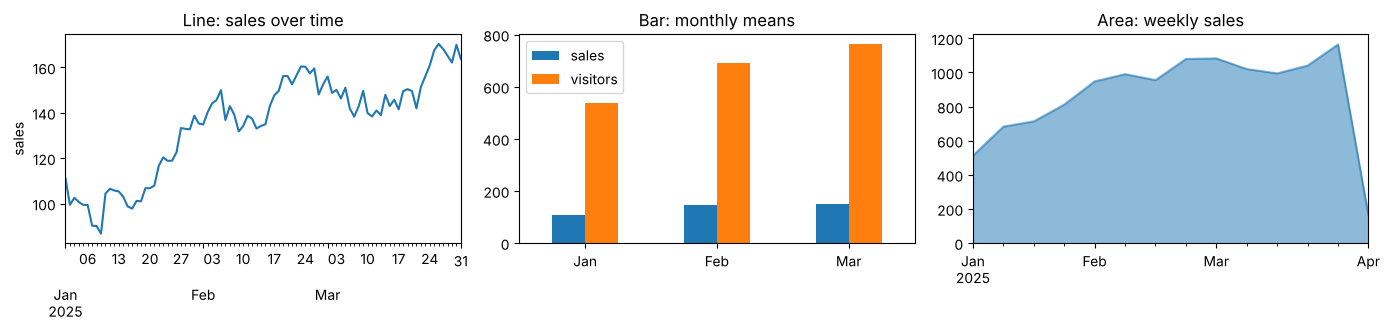

In [163]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))

df["sales"].plot(ax=axes[0], title="Line: sales over time", color="tab:blue")
axes[0].set_ylabel("sales")

df[["sales", "visitors"]].resample("ME").mean().plot(kind="bar", ax=axes[1], title="Bar: monthly means")
axes[1].set_xticklabels(["Jan", "Feb", "Mar"], rotation=0)

df[["sales"]].resample("W").sum().plot.area(ax=axes[2], title="Area: weekly sales", alpha=0.5, legend=False)

plt.tight_layout()
plt.show()

**Explanation**

- `df.plot()` draws a **line chart by default** with the index on the x-axis. `kind="bar"` (or `.plot.bar()`), `.plot.area()`, `.plot.barh()` choose other types.
- Passing `ax=` draws on a specific Matplotlib axis so you can build multi-panel figures.

## 28.2 Distributions: histogram, box, density

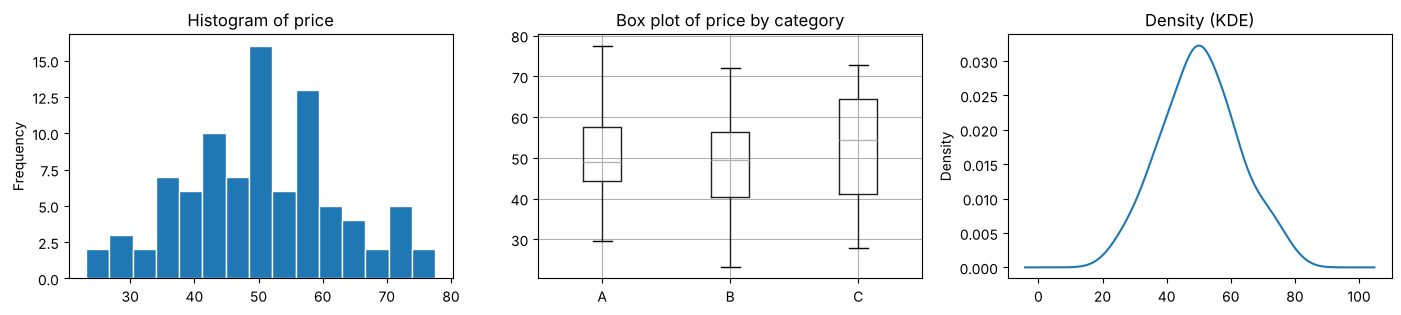

In [164]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))

df["price"].plot.hist(bins=15, ax=axes[0], title="Histogram of price", edgecolor="white")
df.boxplot(column="price", by="category", ax=axes[1])
axes[1].set_title("Box plot of price by category"); axes[1].set_xlabel("")
fig.suptitle("")
df["price"].plot.kde(ax=axes[2], title="Density (KDE)")      # needs scipy

plt.tight_layout()
plt.show()

**Explanation**

- **Histogram** shows how values are spread, **box plot** shows median, quartiles and outliers (here split by category), **KDE** shows a smoothed density curve.

## 28.3 Relationships: scatter, correlation, pie

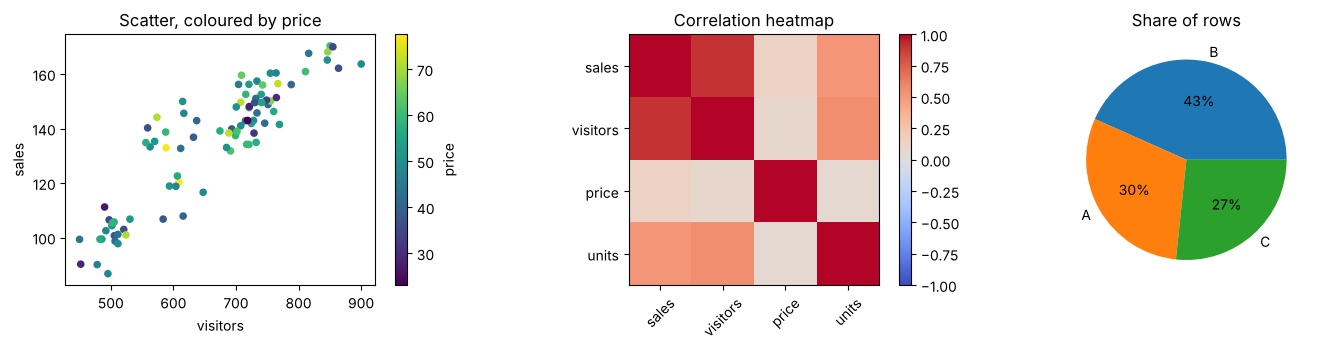

In [165]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

df.plot.scatter(x="visitors", y="sales", c="price", cmap="viridis", ax=axes[0], title="Scatter, coloured by price")

corr = df[["sales", "visitors", "price", "units"]].corr()
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr))); axes[1].set_xticklabels(corr.columns, rotation=45)
axes[1].set_yticks(range(len(corr))); axes[1].set_yticklabels(corr.columns)
axes[1].set_title("Correlation heatmap")
fig.colorbar(im, ax=axes[1], fraction=0.046)

df["category"].value_counts().plot.pie(ax=axes[2], autopct="%.0f%%", title="Share of rows", ylabel="")

plt.tight_layout()
plt.show()

**Explanation**

- `scatter` (with `c=` for colour) shows relationships; a correlation matrix drawn with `imshow` is a quick **heatmap**; `value_counts().plot.pie()` shows shares (bars are usually clearer than pies).

## 28.4 Grouped plots, secondary axis and saving

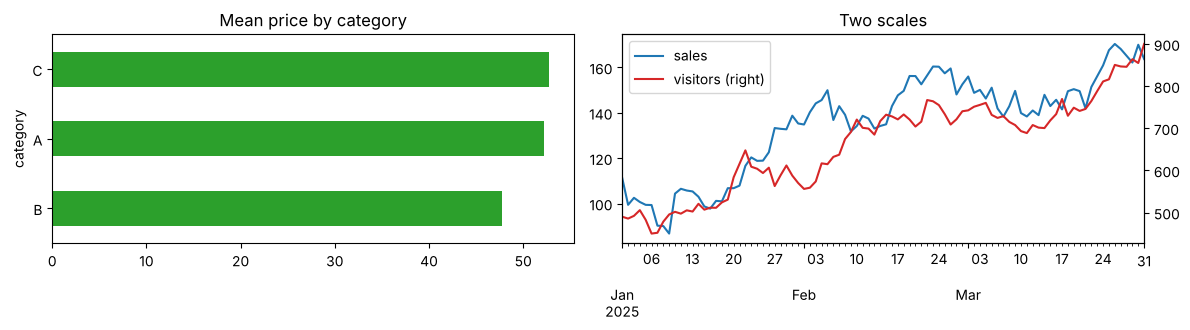

True


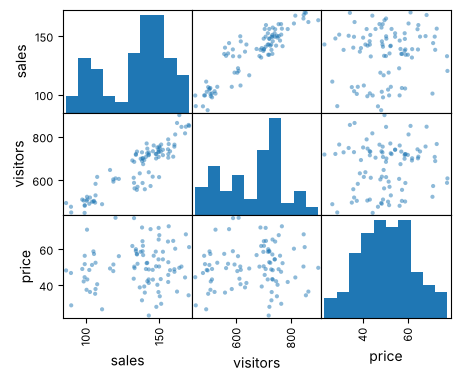

In [166]:
import os

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))

df.groupby("category")["price"].mean().sort_values().plot.barh(ax=axes[0], title="Mean price by category", color="tab:green")

ax = df["sales"].plot(ax=axes[1], color="tab:blue", label="sales", legend=True)
df["visitors"].plot(ax=ax, secondary_y=True, color="tab:red", label="visitors", legend=True)    # second y-axis
ax.set_title("Two scales")

plt.tight_layout()
fig.savefig("chart.png", dpi=120)                   # save the figure
plt.show()
print(os.path.exists("chart.png"))
os.remove("chart.png")

pd.plotting.scatter_matrix(df[["sales", "visitors", "price"]], figsize=(5, 4), diagonal="hist")
plt.show()

**Explanation**

- Plot a `groupby` result directly. `secondary_y=True` adds a right-hand axis for a series with a different scale.
- `fig.savefig("name.png", dpi=...)` writes the image; `pd.plotting.scatter_matrix` draws all pairwise scatter plots.

---

# Chapter 29: Performance and Best Practices

Pandas is fast when you work on **whole columns** and use compact types. These habits make code both faster and clearer.

## 29.1 Vectorise: apply vs vectorised vs loops

In [167]:
import pandas as pd
import numpy as np
import timeit

n = 200_000
df = pd.DataFrame({"a": np.random.default_rng(0).random(n), "b": np.random.default_rng(1).random(n)})

def with_iterrows():
    out = []
    for _, row in df.head(5000).iterrows():
        out.append(row["a"] + row["b"])
    return out

def with_apply():
    return df.apply(lambda r: r["a"] + r["b"], axis=1)

def with_itertuples():
    return [r.a + r.b for r in df.itertuples()]

def vectorised():
    return df["a"] + df["b"]

def numpy_version():
    return df["a"].to_numpy() + df["b"].to_numpy()

print("iterrows (5k rows):", round(timeit.timeit(with_iterrows, number=1), 4))
print("apply axis=1 (200k):", round(timeit.timeit(with_apply, number=1), 4))
print("itertuples (200k)  :", round(timeit.timeit(with_itertuples, number=1), 4))
print("vectorised (200k)  :", round(timeit.timeit(vectorised, number=5) / 5, 5))
print("NumPy arrays       :", round(timeit.timeit(numpy_version, number=5) / 5, 5))

iterrows (5k rows): 0.0695


apply axis=1 (200k): 0.7221
itertuples (200k)  : 0.0745
vectorised (200k)  : 0.00047
NumPy arrays       : 0.00026


**Explanation**

- Order of speed (fastest to slowest): **NumPy / vectorised Series operations → `itertuples` → `apply(axis=1)` → `iterrows`**. Row-wise Python loops are typically 100 to 1000 times slower than column operations.

## 29.2 Memory: choose smaller dtypes

In [168]:
rng = np.random.default_rng(0)
n = 500_000
df = pd.DataFrame({
    "id": np.arange(n),
    "age": rng.integers(18, 90, n),
    "score": rng.random(n),
    "city": rng.choice(["Delhi", "Pune", "Goa", "Mumbai"], n),
    "active": rng.choice([True, False], n),
})
print(df.dtypes.to_dict())
before = df.memory_usage(deep=True).sum()

small = df.copy()
small["id"] = pd.to_numeric(small["id"], downcast="unsigned")
small["age"] = pd.to_numeric(small["age"], downcast="unsigned")
small["score"] = small["score"].astype("float32")
small["city"] = small["city"].astype("category")
after = small.memory_usage(deep=True).sum()

print(small.dtypes.to_dict())
print(f"{before / 1e6:.1f} MB -> {after / 1e6:.1f} MB ({after / before:.0%})")
print(small.memory_usage(deep=True).div(1e6).round(2).to_dict())

{'id': dtype('int64'), 'age': dtype('int64'), 'score': dtype('float64'), 'city': <StringDtype(storage='python', na_value=nan)>, 'active': dtype('bool')}


{'id': dtype('uint32'), 'age': dtype('uint8'), 'score': dtype('float32'), 'city': CategoricalDtype(categories=['Delhi', 'Goa', 'Mumbai', 'Pune'], ordered=False, categories_dtype=str), 'active': dtype('bool')}
39.3 MB -> 5.5 MB (14%)
{'Index': 0.0, 'id': 2.0, 'age': 0.5, 'score': 2.0, 'city': 0.5, 'active': 0.5}


**Explanation**

- `downcast` shrinks integers to the smallest type that fits; `float32` halves float storage; **`category`** is a huge saving for repeated text.
- `memory_usage(deep=True)` reports real memory including text.

## 29.3 Efficient reading and building

In [169]:
import timeit

# Reading only what you need
csv = "a,b,c,d,e\n" + "\n".join(f"{i},{i*2},{i*3},{i*4},{i*5}" for i in range(50_000))
from io import StringIO
print(pd.read_csv(StringIO(csv)).memory_usage().sum(), "->",
      pd.read_csv(StringIO(csv), usecols=["a", "c"], dtype="int32").memory_usage().sum())

# Never grow a DataFrame row by row
def slow_build():
    out = pd.DataFrame(columns=["x", "y"])
    for i in range(300):
        out.loc[len(out)] = [i, i * 2]
    return out

def fast_build():
    rows = [{"x": i, "y": i * 2} for i in range(300)]       # collect in a list...
    return pd.DataFrame(rows)                                # ...build ONCE

print("row by row:", round(timeit.timeit(slow_build, number=1), 4))
print("list then DataFrame:", round(timeit.timeit(fast_build, number=1), 5))

2000132 -> 400132
row by row: 0.1044
list then DataFrame: 0.00048


**Explanation**

- Load only the columns you need (`usecols`) with sensible `dtype`s.
- Collect rows in a **list** and create the DataFrame **once**; appending row by row copies data every time.

## 29.4 Method chaining and readable code

In [170]:
raw = pd.DataFrame({
    "Name ": [" ann", "BOB ", "cy"],
    "Score": ["90", "75", "x"],
    "Dept": ["it", "hr", "it"],
})

tidy = (
    raw
    .rename(columns=lambda c: c.strip().lower())                       # clean column names
    .assign(
        name=lambda d: d["name"].str.strip().str.title(),
        score=lambda d: pd.to_numeric(d["score"], errors="coerce"),
        dept=lambda d: d["dept"].str.upper().astype("category"),
    )
    .dropna(subset=["score"])
    .query("score > 70")
    .sort_values("score", ascending=False)
    .reset_index(drop=True)
)
print(tidy)
print(tidy.dtypes.to_dict())

  name  score dept
0  Ann   90.0   IT
1  Bob   75.0   HR
{'name': <StringDtype(storage='python', na_value=nan)>, 'score': dtype('float64'), 'dept': CategoricalDtype(categories=['HR', 'IT'], ordered=False, categories_dtype=str)}


**Explanation**

- A chain of `rename`, `assign`, `query`, `sort_values`... reads top to bottom like a recipe, avoids temporary variables, and every step returns a **new** object (no accidental mutation).

## 29.5 Common pitfalls

| Pitfall | What happens | Do this instead |
|---|---|---|
| `df[df.a > 1]["b"] = 0` (chained assignment) | does not modify `df` (pandas 3) or warns (pandas 2) | `df.loc[df.a > 1, "b"] = 0` |
| `df["a"] == np.nan` | always `False` | `df["a"].isna()` |
| `if df["a"] > 1:` | `ValueError: truth value is ambiguous` | `.any()`, `.all()`, or filter |
| `df[cond1 & cond2]` without parentheses | operator precedence error | `df[(cond1) & (cond2)]` |
| Integer column with missing values becomes `float` | `1, 2, NaN` is `float64` | use nullable `"Int64"` |
| `inplace=True` | no speed gain, breaks chaining | reassign: `df = df.dropna()` |
| `apply(axis=1)` on big tables | very slow | vectorise, `np.where`, `np.select` |
| Forgetting `reset_index` after `groupby` | key is in the index | `as_index=False` or `reset_index()` |
| Merging on non-unique keys | rows multiply silently | `validate="one_to_one"` / check duplicates |
| Comparing floats with `==` | rounding noise | `np.isclose` |
| Using `object` dtype for dates and numbers | slow, wrong results | `to_datetime`, `to_numeric`, `astype` |
| Sorting inside loops | repeated cost | sort once, or set a sorted index |
| `df.append(...)` | removed in pandas 2 | `pd.concat([...])` |
| `applymap`, `fillna(method="ffill")`, `resample("M")` | removed or deprecated | `DataFrame.map`, `ffill()`, `"ME"` |

## 29.6 When pandas is not enough

| Situation | Consider |
|---|---|
| Data larger than RAM | **Dask**, **Polars** (lazy), **DuckDB** (SQL on files), chunked `read_csv` |
| Need maximum single-machine speed | **Polars**, pandas with the **PyArrow** backend |
| Heavy numeric loops | NumPy, **Numba** |
| Distributed clusters | **Spark** (PySpark), Dask |
| Interactive dashboards | **Streamlit**, **Plotly Dash** |

Pandas remains the standard for small to medium data and is the common language of the Python data ecosystem.

---

# Chapter 30: End-to-End Project: Retail Sales Analysis

Putting everything together: raw, messy data → cleaning → feature engineering → analysis → charts → insights → export.

**Business questions**

1. How much did we earn, and how did revenue change month to month?
2. Which categories and products drive revenue?
3. Which regions and payment methods are strongest?
4. Who are our best customers? (RFM segmentation)

## 30.1 Generate and load raw data

In [171]:
import pandas as pd
import numpy as np
from io import StringIO

rng = np.random.default_rng(2025)
n = 2000

catalog = pd.DataFrame({
    "product": ["Notebook", "Pen", "Backpack", "Lamp", "Mug", "Headphones", "Keyboard", "Bottle"],
    "category": ["Stationery", "Stationery", "Accessories", "Home", "Home", "Electronics", "Electronics", "Accessories"],
    "base_price": [4.5, 1.2, 35.0, 28.0, 9.0, 60.0, 45.0, 14.0],
})
customer_ids = [f"C{i:03d}" for i in range(1, 151)]
weights = rng.dirichlet(np.ones(150) * 0.6)                      # some customers buy much more often

orders = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "order_date": pd.to_datetime("2024-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.choice(customer_ids, n, p=weights),
    "product": rng.choice(catalog["product"], n),
    "quantity": rng.integers(1, 6, n),
    "discount": rng.choice([0, 0.05, 0.10, 0.20], n, p=[0.6, 0.2, 0.15, 0.05]),
    "region": rng.choice(["North", "South", "East", "West"], n, p=[0.3, 0.25, 0.25, 0.2]),
    "payment": rng.choice(["card", "upi", "cash", "wallet"], n, p=[0.4, 0.35, 0.15, 0.1]),
})
orders = orders.merge(catalog[["product", "base_price"]], on="product")
orders["unit_price"] = (orders["base_price"] * rng.uniform(0.95, 1.05, len(orders))).round(2)
orders = orders.drop(columns="base_price").sort_values("order_id")

# ---- Inject realistic dirt ----
dirty = orders.copy()
dirty["order_date"] = dirty["order_date"].dt.strftime("%Y-%m-%d")
dirty["quantity"] = dirty["quantity"].astype(float)                                         # NaN needs a float column
dirty.loc[dirty.sample(40, random_state=1).index, "quantity"] = np.nan                      # missing quantities
dirty.loc[dirty.sample(10, random_state=2).index, "quantity"] = -1                          # impossible quantities
dirty["unit_price"] = dirty["unit_price"].astype(str)
price_idx = dirty.sample(30, random_state=3).index
dirty.loc[price_idx, "unit_price"] = "$" + dirty.loc[price_idx, "unit_price"]                # currency symbols
dirty.loc[dirty.sample(60, random_state=4).index, "region"] = " north "                      # stray spaces / case
dirty.loc[dirty.sample(40, random_state=5).index, "region"] = "SOUTH"
dirty = pd.concat([dirty, dirty.sample(25, random_state=6)], ignore_index=True)             # duplicated rows
buffer = StringIO(); dirty.to_csv(buffer, index=False); buffer.seek(0)

raw = pd.read_csv(buffer)                                                                    # what an analyst receives
print(raw.shape)
raw.head()

(2025, 9)


,order_id,order_date,customer_id,product,quantity,discount,region,payment,unit_price
0,1,2024-09-30,C043,Notebook,3.0,0.00,West,wallet,4.69
1,2,2024-03-30,C010,Mug,5.0,0.00,East,card,8.56
2,3,2024-11-27,C016,Headphones,5.0,0.00,North,card,60.1
3,4,2024-05-23,C124,Bottle,5.0,0.05,South,card,14.59
4,5,2024-05-03,C043,Keyboard,4.0,0.00,South,card,44.47


**Explanation**

- We simulate a year of orders, then deliberately damage it: missing and negative quantities, `$` signs in prices, inconsistent region labels and duplicate rows. Writing to a CSV buffer and reading it back mimics receiving a real file.

## 30.2 First look

In [172]:
raw.info()
print(raw.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])
print(raw.isna().sum().to_dict())
print(raw["region"].value_counts().to_dict())
print("duplicate order_ids:", raw["order_id"].duplicated().sum())
print("invalid quantities:", (raw["quantity"] <= 0).sum())

<class 'pandas.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     2025 non-null   int64  
 1   order_date   2025 non-null   str    
 2   customer_id  2025 non-null   str    
 3   product      2025 non-null   str    
 4   quantity     1985 non-null   float64
 5   discount     2025 non-null   float64
 6   region       2025 non-null   str    
 7   payment      2025 non-null   str    
 8   unit_price   2025 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 142.5 KB
              count unique         top     mean  min     max
order_id     2025.0    NaN         NaN  999.435  1.0  2000.0
order_date     2025    362  2024-11-27      NaN  NaN     NaN
customer_id    2025    135        C001      NaN  NaN     NaN
product        2025      8    Keyboard      NaN  NaN     NaN
quantity     1985.0    NaN         NaN    2.995 -1.0     5.0
discount     2025

**Explanation**

- Always profile first: types, missing counts, category labels, duplicates and impossible values show exactly what cleaning is needed.

## 30.3 Clean

In [173]:
def clean_orders(df):
    return (
        df
        .drop_duplicates()                                                       # exact duplicate rows
        .assign(
            order_date=lambda d: pd.to_datetime(d["order_date"], format="%Y-%m-%d", errors="coerce"),
            unit_price=lambda d: pd.to_numeric(d["unit_price"].astype(str).str.replace("$", "", regex=False), errors="coerce"),
            region=lambda d: d["region"].str.strip().str.title(),
            quantity=lambda d: d["quantity"].where(d["quantity"] > 0),          # negative -> NaN
        )
        .assign(quantity=lambda d: d["quantity"].fillna(d.groupby("product")["quantity"].transform("median")).astype(int))
        .astype({"region": "category", "payment": "category", "product": "category", "customer_id": "string"})
        .reset_index(drop=True)
    )

orders_clean = clean_orders(raw)
print(orders_clean.shape, raw.shape)
print(orders_clean.dtypes.to_dict())
print(orders_clean["region"].value_counts().to_dict())
assert orders_clean["order_id"].is_unique
assert (orders_clean["quantity"] > 0).all()
assert orders_clean["unit_price"].notna().all()
assert orders_clean["order_date"].notna().all()
print("all checks passed")

(2000, 9) (2025, 9)
{'order_id': dtype('int64'), 'order_date': dtype('<M8[us]'), 'customer_id': <StringDtype(storage='python', na_value=<NA>)>, 'product': CategoricalDtype(categories=['Backpack', 'Bottle', 'Headphones', 'Keyboard', 'Lamp', 'Mug', 'Notebook', 'Pen'], ordered=False, categories_dtype=str), 'quantity': dtype('int64'), 'discount': dtype('float64'), 'region': CategoricalDtype(categories=['East', 'North', 'South', 'West'], ordered=False, categories_dtype=str), 'payment': CategoricalDtype(categories=['card', 'cash', 'upi', 'wallet'], ordered=False, categories_dtype=str), 'unit_price': dtype('float64')}
{'North': 626, 'South': 525, 'East': 500, 'West': 349}
all checks passed


**Explanation**

- One reusable function, written as a **method chain**: drop duplicates, parse dates and numbers, fix labels, replace invalid quantities with the product's median, and set efficient dtypes.
- The `assert` lines are lightweight data-quality tests.

## 30.4 Feature engineering

In [174]:
orders_fe = orders_clean.assign(
    revenue=lambda d: (d["quantity"] * d["unit_price"] * (1 - d["discount"])).round(2),
    month=lambda d: d["order_date"].dt.to_period("M"),
    month_name=lambda d: d["order_date"].dt.month_name(),
    weekday=lambda d: d["order_date"].dt.day_name(),
    quarter=lambda d: "Q" + d["order_date"].dt.quarter.astype(str),
    is_weekend=lambda d: d["order_date"].dt.dayofweek >= 5,
    discounted=lambda d: d["discount"] > 0,
)
orders_fe = orders_fe.merge(catalog[["product", "category"]], on="product", how="left")
orders_fe.head(3)

,order_id,order_date,customer_id,product,quantity,discount,region,payment,unit_price,revenue,month,month_name,weekday,quarter,is_weekend,discounted,category
0,1,2024-09-30,C043,Notebook,3,0.0,West,wallet,4.69,14.07,2024-09,September,Monday,Q3,False,False,Stationery
1,2,2024-03-30,C010,Mug,5,0.0,East,card,8.56,42.80,2024-03,March,Saturday,Q1,True,False,Home
2,3,2024-11-27,C016,Headphones,5,0.0,North,card,60.10,300.50,2024-11,November,Wednesday,Q4,False,False,Electronics


**Explanation**

- New columns: `revenue` after discount, date parts, weekend flag, and the product **category** merged in from the catalogue (a left join).

## 30.5 Analysis

In [175]:
total = orders_fe["revenue"].sum()
print(f"Total revenue : {total:,.0f}")
print(f"Orders        : {len(orders_fe):,}")
print(f"Customers     : {orders_fe['customer_id'].nunique()}")
print(f"Avg order     : {orders_fe['revenue'].mean():.2f}")

# 1. Monthly revenue and growth
monthly = orders_fe.groupby("month")["revenue"].sum().to_frame("revenue")
monthly["growth_%"] = (monthly["revenue"].pct_change() * 100).round(1)
print(monthly.round(0).head(6))
print("best month :", monthly["revenue"].idxmax(), "| worst month:", monthly["revenue"].idxmin())

# 2. Category and product performance
by_cat = orders_fe.groupby("category", observed=True).agg(
    revenue=("revenue", "sum"), orders=("order_id", "count"), avg_discount=("discount", "mean")
).sort_values("revenue", ascending=False)
by_cat["share_%"] = (by_cat["revenue"] / by_cat["revenue"].sum() * 100).round(1)
print(by_cat.round(2))
top_products = orders_fe.groupby("product", observed=True)["revenue"].sum().nlargest(3)
print(top_products.round(0).to_dict())

# 3. Region and payment
print(orders_fe.pivot_table(index="region", columns="payment", values="revenue", aggfunc="sum", observed=True).round(0))
print(orders_fe.groupby("weekday")["revenue"].mean().round(1).sort_values(ascending=False).head(3).to_dict())

# 4. Does discounting increase quantity?
print(orders_fe.groupby("discount")[["quantity", "revenue"]].mean().round(2))

Total revenue : 146,362
Orders        : 2,000
Customers     : 135
Avg order     : 73.18
         revenue  growth_%
month                     
2024-01  11286.0       NaN
2024-02   9647.0     -14.0
2024-03  12954.0      34.0
2024-04  12153.0      -6.0
2024-05  14403.0      18.0
2024-06  12417.0     -14.0
best month : 2024-05 | worst month: 2024-02
              revenue  orders  avg_discount  share_%
category                                            
Electronics  78095.02     521          0.03     53.4
Accessories  37237.16     495          0.04     25.4
Home         27267.23     510          0.03     18.6
Stationery    3762.56     474          0.04      2.6
{'Headphones': 41449.0, 'Keyboard': 36646.0, 'Backpack': 27565.0}
payment     card    cash      upi  wallet
region                                   
East     17093.0  5992.0  13256.0  3044.0
North    17391.0  6784.0  19044.0  3240.0
South    14352.0  5135.0  11928.0  4967.0
West     11125.0  3124.0   7665.0  2222.0
{'Sunday': 79.8,

**Explanation**

- Typical analysis flow: KPIs, trend with growth (`pct_change`), contribution by category (named aggregation + share), cross-tab of region and payment, and a check of how discounts relate to quantity.
- The `period` dtype (`dt.to_period("M")`) gives clean month labels that sort correctly.

## 30.6 Customer segmentation (RFM)

In [176]:
snapshot = orders_fe["order_date"].max() + pd.Timedelta(days=1)       # "today" for recency

rfm = orders_fe.groupby("customer_id", observed=True).agg(
    recency=("order_date", lambda s: (snapshot - s.max()).days),       # days since the last order
    frequency=("order_id", "count"),                                   # number of orders
    monetary=("revenue", "sum"),                                       # total spend
)

# Score each dimension 1 to 4 with quartiles (for recency, LOWER is better)
rfm["R"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["score"] = rfm[["R", "F", "M"]].sum(axis=1)
rfm["segment"] = pd.cut(rfm["score"], bins=[2, 5, 8, 10, 12], labels=["At risk", "Regular", "Loyal", "Champions"])

print(rfm.sort_values("monetary", ascending=False).head(5).round(0))
seg = rfm.groupby("segment", observed=True).agg(customers=("score", "size"), avg_spend=("monetary", "mean"), total=("monetary", "sum")).round(0)
seg["revenue_share_%"] = (seg["total"] / seg["total"].sum() * 100).round(1)
print(seg)
print("top 20% of customers generate", round(rfm["monetary"].nlargest(int(len(rfm) * 0.2)).sum() / rfm["monetary"].sum() * 100, 1), "% of revenue")

             recency  frequency  monetary  R  F  M  score    segment
customer_id                                                         
C001               7        143    9420.0  4  4  4     12  Champions
C032               2        120    9164.0  4  4  4     12  Champions
C036               4         61    5734.0  4  4  4     12  Champions
C138               1         62    4860.0  4  4  4     12  Champions
C026               5         70    4537.0  4  4  4     12  Champions
           customers  avg_spend    total  revenue_share_%
segment                                                  
At risk           45      180.0   8086.0              5.5
Regular           30      525.0  15751.0             10.8
Loyal             31     1150.0  35636.0             24.3
Champions         29     2996.0  86889.0             59.4
top 20% of customers generate 58.6 % of revenue


**Explanation**

- **RFM** scores each customer on **R**ecency, **F**requency and **M**onetary value, a classic marketing segmentation.
- `qcut` assigns quartile scores. Recency uses reversed labels because a *smaller* number of days is better. Ranking before `qcut` avoids errors from tied bin edges.
- The last line measures concentration: how much revenue the top 20% of customers produce (the Pareto principle).

## 30.7 Visualise

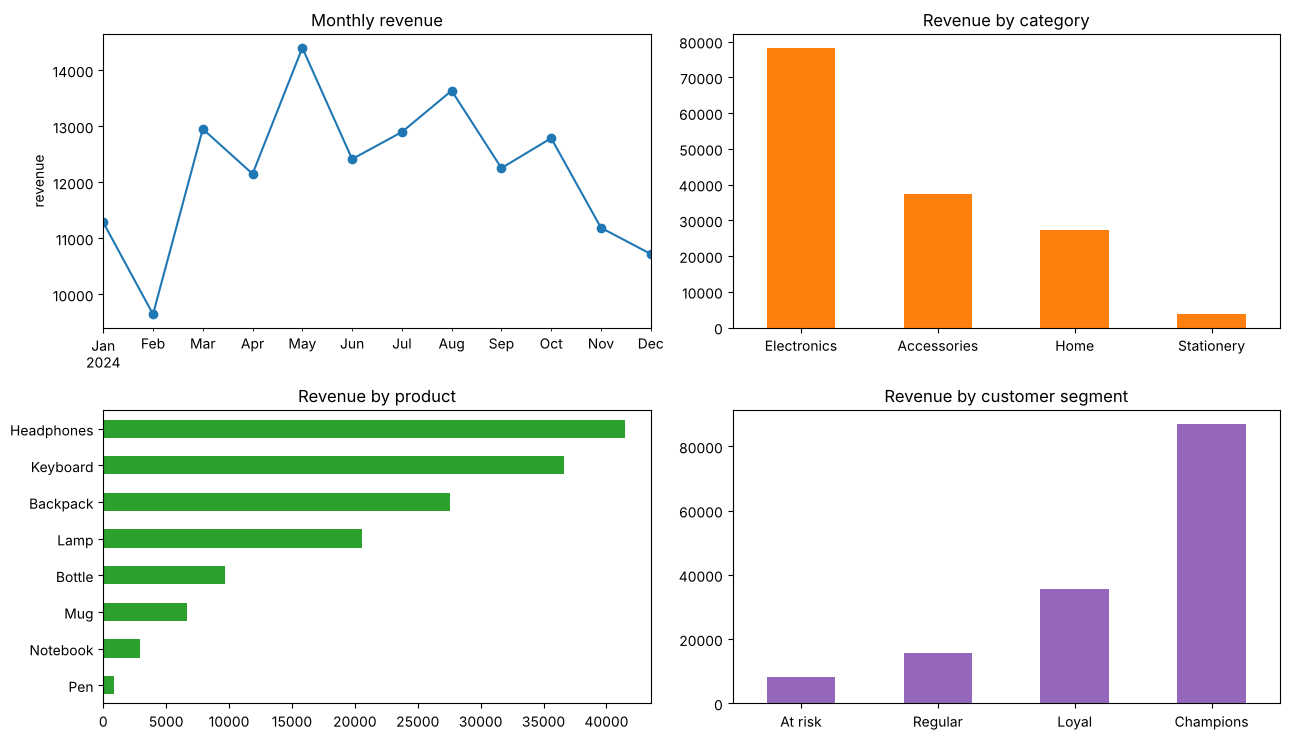

In [177]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))

monthly["revenue"].plot(ax=axes[0, 0], marker="o", title="Monthly revenue")
axes[0, 0].set_xlabel(""); axes[0, 0].set_ylabel("revenue")

by_cat["revenue"].plot.bar(ax=axes[0, 1], color="tab:orange", title="Revenue by category", rot=0)
axes[0, 1].set_xlabel("")

orders_fe.groupby("product", observed=True)["revenue"].sum().sort_values().plot.barh(ax=axes[1, 0], title="Revenue by product", color="tab:green")
axes[1, 0].set_ylabel("")

seg["total"].plot.bar(ax=axes[1, 1], color="tab:purple", title="Revenue by customer segment", rot=0)
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()

**Explanation**

- A 2x2 dashboard drawn straight from the aggregated tables. Good charts answer one question each and have clear titles.

## 30.8 Insights and export

In [178]:
import os

best_cat = by_cat.index[0]
best_month = monthly["revenue"].idxmax()
champ_share = seg.loc["Champions", "revenue_share_%"] if "Champions" in seg.index else float("nan")

insights = [
    f"Total revenue is {total:,.0f} from {orders_fe['customer_id'].nunique()} customers.",
    f"{best_cat} is the top category with {by_cat.loc[best_cat, 'share_%']}% of revenue.",
    f"The strongest month was {best_month}.",
    f"'Champions' customers produce {champ_share}% of revenue, so retention of this group matters most.",
]
for line in insights:
    print("-", line)

# Export the results
with pd.ExcelWriter("sales_report.xlsx") as writer:
    monthly.to_excel(writer, sheet_name="monthly")
    by_cat.to_excel(writer, sheet_name="categories")
    seg.to_excel(writer, sheet_name="segments")
    rfm.to_excel(writer, sheet_name="rfm")
orders_fe.drop(columns="month").to_csv("orders_clean.csv", index=False)
print(sorted(pd.read_excel("sales_report.xlsx", sheet_name=None)))
for f in ("sales_report.xlsx", "orders_clean.csv"):
    os.remove(f)

- Total revenue is 146,362 from 135 customers.
- Electronics is the top category with 53.4% of revenue.
- The strongest month was 2024-05.
- 'Champions' customers produce 59.4% of revenue, so retention of this group matters most.
['categories', 'monthly', 'rfm', 'segments']


**Explanation**

- Finish by turning numbers into **plain-language insights** and exporting tidy tables (Excel for stakeholders, clean CSV or Parquet for further processing).

---

# Chapter 31: NumPy and Pandas for Machine Learning

Pandas prepares data; NumPy arrays feed the models. This chapter shows the bridge: features and target, encoding, scaling, splitting and a model built without any ML library.

In [179]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(11)
n = 400
houses = pd.DataFrame({
    "area": rng.normal(1500, 400, n).round(0),
    "bedrooms": rng.integers(1, 6, n),
    "age": rng.integers(0, 60, n),
    "city": rng.choice(["Delhi", "Pune", "Goa"], n),
    "has_garden": rng.choice([0, 1], n),
})
city_effect = houses["city"].map({"Delhi": 40, "Pune": 15, "Goa": 60})
houses["price"] = (50 + 0.12 * houses["area"] + 12 * houses["bedrooms"] - 0.8 * houses["age"]
                   + city_effect + 20 * houses["has_garden"] + rng.normal(0, 15, n)).round(1)
houses.loc[rng.choice(n, 15, replace=False), "area"] = np.nan          # some missing values
houses.head()

,area,bedrooms,age,city,has_garden,price
0,1514.0,4,24,Delhi,1,301.7
1,2044.0,5,5,Delhi,0,351.2
2,1990.0,1,27,Pune,1,308.4
3,1296.0,1,15,Delhi,1,276.9
4,1381.0,3,37,Goa,1,307.8


**Explanation**

- A synthetic house-price dataset with numeric, categorical and binary features and some missing values.

## 31.1 Features, target and encoding

In [180]:
X = houses.drop(columns="price")
y = houses["price"]
print(X.shape, y.shape)

# 1. Handle missing values (learn statistics from the data, here the median)
area_median = X["area"].median()
X = X.assign(area=X["area"].fillna(area_median))

# 2. Encode categories: one-hot (drop one level to avoid redundancy)
X = pd.get_dummies(X, columns=["city"], drop_first=True, dtype=int)
print(X.head(3))
print(X.dtypes.to_dict())

(400, 5) (400,)
     area  bedrooms  age  has_garden  city_Goa  city_Pune
0  1514.0         4   24           1         0          0
1  2044.0         5    5           0         0          0
2  1990.0         1   27           1         0          1
{'area': dtype('float64'), 'bedrooms': dtype('int64'), 'age': dtype('int64'), 'has_garden': dtype('int64'), 'city_Goa': dtype('int64'), 'city_Pune': dtype('int64')}


**Explanation**

- Split the table into **features `X`** and **target `y`**. Fill missing values, then **one-hot encode** categories because models need numbers.

## 31.2 Train/test split and scaling (without leakage)

In [181]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
cut = int(0.8 * len(X))
train_idx, test_idx = idx[:cut], idx[cut:]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(X_train.shape, X_test.shape)

# Standardise using TRAINING statistics only
numeric = ["area", "bedrooms", "age"]
mu, sigma = X_train[numeric].mean(), X_train[numeric].std()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[numeric] = (X_train[numeric] - mu) / sigma
X_test_s[numeric] = (X_test[numeric] - mu) / sigma                    # same mu and sigma as training

print(X_train_s[numeric].mean().round(3).to_dict(), X_test_s[numeric].mean().round(2).to_dict())

(320, 6) (80, 6)
{'area': 0.0, 'bedrooms': -0.0, 'age': -0.0} {'area': 0.01, 'bedrooms': 0.05, 'age': -0.04}


**Explanation**

- **Data leakage** happens when information from the test set influences training. So compute the mean and standard deviation on the **training data only** and reuse them on the test data.
- `rng.permutation` shuffles row positions; `iloc` slices both X and y consistently.

## 31.3 A model with NumPy: linear regression

In [182]:
def add_bias(M):
    return np.c_[M.to_numpy(dtype=float), np.ones(len(M))]            # DataFrame -> NumPy, plus a bias column

A_train, A_test = add_bias(X_train_s), add_bias(X_test_s)
weights = np.linalg.solve(A_train.T @ A_train, A_train.T @ y_train.to_numpy())

pred_train, pred_test = A_train @ weights, A_test @ weights

def rmse(y_true, y_pred): return np.sqrt(np.mean((y_true - y_pred) ** 2))
def r2(y_true, y_pred): return 1 - ((y_true - y_pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()

print("RMSE train/test:", rmse(y_train.to_numpy(), pred_train).round(2), rmse(y_test.to_numpy(), pred_test).round(2))
print("R2   train/test:", r2(y_train.to_numpy(), pred_train).round(3), r2(y_test.to_numpy(), pred_test).round(3))

coefs = pd.Series(weights[:-1], index=X_train_s.columns).sort_values(key=abs, ascending=False)
print(coefs.round(2))
print("bias:", weights[-1].round(2))

baseline = rmse(y_test.to_numpy(), np.full(len(y_test), y_train.mean()))
print("baseline (predict the mean) RMSE:", baseline.round(2))
assert rmse(y_test.to_numpy(), pred_test) < baseline

RMSE train/test: 16.69 17.72
R2   train/test: 0.92 0.904
area          47.40
city_Pune    -23.45
has_garden    23.20
city_Goa      19.33
bedrooms      17.63
age          -13.16
dtype: float64
bias: 282.55
baseline (predict the mean) RMSE: 57.41


**Explanation**

- `to_numpy()` hands the data to NumPy; we solve the normal equation exactly as in Chapter 15.
- Always compare against a **baseline** (always predicting the training mean). A useful model must beat it.
- Standardised coefficients let you compare feature importance directly; `sort_values(key=abs)` sorts by magnitude.

In [183]:
# The same workflow with scikit-learn (if installed)
try:
    from sklearn.model_selection import train_test_split
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_squared_error, r2_score

    X_raw, y_raw = houses.drop(columns="price"), houses["price"]
    Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2, random_state=0)

    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), ["area", "bedrooms", "age"]),
        ("cat", OneHotEncoder(drop="first"), ["city"]),
    ], remainder="passthrough")
    model = Pipeline([("prep", prep), ("reg", LinearRegression())]).fit(Xtr, ytr)
    pred = model.predict(Xte)
    print("sklearn RMSE:", round(mean_squared_error(yte, pred) ** 0.5, 2), "R2:", round(r2_score(yte, pred), 3))
except ImportError:
    print("scikit-learn is not installed (pip install scikit-learn); the manual version above shows the same steps.")

sklearn RMSE: 15.06 R2: 0.934


**Explanation**

- scikit-learn wraps imputation, scaling, encoding and the model into a **Pipeline** that learns from training data and applies the same steps to new data automatically. Understanding the manual steps above makes the pipeline easy to trust.

---

# Chapter 32: Practice Exercises

Try each exercise yourself before reading the solution. Every solution ends with `assert` checks.

## 32.1 NumPy exercises

**N1. Normalise rows.** Given a 2D array, scale each row so its values sum to 1.

In [184]:
import numpy as np
import pandas as pd

def normalise_rows(a):
    return a / a.sum(axis=1, keepdims=True)

a = np.array([[1, 3], [2, 2], [5, 15]], dtype=float)
out = normalise_rows(a)
assert np.allclose(out.sum(axis=1), 1) and np.allclose(out[0], [0.25, 0.75])
print(out)

[[0.25 0.75]
 [0.5  0.5 ]
 [0.25 0.75]]

**N2. Checkerboard.** Create an 8x8 array of 0s and 1s in a checkerboard pattern without loops.

In [185]:
board = np.indices((8, 8)).sum(axis=0) % 2
assert board[0, 0] == 0 and board[0, 1] == 1 and board.sum() == 32
print(board[:3])

[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]]


**N3. Moving average.** Compute a moving average with window `k` using only NumPy.

In [186]:
def moving_average(x, k):
    c = np.cumsum(np.insert(x, 0, 0.0))
    return (c[k:] - c[:-k]) / k

x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
assert np.allclose(moving_average(x, 3), [2, 3, 4, 5])
print(moving_average(x, 3))

[2. 3. 4. 5.]

**N4. Closest value.** For each element in `a`, find the closest value in a sorted array `b`.

In [187]:
def closest(a, b):
    idx = np.searchsorted(b, a)
    idx = np.clip(idx, 1, len(b) - 1)
    left, right = b[idx - 1], b[idx]
    return np.where(np.abs(a - left) <= np.abs(a - right), left, right)

b = np.array([0, 10, 20, 30])
assert closest(np.array([3, 14, 26, 99]), b).tolist() == [0, 10, 30, 30]
print(closest(np.array([3, 14, 26, 99]), b))

[ 0 10 30 30]


**N5. Pairwise distances.** Compute the Euclidean distance matrix between all rows of a 2D array with no loops.

In [188]:
def pairwise(X):
    diff = X[:, None, :] - X[None, :, :]
    return np.sqrt((diff ** 2).sum(-1))

X = np.array([[0, 0], [3, 4], [6, 8]], dtype=float)
D = pairwise(X)
assert D[0, 1] == 5 and D[0, 2] == 10 and np.allclose(D, D.T) and np.allclose(np.diag(D), 0)
print(D)

[[ 0.  5. 10.]
 [ 5.  0.  5.]
 [10.  5.  0.]]


**N6. Outliers.** Return the values more than 2 standard deviations from the mean.

In [189]:
def outliers(x, k=2):
    z = (x - x.mean()) / x.std()
    return x[np.abs(z) > k]

rng = np.random.default_rng(0)
data = np.r_[rng.normal(50, 5, 200), [120, -30]]
assert set(outliers(data)) >= {120, -30}
print(outliers(data).round(1))

[120. -30.]


## 32.2 Pandas exercises

In [190]:
import pandas as pd
import numpy as np

emp = pd.DataFrame({
    "name":   ["Ann", "Bob", "Cy", "Dee", "Eli", "Fay", "Gus", "Hal"],
    "dept":   ["IT", "HR", "IT", "Ops", "HR", "IT", "Ops", "IT"],
    "salary": [5200, 4300, 6100, 4800, 4500, 7000, 3900, 5600],
    "joined": pd.to_datetime(["2019-03-01", "2020-07-15", "2018-01-10", "2021-11-20", "2022-02-01", "2017-06-30", "2023-01-05", "2020-09-09"]),
    "manager": ["Fay", "Eli", "Fay", "Gus", None, None, None, "Fay"],
})
emp

,name,dept,salary,joined,manager
0,Ann,IT,5200,2019-03-01,Fay
1,Bob,HR,4300,2020-07-15,Eli
2,Cy,IT,6100,2018-01-10,Fay
3,Dee,Ops,4800,2021-11-20,Gus
4,Eli,HR,4500,2022-02-01,NaN
5,Fay,IT,7000,2017-06-30,NaN
6,Gus,Ops,3900,2023-01-05,NaN
7,Hal,IT,5600,2020-09-09,Fay


**P1. Department summary.** Headcount, average salary and the highest salary per department, sorted by average salary (highest first).

In [191]:
summary = (emp.groupby("dept")
              .agg(headcount=("name", "size"), avg_salary=("salary", "mean"), max_salary=("salary", "max"))
              .sort_values("avg_salary", ascending=False))
assert summary.index[0] == "IT" and summary.loc["IT", "headcount"] == 4
print(summary.round(0))

      headcount  avg_salary  max_salary
dept                                   
IT            4      5975.0        7000
HR            2      4400.0        4500
Ops           2      4350.0        4800


**P2. Above department average.** List employees who earn more than the average of their own department.

In [192]:
above = emp[emp["salary"] > emp.groupby("dept")["salary"].transform("mean")]
assert set(above["name"]) == {"Cy", "Fay", "Eli", "Dee"}
print(above[["name", "dept", "salary"]])

  name dept  salary
2   Cy   IT    6100
3  Dee  Ops    4800
4  Eli   HR    4500
5  Fay   IT    7000


**P3. Tenure.** Add `tenure_years` (as of 2025-01-01, one decimal) and a `level` column: "junior" (< 3 years), "mid" (3 to 6), "senior" (> 6).

In [193]:
asof = pd.Timestamp("2025-01-01")
emp["tenure_years"] = ((asof - emp["joined"]).dt.days / 365.25).round(1)
emp["level"] = pd.cut(emp["tenure_years"], [-np.inf, 3, 6, np.inf], labels=["junior", "mid", "senior"])
assert emp.loc[emp["name"] == "Fay", "level"].iloc[0] == "senior"
print(emp[["name", "tenure_years", "level"]])

  name  tenure_years   level
0  Ann           5.8     mid
1  Bob           4.5     mid
2   Cy           7.0  senior
3  Dee           3.1     mid
4  Eli           2.9  junior
5  Fay           7.5  senior
6  Gus           2.0  junior
7  Hal           4.3     mid


**P4. Manager names.** Add a column with each employee's manager salary (self-merge); employees without a manager get `NaN`.

In [194]:
mgr = emp[["name", "salary"]].rename(columns={"name": "manager", "salary": "manager_salary"})
with_mgr = emp.merge(mgr, on="manager", how="left")
assert with_mgr.loc[with_mgr["name"] == "Ann", "manager_salary"].iloc[0] == 7000
assert with_mgr.loc[with_mgr["name"] == "Eli", "manager_salary"].isna().iloc[0]
print(with_mgr[["name", "manager", "manager_salary"]])

  name manager  manager_salary
0  Ann     Fay          7000.0
1  Bob     Eli          4500.0
2   Cy     Fay          7000.0
3  Dee     Gus          3900.0
4  Eli     NaN             NaN
5  Fay     NaN             NaN
6  Gus     NaN             NaN
7  Hal     Fay          7000.0


**P5. Top earner per department.** One row per department with the best-paid employee.

In [195]:
top = emp.loc[emp.groupby("dept")["salary"].idxmax(), ["dept", "name", "salary"]].sort_values("dept")
assert top.set_index("dept").loc["IT", "name"] == "Fay"
print(top)

  dept name  salary
4   HR  Eli    4500
5   IT  Fay    7000
3  Ops  Dee    4800


**P6. Salary bands per department** (pivot): count employees in each salary band (`<4500`, `4500-5500`, `>5500`) for each department.

In [196]:
emp["band"] = pd.cut(emp["salary"], [0, 4500, 5500, np.inf], labels=["<4500", "4500-5500", ">5500"], right=False)
table = pd.crosstab(emp["dept"], emp["band"])
assert table.to_numpy().sum() == len(emp)
print(table)

band  <4500  4500-5500  >5500
dept                         
HR        1          1      0
IT        0          1      3
Ops       1          1      0


**P7. Clean and reshape.** Convert this wide table to long format and compute the average score per subject.

In [197]:
wide = pd.DataFrame({"student": ["a", "b", "c"], "math": [90, 80, np.nan], "sci": [70, 85, 95]})
long = wide.melt(id_vars="student", var_name="subject", value_name="score").dropna()
avg = long.groupby("subject")["score"].mean()
assert avg["math"] == 85 and np.isclose(avg["sci"], 250 / 3)
print(avg.round(1))

subject
math    85.0
sci     83.3
Name: score, dtype: float64


**P8. Time series.** From daily data compute a 7-day rolling average and the month-over-month percent change of total sales.

In [198]:
days = pd.date_range("2025-01-01", periods=90, freq="D")
sales = pd.Series(np.arange(90) + 100, index=days, name="sales")
rolling = sales.rolling(7).mean()
monthly = sales.resample("ME").sum()
mom = monthly.pct_change() * 100
assert rolling.iloc[6] == sales.iloc[:7].mean() and np.isnan(mom.iloc[0])
print(rolling.iloc[6], mom.round(1).tolist())

103.0 [nan, 13.5, 33.3]


**P9. Text cleaning.** Extract the area code and normalise the digits from messy phone numbers.

In [199]:
phones = pd.Series(["(555) 123-4567", "555.987.6543", "+1 555 111 2222", "5553334444"])
digits = phones.str.replace(r"\D", "", regex=True).str[-10:]
area = digits.str[:3]
assert digits.str.len().eq(10).all() and area.eq("555").all()
print(digits.tolist())

['5551234567', '5559876543', '5551112222', '5553334444']


**P10. Data-quality report.** Build a function that returns, for any DataFrame, the dtype, missing count, missing percentage and number of unique values per column.

In [200]:
def quality_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
    })

rep = quality_report(emp)
assert rep.loc["manager", "missing"] == 3 and rep.loc["name", "unique"] == 8
print(rep)

                       dtype  missing  missing_%  unique
name                     str        0        0.0       8
dept                     str        0        0.0       3
salary                 int64        0        0.0       8
joined        datetime64[us]        0        0.0       8
manager                  str        3       37.5       3
tenure_years         float64        0        0.0       8
level               category        0        0.0       3
band                category        0        0.0       3


### Project ideas to build next

| Project | Skills |
|---|---|
| Movie ratings analysis (MovieLens) | merges, groupby, pivot, top-N |
| COVID or weather time series | `resample`, `rolling`, plotting |
| Titanic survival EDA | cleaning, categorical features, groupby, plots |
| Stock price analysis | time series, returns, rolling statistics, correlation |
| E-commerce RFM and cohort analysis | datetime, groupby, pivot tables |
| Housing price regression | feature engineering, encoding, scaling, linear algebra |
| Image processing with NumPy | indexing, broadcasting, convolution |
| Log file analyser | regex with `.str`, groupby, resample |

---

# Chapter 33: Cheat Sheet

Quick reference for NumPy and pandas.

## NumPy

| Task | Code |
|---|---|
| Create | `np.array([...])`, `np.zeros((r, c))`, `np.ones`, `np.full`, `np.eye(n)` |
| Ranges | `np.arange(a, b, step)`, `np.linspace(a, b, n)` |
| Random | `rng = np.random.default_rng(0)`; `rng.random`, `rng.integers`, `rng.normal`, `rng.choice` |
| Shape | `a.shape`, `a.ndim`, `a.size`, `a.dtype` |
| Reshape | `a.reshape(r, -1)`, `a.T`, `a.ravel()`, `a[:, None]` |
| Join / split | `np.concatenate`, `np.vstack`, `np.hstack`, `np.stack`, `np.split` |
| Index | `a[i, j]`, `a[:, 1]`, `a[a > 0]`, `a[[0, 2]]` |
| Conditional | `np.where(c, x, y)`, `np.select`, `np.clip` |
| Aggregate | `sum`, `mean`, `std`, `min`, `max`, `argmax`, `cumsum`; add `axis=0` (down) or `axis=1` (across) |
| NaN-safe | `np.nansum`, `np.nanmean`, `np.isnan` |
| Sort / search | `np.sort`, `np.argsort`, `np.searchsorted`, `np.unique(return_counts=True)` |
| Sets | `np.isin`, `np.union1d`, `np.intersect1d`, `np.setdiff1d` |
| Linear algebra | `A @ B`, `np.linalg.solve`, `inv`, `eig`, `svd`, `norm`, `np.einsum` |
| Compare floats | `np.isclose`, `np.allclose` |
| Save / load | `np.save`, `np.load`, `np.savez`, `np.loadtxt` |

**Broadcasting rule:** line shapes up from the right; each pair must be equal or one of them 1.

## Pandas

| Task | Code |
|---|---|
| Read / write | `pd.read_csv(path, usecols=, dtype=, parse_dates=)`, `df.to_csv(path, index=False)`, `read_excel`, `read_json`, `read_sql` |
| Inspect | `df.head()`, `df.info()`, `df.describe()`, `df.shape`, `df.dtypes`, `df.isna().sum()` |
| Select columns | `df["a"]`, `df[["a", "b"]]` |
| Select rows | `df.loc[label]`, `df.iloc[pos]`, `df[df.a > 1]`, `df.query("a > 1")` |
| Rows and columns | `df.loc[mask, ["a", "b"]]` |
| Combine conditions | `(c1) & (c2)`, `(c1) \| (c2)`, `~c` |
| New column | `df["c"] = ...`, `df.assign(c=lambda d: ...)`, `np.where`, `np.select` |
| Missing | `isna`, `dropna`, `fillna`, `ffill`, `interpolate` |
| Types | `astype`, `pd.to_numeric(errors="coerce")`, `pd.to_datetime`, `"category"`, `"Int64"` |
| Duplicates | `duplicated()`, `drop_duplicates(subset=...)` |
| Sort | `sort_values(by, ascending=)`, `sort_index()`, `nlargest`, `rank` |
| Count | `value_counts()`, `nunique()`, `pd.crosstab` |
| Group | `groupby(k).agg(name=("col", "sum"))`, `.transform("mean")`, `.filter(...)`, `.size()` |
| Pivot | `pivot_table(values, index, columns, aggfunc)`, `melt`, `stack`, `unstack` |
| Join | `pd.concat([...])`, `a.merge(b, on=, how=, validate=)`, `a.join(b)` |
| Strings | `s.str.strip()`, `.lower()`, `.contains()`, `.replace(regex=True)`, `.extract()`, `.split(expand=True)` |
| Dates | `s.dt.year`, `.dt.month`, `.dt.day_name()`, `.dt.to_period("M")`, `pd.date_range`, `resample("ME")` |
| Windows | `rolling(7).mean()`, `expanding()`, `ewm(span=)`, `shift`, `diff`, `pct_change` |
| Plot | `df.plot(kind=...)`, `.plot.hist()`, `.plot.scatter(x, y)`, `.plot.bar()` |
| To NumPy | `df.to_numpy()`, `df["a"].to_numpy()` |

### Frequency codes

`D` day · `B` business day · `W` week · `ME` month end · `MS` month start · `QE` quarter end · `YE` year end · `h` hour · `min` minute · `s` second

### The golden rules

1. Think in **columns**, not loops.
2. Use `.loc[rows, cols]` for assignment; never chained assignment.
3. Put each condition in **parentheses**; use `&`, `|`, `~`.
4. Check `df.info()` and `df.isna().sum()` first on every new dataset.
5. Fix types early (`to_datetime`, `to_numeric`, `category`).
6. Validate merges (`validate=`, `indicator=True`).
7. Split train and test **before** computing statistics for scaling.

---

## 🎯 What next?

1. Re-do the exercises without looking at the solutions, then invent variants.
2. Pick a real dataset (Kaggle, government open data) and run a full analysis like Chapter 30.
3. Learn **seaborn** and **plotly** for richer charts.
4. Move on to **scikit-learn** for machine learning, then PyTorch or TensorFlow.
5. Explore **Polars**, **DuckDB** and **Dask** when data gets large.

Happy analysing! 🐼🔢